# SC4000 v4 — focused scaling and report figures

**Benchmark: your completed v3 selected submission (~0.55, user-reported).**
This notebook keeps that hybrid system, expands the winning tabular training sets,
tests one focused XLA GNN training-budget change, and exports the six report figures
and two evidence tables. It does not rerun v3's coverage/component sweep.

Everything is embedded; no Git checkout is required. Use standard Colab **CPU** RAM.
No Google Drive is used. The first run needs your **completed v3 checkpoint 65**;
later resumes need only the latest **v4** ZIP (which includes the v3 reference).
Only load your own trusted model archives: joblib/PyTorch artifacts contain executable
Python serialization. The notebook never submits a file to Kaggle.

Run all cells. Screening, confirmation, selection, audit, inference and charts proceed
automatically. A session budget can pause this multi-session task. After a reset you
must restore a completed local ZIP; automatic browser download requests do not guarantee
receipt. Confirm your Downloads folder. No leaderboard or completion-time guarantee.


## 1. Inputs

First run: upload checkpoint 65 and set `V3_REFERENCE` to its exact ZIP filename.
Leave `RESTORE_ZIP` empty. A local extracted folder also works outside Colab.

Resume after reset: upload a **v4** ZIP and set `RESTORE_ZIP`; `V3_REFERENCE` is ignored.
Resume on the same VM: leave `RESTORE_ZIP` empty and keep the existing output folder.
Never change `RUN_NAME` or scientific settings mid-study. The notebook does not overwrite
nonempty output folders during restore. Incomplete uploads are diagnosed before extraction.


In [1]:
from pathlib import Path
import os, sys, json, zipfile, shutil, subprocess, importlib.metadata
V3_REFERENCE = "/content/sc4000_gnn_v3_results (69).zip"
RESTORE_ZIP = ""  # A v4 checkpoint only; e.g. /content/sc4000_gnn_v4_results.zip
DATA_ROOT = ""
SAMPLE_SUBMISSION = ""
DOWNLOAD_IF_MISSING = True
RUN_NAME = "sc4000_gnn_v4"
AUTO_DOWNLOAD_CHECKPOINTS = True
SESSION_HOURS = 8.0  # Per session, not a promised total duration
CHECKPOINT_MINUTES = 30
WORKER_RAM_GIB = 5.0
SYSTEM_RESERVE_GIB = 2.0
BASE_DIR = Path('/content') if Path('/content').exists() else Path.cwd()
OUTPUT_DIR = BASE_DIR / RUN_NAME
SCRATCH_DIR = BASE_DIR / ('.' + RUN_NAME + '_scratch')
RUNTIME_DIR = BASE_DIR / ('.' + RUN_NAME + '_runtime')
RUNTIME_DIR.mkdir(parents=True,exist_ok=True)
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','NUMEXPR_NUM_THREADS']:
    os.environ[key]='2'
os.environ['MPLCONFIGDIR']=str(RUNTIME_DIR/'matplotlib')


## 2. Match the saved model's dependencies

The v3 archive records scientific package versions. Matching them avoids loading old HGB
models into incompatible scikit-learn versions and prevents silently changing the study.
Installations use `--no-cache-dir`. If packages already imported by Colab change, this cell
asks for **Restart session**, then **Run all**; do not delete the runtime or its files.


In [2]:
def archive_metadata(path, member):
    path=Path(path)
    if path.is_dir(): return json.loads((path/member).read_text())
    if not path.exists(): raise FileNotFoundError(f'Upload your backup and set its exact path: {path}')
    if not zipfile.is_zipfile(path):
        raise ValueError(f'Not a complete ZIP: {path} ({path.stat().st_size:,} bytes). Wait for upload; compare size with your local file.')
    with zipfile.ZipFile(path) as z: return json.loads(z.read(member))

if RESTORE_ZIP:
    meta=archive_metadata(RESTORE_ZIP,'run_identity.json')
    if meta.get('version')!='4.0.0':raise ValueError('RESTORE_ZIP must be v4. Put checkpoint 65 in V3_REFERENCE for a fresh run.')
    versions=meta['versions']
elif (OUTPUT_DIR/'reference_v3').exists():
    versions=archive_metadata(OUTPUT_DIR/'reference_v3','run_identity.json')['versions']
else:
    meta=archive_metadata(V3_REFERENCE,'run_identity.json')
    if meta.get('version')!='3.0.0':raise ValueError('V3_REFERENCE must be a v3 archive')
    versions=meta['versions']
changed=[]
for name,wanted in versions.items():
    try: installed=importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError: installed=None
    if installed!=wanted: changed.append(name)
ordinary=[f'{n}=={versions[n]}' for n in changed if n!='torch']
if ordinary:subprocess.check_call([sys.executable,'-m','pip','install','--quiet','--no-cache-dir',*ordinary])
if 'torch' in changed:
    subprocess.check_call([sys.executable,'-m','pip','install','--quiet','--no-cache-dir',
                          '--index-url','https://download.pytorch.org/whl/cpu','torch=='+versions['torch']])
for name in ['matplotlib','threadpoolctl']:
    try:
        installed=importlib.metadata.version(name)
        if name=='matplotlib' and installed!='3.10.6':
            subprocess.check_call([sys.executable,'-m','pip','install','--quiet','--no-cache-dir','matplotlib==3.10.6'])
            changed.append(name)
    except importlib.metadata.PackageNotFoundError:
        package='matplotlib==3.10.6' if name=='matplotlib' else name
        subprocess.check_call([sys.executable,'-m','pip','install','--quiet','--no-cache-dir',package])
module_names={'scikit-learn':'sklearn'}
if any(module_names.get(n,n) in sys.modules for n in changed):
    raise RuntimeError('Dependencies updated. Use Runtime > Restart session, then Run all. Keep uploaded files and these settings.')
print('Pinned scientific versions:',versions)


Pinned scientific versions: {'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'torch': '2.11.0+cpu', 'joblib': '1.6.0', 'psutil': '5.9.5'}


## 3. Embedded implementation

The six `study_*` modules below are the unchanged v3 feature/model implementation.
V4 adds a separate controller and protocol; v3 source files and results are preserved.


In [3]:
# Frozen v3 dependency: engine
(RUNTIME_DIR / "study_engine.py").write_text('"""Independent, bounded-memory SC4000 experiments. Embedded in the Colab notebook.\n\nOnly original NPZ files and compact sampled feature matrices are read. No full\nconfiguration array is decompressed into memory or an expanded disk cache.\n"""\nimport argparse\nimport gc\nimport hashlib\nimport json\nimport math\nimport os\nfrom pathlib import Path\nimport shutil\nimport sys\nimport tempfile\nimport time\nimport traceback\nimport zipfile\n\nimport joblib\nimport numpy as np\nimport pandas as pd\nimport psutil\nfrom scipy.stats import kendalltau, rankdata\nfrom sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor\nfrom sklearn.linear_model import Ridge, SGDClassifier\nfrom sklearn.neural_network import MLPRegressor\nfrom sklearn.preprocessing import StandardScaler\nfrom threadpoolctl import threadpool_limits\n\nVERSION = \'3.0.0\'\nGIB = 1024 ** 3\nCOLLECTIONS = [\'layout:xla:default\', \'layout:xla:random\',\n               \'layout:nlp:default\', \'layout:nlp:random\', \'tile:xla\']\nBLOCKS = [\'basic\', \'masked\', \'position\', \'opcode\', \'depth\', \'edge\', \'topology\', \'wl\']\n\n\ndef stable_seed(value):\n    return int(hashlib.sha256(str(value).encode()).hexdigest()[:8], 16)\n\n\ndef write_json(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    temp = path.with_suffix(path.suffix + \'.tmp\')\n    temp.write_text(json.dumps(value, indent=2, allow_nan=False, default=str))\n    temp.replace(path)\n\n\ndef digest(value):\n    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()\n\n\ndef release_memory():\n    gc.collect()\n    if sys.platform == \'linux\':\n        try:\n            import ctypes\n            ctypes.CDLL(\'libc.so.6\').malloc_trim(0)\n        except (OSError, AttributeError):\n            pass\n\n\ndef guard(required=0, reserve=1.5 * GIB):\n    if psutil.virtual_memory().available < required + reserve:\n        raise MemoryError(f\'Insufficient available RAM for {required / GIB:.2f} GiB allocation\')\n\n\ndef header(stream):\n    version = np.lib.format.read_magic(stream)\n    if version == (1, 0):\n        shape, order, dtype = np.lib.format.read_array_header_1_0(stream)\n    elif version in ((2, 0), (3, 0)):\n        shape, order, dtype = np.lib.format.read_array_header_2_0(stream)\n    else:\n        raise ValueError(f\'Unsupported NPY version: {version}\')\n    if np.dtype(dtype).hasobject:\n        raise ValueError(\'Object arrays are not allowed\')\n    return tuple(shape), order, np.dtype(dtype)\n\n\ndef metadata(path, key):\n    with zipfile.ZipFile(path) as z, z.open(key + \'.npy\') as f:\n        return header(f)\n\n\ndef exact_read(f, size):\n    data = bytearray(size)\n    view = memoryview(data)\n    position = 0\n    while position < size:\n        count = f.readinto(view[position:])\n        if not count:\n            raise EOFError(\'Truncated NPZ member\')\n        position += count\n    return data\n\n\ndef selected_rows(path, key, indices, chunk_bytes=16 * 1024 ** 2):\n    """Yield one selected row at a time; discard skipped bytes in bounded chunks.\n\n    Fortran arrays fail explicitly: silently loading their full payload is unsafe.\n    """\n    indices = np.asarray(indices, dtype=np.int64)\n    if len(indices) and (np.any(np.diff(indices) <= 0) or indices[0] < 0):\n        raise ValueError(\'Indices must be sorted, unique and nonnegative\')\n    with zipfile.ZipFile(path) as z, z.open(key + \'.npy\') as f:\n        shape, order, dtype = header(f)\n        if order:\n            raise ValueError(\'Fortran-order configuration array: safe streaming requires C order\')\n        if len(indices) and indices[-1] >= shape[0]:\n            raise IndexError(\'Configuration index out of range\')\n        size = math.prod(shape[1:]) * dtype.itemsize\n        guard(size * 12)\n        position = 0\n        for index in indices:\n            skip = (int(index) - position) * size\n            while skip:\n                chunk = f.read(min(skip, chunk_bytes))\n                if not chunk:\n                    raise EOFError(\'Truncated NPZ while skipping rows\')\n                skip -= len(chunk)\n            raw = exact_read(f, size)\n            row = np.frombuffer(raw, dtype=dtype).reshape(shape[1:])\n            yield int(index), row\n            del row, raw\n            position = int(index) + 1\n\n\ndef read_small(path, key, limit=256 * 1024 ** 2):\n    shape, _, dtype = metadata(path, key)\n    size = math.prod(shape) * dtype.itemsize\n    if size > limit:\n        raise MemoryError(f\'Static member {key} exceeds {limit / 1024**2:.0f} MiB guard\')\n    guard(size * 3)\n    with np.load(path, allow_pickle=False) as data:\n        return data[key]\n\n\ndef family(stem):\n    for name in [\'resnet\', \'bert\', \'albert\', \'inception\', \'efficientnet\', \'transformer\',\n                 \'retinanet\', \'mask_rcnn\', \'mnasnet\', \'alexnet\', \'magenta\', \'brax\',\n                 \'ncf\', \'xception\', \'electra\', \'trax\', \'unet\', \'mlperf\']:\n        if name in stem.lower():\n            return name\n    if len(stem) >= 24 and all(c in \'0123456789abcdef\' for c in stem[:24]):\n        return \'hashed_graph\'\n    return stem.split(\'_\')[0].split(\'.\')[0].split(\'-\')[0]\n\n\ndef balanced_order(paths, seed):\n    rng = np.random.default_rng(seed)\n    groups = {}\n    for path in sorted(paths):\n        groups.setdefault(family(path.stem), []).append(path)\n    for values in groups.values():\n        rng.shuffle(values)\n    names = sorted(groups)\n    rng.shuffle(names)\n    result = []\n    while any(groups.values()):\n        for name in names:\n            if groups[name]:\n                result.append(groups[name].pop())\n    return result\n\n\ndef make_manifest(root, collection, cfg):\n    folder = Path(root).joinpath(*collection.split(\':\'))\n    train = sorted((folder / \'train\').glob(\'*.npz\'))\n    valid = sorted((folder / \'valid\').glob(\'*.npz\'))\n    if len(train) < 5 or not valid:\n        raise ValueError(f\'{collection}: need >=5 training graphs and >=1 official validation graph\')\n    if {p.stem for p in train} & {p.stem for p in valid}:\n        raise ValueError(\'Graph names overlap between train and official validation\')\n    tile = collection.startswith(\'tile\')\n    order = balanced_order(train, cfg[\'split_seed\'])\n    ndev = min(cfg[\'dev_graphs\'], max(2, len(order) // 5))\n    dev = order[:ndev]\n    fit = order[ndev:ndev + (cfg[\'tile_train_graphs\'] if tile else cfg[\'layout_train_graphs\'])]\n    holdout = balanced_order(valid, cfg[\'split_seed\'] + 1)[:cfg[\'holdout_graphs\']]\n    records = []\n    for split, paths in [(\'train\', fit), (\'dev\', dev), (\'holdout\', holdout)]:\n        for path in sorted(paths):\n            # ZIP CRCs bind resume to the source payload, independent of mount path/mtime.\n            with zipfile.ZipFile(path) as z:\n                source = [(i.filename, i.CRC, i.file_size) for i in z.infolist()]\n            key = \'config_feat\' if tile else \'node_config_feat\'\n            shape, order, dtype = metadata(path, key)\n            n = shape[0]\n            cap = cfg[\'train_pool_configs\'] if split == \'train\' else cfg[\'eval_configs\']\n            ids = np.sort(np.random.default_rng(stable_seed(f\'{cfg["split_seed"]}/{collection}/{path.stem}\'))\n                          .choice(n, min(n, cap), replace=False))\n            records.append(dict(split=split, graph=path.stem, family=family(path.stem),\n                                relative_path=str(path.relative_to(root)), count=n,\n                                indices=ids.tolist(), source=digest(source),\n                                fortran=bool(order), row_bytes=math.prod(shape[1:]) * dtype.itemsize))\n    return dict(collection=collection, records=records,\n                split_note=\'dev graphs from official train; holdout from official valid; no test labels\')\n\n\ndef stats(values):\n    a = np.asarray(values, dtype=np.float64)\n    if not a.size:\n        return np.zeros(4, dtype=np.float32)\n    return np.array([a.mean(), a.std(), a.min(), a.max()], dtype=np.float32)\n\n\ndef hash_counts(values, bins):\n    return np.bincount(np.asarray(values, dtype=np.uint64).ravel().astype(np.int64) % bins,\n                       minlength=bins).astype(np.float32)\n\n\ndef graph_context(path, cfg):\n    op = read_small(path, \'node_opcode\').astype(np.int64)\n    feat = read_small(path, \'node_feat\').astype(np.float32)\n    edge = read_small(path, \'edge_index\').astype(np.int64)\n    n = len(op)\n    if not n or edge.ndim != 2 or edge.shape[1] != 2 or feat.shape[0] != n:\n        raise ValueError(\'Invalid graph arrays\')\n    if edge.size and (edge.min() < 0 or edge.max() >= n):\n        raise ValueError(\'Edge node index out of range\')\n    # Official NPZ convention: [consumer, producer], opposite to common edge lists.\n    consumer, producer = edge[:, 0], edge[:, 1]\n    indegree = np.bincount(consumer, minlength=n)\n    outdegree = np.bincount(producer, minlength=n)\n    # Kahn traversal using sorted CSR adjacency, avoiding Python lists per edge.\n    order = np.argsort(producer, kind=\'stable\')\n    targets = consumer[order]\n    offsets = np.concatenate([[0], np.cumsum(outdegree)])\n    left = indegree.copy()\n    queue = np.empty(n, dtype=np.int64)\n    roots = np.flatnonzero(left == 0)\n    queue[:len(roots)] = roots\n    tail, head = len(roots), 0\n    depth = np.zeros(n, dtype=np.int64)\n    while head < tail:\n        u = queue[head]\n        head += 1\n        for v in targets[offsets[u]:offsets[u + 1]]:\n            depth[v] = max(depth[v], depth[u] + 1)\n            left[v] -= 1\n            if left[v] == 0:\n                queue[tail] = v\n                tail += 1\n    feat = np.nan_to_num(feat, nan=0, posinf=0, neginf=0)\n    signed = np.sign(feat) * np.log1p(np.abs(feat))\n    # Fixed width preserves compatibility across graphs; upstream schema is checked per collection.\n    basic = np.concatenate([np.log1p([n, len(edge)]), signed.mean(0), signed.std(0),\n                            signed.min(0), signed.max(0), hash_counts(op, 32) / n]).astype(np.float32)\n    topology = np.concatenate([stats(np.log1p(indegree)), stats(np.log1p(outdegree)),\n                               stats(np.log1p(depth)), [np.mean(left > 0)]]).astype(np.float32)\n    labels = op.copy() % 64\n    wl_parts = []\n    for _ in range(2):\n        incoming = np.bincount(consumer, weights=(labels[producer] + 1) * 37,\n                               minlength=n).astype(np.int64)\n        outgoing = np.bincount(producer, weights=(labels[consumer] + 1) * 53,\n                               minlength=n).astype(np.int64)\n        labels = (labels * 1009 + incoming * 9176 + outgoing * 6361) % 64\n        wl_parts.append(hash_counts(labels, 64) / n)\n    # This bounded hashed neighborhood signature is our implementation, not exact WL isomorphism testing.\n    return dict(op=op, numeric=signed, edge=edge, depth=depth, basic=basic, topology=topology,\n                wl=np.concatenate(wl_parts), nodes=n, cycle_fraction=float(np.mean(left > 0)))\n\n\ndef layout_context(path, context, cfg):\n    ids = read_small(path, \'node_config_ids\').astype(np.int64)\n    n = context[\'nodes\']\n    if not len(ids) or ids.min() < 0 or ids.max() >= n or len(np.unique(ids)) != len(ids):\n        raise ValueError(\'Invalid configurable node IDs\')\n    lookup = np.full(n, -1, dtype=np.int64)\n    lookup[ids] = np.arange(len(ids))\n    pairs = lookup[context[\'edge\']]\n    pairs = pairs[np.all(pairs >= 0, axis=1)]\n    # Use a deterministic, configuration-independent edge cap.\n    if len(pairs) > cfg[\'edge_cap\']:\n        chosen = np.sort(np.random.default_rng(913).choice(len(pairs), cfg[\'edge_cap\'], replace=False))\n        pairs = pairs[chosen]\n    d = context[\'depth\'][ids]\n    bins = np.minimum(3, (d * 4 // max(1, int(context[\'depth\'].max()) + 1)))\n    return dict(ids=ids, opcode=context[\'op\'][ids], depth=bins, pairs=pairs)\n\n\ndef layout_features(row, context, local, cfg):\n    a = np.asarray(row)\n    if a.shape != (len(local[\'ids\']), 18):\n        raise ValueError(f\'Expected layout shape (configurable_nodes,18), got {a.shape}\')\n    if not np.isfinite(a).all() or np.any(a != np.floor(a)) or a.min() < -1 or a.max() > 5:\n        raise ValueError(\'Layout values must be categorical indices -1..5\')\n    mask = a != -1\n    zero = np.where(mask, a, 0).astype(np.float32)\n    basic_config = np.concatenate([zero.mean(0), zero.std(0), zero.min(0), zero.max(0),\n                                   [1 - mask.mean(), np.log1p(len(a))]])\n    count = mask.sum(0)\n    means = zero.sum(0) / np.maximum(1, count)\n    variance = (zero ** 2).sum(0) / np.maximum(1, count) - means ** 2\n    minimum = np.where(mask, a, 6).min(0)\n    maximum = np.where(mask, a, -1).max(0)\n    minimum[count == 0], maximum[count == 0] = 0, 0\n    masked = np.concatenate([means, np.sqrt(np.maximum(0, variance)), minimum, maximum,\n                             count / len(a)]).astype(np.float32)\n    position = np.zeros((18, 7), dtype=np.float32)\n    opcode_hist = np.zeros(cfg[\'opcode_bins\'], dtype=np.float32)\n    depth_hist = np.zeros(cfg[\'depth_bins\'], dtype=np.float32)\n    # Include padding as its own category; never treat axis ID as a physical magnitude here.\n    categories = a.astype(np.int64) + 1\n    for p in range(18):\n        token = categories[:, p]\n        position[p] = np.bincount(token, minlength=7) / len(a)\n        opcode_hist += hash_counts(local[\'opcode\'] * 1009 + p * 37 + token * 9176, cfg[\'opcode_bins\'])\n        depth_hist += hash_counts(local[\'depth\'] * 1009 + p * 37 + token * 9176, cfg[\'depth_bins\'])\n    denom = max(1, len(a) * 18)\n    pairs = local[\'pairs\']\n    edge_hist = np.zeros(cfg[\'edge_bins\'], dtype=np.float32)\n    if len(pairs):\n        # Categorical co-occurrence, not an assertion of physical layout compatibility.\n        for p in [0, 6, 12]:\n            codes = categories[pairs[:, 0], p] * 7 + categories[pairs[:, 1], p]\n            edge_hist += hash_counts(codes + p * 1009, cfg[\'edge_bins\'])\n        edge_hist /= len(pairs) * 3\n    return dict(basic=np.concatenate([context[\'basic\'], basic_config]).astype(np.float32),\n                masked=masked, position=position.ravel(), opcode=opcode_hist / denom,\n                depth=depth_hist / denom, edge=edge_hist,\n                topology=context[\'topology\'], wl=context[\'wl\'])\n\n\ndef tile_features(row, context, cfg):\n    a = np.asarray(row, dtype=np.float32).ravel()\n    if len(a) != 24:\n        raise ValueError(f\'Expected 24 tile features, got {len(a)}\')\n    a = np.nan_to_num(a, nan=0, posinf=0, neginf=0)\n    signed = np.sign(a) * np.log1p(np.abs(a))\n    # Tile-specific transformed values and interactions; layout categories do not apply.\n    interactions = np.outer(signed[:8], signed[:8])[np.triu_indices(8, 1)]\n    return dict(basic=np.concatenate([context[\'basic\'], a, stats(a)]).astype(np.float32),\n                masked=signed, position=interactions.astype(np.float32),\n                opcode=np.zeros(1, np.float32), depth=np.zeros(1, np.float32),\n                edge=np.zeros(1, np.float32), topology=context[\'topology\'], wl=context[\'wl\'])\n\n\ndef extract_graph(root, record, collection, cfg, target):\n    path = Path(root) / record[\'relative_path\']\n    context = graph_context(path, cfg)\n    tile = collection.startswith(\'tile\')\n    local = None if tile else layout_context(path, context, cfg)\n    gnn_graph = None\n    if collection in cfg.get(\'gnn_collections\', []):\n        from study_gnn import compact_graph\n        gnn_graph = compact_graph(context, local, cfg)\n    key = \'config_feat\' if tile else \'node_config_feat\'\n    runtime = read_small(path, \'config_runtime\').astype(np.float64)\n    if tile:\n        normalizer = read_small(path, \'config_runtime_normalizers\').astype(np.float64)\n        if np.any(normalizer <= 0) or len(normalizer) != len(runtime):\n            raise ValueError(\'Invalid tile runtime normalizers\')\n        runtime /= normalizer\n    ids = np.asarray(record[\'indices\'], dtype=np.int64)\n    if len(runtime) != record[\'count\'] or not np.isfinite(runtime[ids]).all() or np.any(runtime[ids] <= 0):\n        raise ValueError(\'Invalid runtime labels\')\n    arrays, fingerprints = None, []\n    layouts = None\n    if gnn_graph is not None:\n        size = len(ids)*len(gnn_graph[\'gnn_positions\'])*18\n        guard(size*3)\n        layouts = np.empty((len(ids),len(gnn_graph[\'gnn_positions\']),18),np.int8)\n    for j, (index, row) in enumerate(selected_rows(path, key, ids)):\n        features = tile_features(row, context, cfg) if tile else layout_features(row, context, local, cfg)\n        if arrays is None:\n            required = len(ids) * sum(v.size for v in features.values()) * 4\n            if required > cfg[\'max_graph_features_mib\'] * 1024**2:\n                raise MemoryError(\'Compact graph feature matrix exceeds configured limit\')\n            guard(required * 3)\n            arrays = {k: np.empty((len(ids), len(v)), np.float32) for k, v in features.items()}\n        for name, values in features.items():\n            if not np.isfinite(values).all():\n                raise ValueError(\'Non-finite features\')\n            arrays[name][j] = values\n        fingerprints.append(hashlib.blake2b(np.ascontiguousarray(row).tobytes(), digest_size=16).hexdigest())\n        if layouts is not None:\n            layouts[j] = row[gnn_graph[\'gnn_positions\']].astype(np.int8)\n    if arrays is None:\n        raise ValueError(\'No configurations selected\')\n    if gnn_graph is not None:\n        arrays.update(gnn_graph)\n        arrays[\'gnn_layout\'] = layouts\n    np.savez_compressed(target, **arrays, y=runtime[ids], ids=ids,\n                        fingerprints=np.array(fingerprints, dtype=\'U32\'))\n    return dict(sampled_configs=len(ids), unique_configs=len(set(fingerprints)),\n                cycle_fraction=context[\'cycle_fraction\'],\n                gnn_coverage=None if gnn_graph is None else gnn_graph[\'gnn_coverage\'].tolist(),\n                gnn_isolated_fraction=None if gnn_graph is None else float(gnn_graph[\'gnn_isolated_fraction\'][0]))\n\n\ndef prepare(root, manifest, cfg, scratch, output):\n    """Compact artifacts only, with checkpoints per graph and no raw-array cache."""\n    scratch, output = Path(scratch), Path(output)\n    scratch.mkdir(parents=True, exist_ok=True)\n    failures, prepared = [], []\n    for k, record in enumerate(manifest[\'records\']):\n        target = scratch / f\'g{k:05d}.npz\'\n        status = scratch / f\'g{k:05d}.json\'\n        signature = digest(dict(record=record, version=VERSION, features={\n            key: cfg.get(key) for key in [\'opcode_bins\',\'depth_bins\',\'edge_bins\',\'edge_cap\',\'gnn_collections\',\'gnn_nodes\',\'gnn_config_nodes\',\'gnn_edges\',\'gnn_sampler\']}))\n        try:\n            if target.exists() and status.exists() and json.loads(status.read_text()).get(\'signature\') == signature:\n                details = json.loads(status.read_text())[\'details\']\n            else:\n                print(f\'Extract {k+1}/{len(manifest["records"])} {record["split"]} {record["graph"]}\', flush=True)\n                details = extract_graph(root, record, manifest[\'collection\'], cfg, target)\n                write_json(status, dict(signature=signature, details=details))\n            prepared.append(dict(record, artifact=target.name, **details))\n        except Exception as exc:\n            target.unlink(missing_ok=True)\n            failures.append(dict(graph=record[\'graph\'], split=record[\'split\'], error=str(exc)))\n            print(f\'Graph excluded for every experiment: {record["graph"]}: {exc}\', flush=True)\n        release_memory()\n        if sum(p.stat().st_size for p in scratch.glob(\'*.npz\')) > cfg[\'scratch_limit_gib\'] * GIB:\n            raise MemoryError(\'Compact scratch feature disk limit reached\')\n    write_json(output / \'extraction_failures.json\', failures)\n    write_json(output / \'coverage.json\', prepared)\n    write_json(scratch / \'prepared.json\', prepared)\n    counts = {s: sum(r[\'split\'] == s for r in prepared) for s in [\'train\', \'dev\', \'holdout\']}\n    if counts[\'train\'] < 3 or counts[\'dev\'] < 2 or counts[\'holdout\'] < 1:\n        raise ValueError(f\'Insufficient shared coverage after extraction: {counts}\')\n    if len(failures) / max(1, len(manifest[\'records\'])) > cfg[\'max_excluded_fraction\']:\n        raise ValueError(\'Too many excluded graphs; inspect extraction_failures.json\')\n    write_json(scratch / \'ready.json\', dict(counts=counts, complete=True))\n\n\ndef experiments(tile=False):\n    def trial(name, blocks, **kwargs):\n        return dict(name=name, blocks=blocks, model=\'hgb\', target=\'centered_log\',\n                    weighting=\'graph\', dedup=False, row_fraction=1., graph_fraction=1.,\n                    **kwargs) if not kwargs else dict(dict(name=name, blocks=blocks, model=\'hgb\',\n                    target=\'centered_log\', weighting=\'graph\', dedup=False,\n                    row_fraction=1., graph_fraction=1.), **kwargs)\n    base = [\'basic\']\n    full = [\'basic\', \'masked\', \'position\', \'topology\', \'wl\'] if tile else [\n        \'basic\', \'masked\', \'position\', \'opcode\', \'depth\', \'edge\']\n    result = [trial(\'B0_basic_hgb\', base), trial(\'B1_masked_hgb\', [\'basic\', \'masked\']),\n              trial(\'P0_position\', [\'basic\', \'masked\', \'position\']), trial(\'P_full\', full)]\n    if not tile:\n        result += [trial(\'P_opcode\', [\'basic\', \'masked\', \'position\', \'opcode\']),\n                   trial(\'P_depth\', [\'basic\', \'masked\', \'position\', \'depth\']),\n                   trial(\'P_opcode_depth\', [\'basic\', \'masked\', \'position\', \'opcode\', \'depth\']),\n                   trial(\'P_edge\', [\'basic\', \'masked\', \'position\', \'edge\'])]\n    result += [trial(\'S_topology\', base + [\'topology\']), trial(\'S_wl\', base + [\'wl\']),\n               trial(\'P_full_static\', full + [b for b in [\'topology\', \'wl\'] if b not in full])]\n    if tile:\n        # Avoid a duplicate trial: P_full already contains all tile feature blocks.\n        result = [r for r in result if r[\'name\'] != \'P_full_static\']\n    for block in full:\n        if block != \'basic\':\n            result.append(trial(\'A_without_\' + block, [b for b in full if b != block]))\n    result += [trial(\'C_unweighted\', full, weighting=\'none\'),\n               trial(\'C_family_weight\', full, weighting=\'family\'),\n               trial(\'C_log_target\', full, target=\'log\'),\n               trial(\'C_percentile_target\', full, target=\'percentile\'),\n               trial(\'C_deduplicate\', full, dedup=True),\n               trial(\'C_half_configs\', full, row_fraction=.5),\n               trial(\'C_half_graphs\', full, graph_fraction=.5),\n               trial(\'M_extra_trees\', full, model=\'extra_trees\'),\n               trial(\'M_mlp\', full, model=\'mlp\'),\n               trial(\'M_linear_regression\', full, model=\'ridge\'),\n               trial(\'M_linear_pairwise\', full, model=\'pairwise\')]\n    return result\n\n\ndef feature_matrix(data, blocks):\n    return np.concatenate([data[b] for b in blocks], axis=1).astype(np.float32, copy=False)\n\n\ndef training_records(records, exp, seed, cfg):\n    records = [r for r in records if r[\'split\'] == \'train\']\n    if exp.get(\'matched\'):\n        records = sorted(records,key=lambda r: stable_seed(f\'gnn-train/{r["graph"]}\'))[:cfg[\'gnn_train_graphs\']]\n    cap=exp.get(\'train_graphs\',0)\n    if cap:\n        records=sorted(records,key=lambda r:stable_seed(f\'gnn-train/{r["graph"]}\'))[:cap]\n    if exp[\'graph_fraction\'] < 1:\n        order = sorted(records, key=lambda r: stable_seed(f\'{seed}/{r["graph"]}\'))\n        records = order[:max(2, math.ceil(len(order) * exp[\'graph_fraction\']))]\n    return records\n\n\ndef training_indices(n, graph, seed, cfg, matched=False, fraction=1.):\n    cap = cfg[\'gnn_configs\'] if matched else cfg[\'fit_configs\']\n    take = min(n,max(1,int(cap*fraction)))\n    return np.sort(np.random.default_rng(stable_seed(f\'{seed}/{graph}\')).permutation(n)[:take])\n\n\ndef training_data(scratch, records, exp, seed, cfg):\n    records = training_records(records,exp,seed,cfg)\n    xs, ys, weights, groups = [], [], [], []\n    family_counts = {}\n    for r in records:\n        family_counts[r[\'family\']] = family_counts.get(r[\'family\'], 0) + 1\n    total_bytes = 0\n    for group, record in enumerate(records):\n        with np.load(Path(scratch) / record[\'artifact\'], allow_pickle=False) as data:\n            n = len(data[\'y\'])\n            selected = training_indices(n,record[\'graph\'],seed,cfg,exp.get(\'matched\',False),exp[\'row_fraction\'])\n            x = feature_matrix(data, exp[\'blocks\'])[selected]\n            y = data[\'y\'][selected].astype(np.float64)\n            if exp[\'dedup\']:\n                _, inverse = np.unique(data[\'fingerprints\'][selected], return_inverse=True)\n                unique_ids = np.unique(inverse)\n                x = np.stack([x[np.flatnonzero(inverse == j)[0]] for j in unique_ids])\n                y = np.array([np.median(y[inverse == j]) for j in unique_ids])\n            if exp[\'target\'] == \'percentile\':\n                y = (rankdata(y) - 1) / max(1, len(y) - 1)\n            else:\n                y = np.log1p(y)\n                if exp[\'target\'] == \'centered_log\':\n                    y -= np.median(y)\n            w = np.ones(len(y), np.float64)\n            if exp[\'weighting\'] in [\'graph\', \'family\']:\n                w /= len(y)\n            if exp[\'weighting\'] == \'family\':\n                w /= family_counts[record[\'family\']]\n            total_bytes += x.nbytes\n            if total_bytes > cfg[\'max_matrix_mib\'] * 1024**2:\n                raise MemoryError(\'Training matrix exceeds configured bound\')\n            guard(total_bytes * 5)\n            xs.append(x); ys.append(y); weights.append(w)\n            groups.append(np.full(len(y), group, np.int32))\n    x, y, w, g = np.concatenate(xs), np.concatenate(ys), np.concatenate(weights), np.concatenate(groups)\n    return x, y, w / w.mean(), g\n\n\ndef fit_model(x, y, weights, groups, exp, seed, cfg):\n    kind = exp[\'model\']\n    scaler = None\n    if kind in [\'ridge\', \'pairwise\', \'mlp\']:\n        scaler = StandardScaler()\n        x = scaler.fit_transform(x).astype(np.float32)\n    if kind == \'hgb\':\n        model = HistGradientBoostingRegressor(max_iter=exp.get(\'iterations\',cfg[\'hgb_iterations\']), learning_rate=exp.get(\'learning_rate\',.06),\n                    max_leaf_nodes=exp.get(\'leaves\',31), min_samples_leaf=exp.get(\'min_leaf\',20), l2_regularization=.1,\n                    early_stopping=False, random_state=seed)\n        model.fit(x, y, sample_weight=weights)\n    elif kind == \'extra_trees\':\n        model = ExtraTreesRegressor(n_estimators=cfg[\'extra_trees\'], max_depth=14,\n                                     min_samples_leaf=8, n_jobs=cfg[\'cpu_threads\'], random_state=seed)\n        model.fit(x, y, sample_weight=weights)\n    elif kind == \'ridge\':\n        model = Ridge(alpha=10.)\n        model.fit(x, y, sample_weight=weights)\n    elif kind == \'mlp\':\n        model = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=cfg[\'mlp_epochs\'],\n                             batch_size=256, early_stopping=False, random_state=seed)\n        # sklearn versions differ in weight support. Weighted resampling is explicit and stable.\n        rng = np.random.default_rng(seed)\n        rows = rng.choice(len(y), len(y), replace=True, p=weights / weights.sum())\n        model.fit(x[rows], y[rows])\n    elif kind == \'pairwise\':\n        # A separate linear comparator, not the existing GNN or a novelty claim.\n        rng = np.random.default_rng(seed)\n        left, right, pair_weights = [], [], []\n        for group in np.unique(groups):\n            ids = np.flatnonzero(groups == group)\n            i = rng.choice(ids, cfg[\'pairs_per_graph\'])\n            j = rng.choice(ids, cfg[\'pairs_per_graph\'])\n            use = y[i] != y[j]\n            i, j = i[use], j[use]\n            left.extend(i); right.extend(j)\n            pair_weights.extend(np.repeat(weights[ids].mean(), len(i)))\n        left, right = np.asarray(left, dtype=int), np.asarray(right, dtype=int)\n        if not len(left):\n            raise ValueError(\'No unequal-runtime training pairs\')\n        difference = x[left] - x[right]\n        labels = y[left] > y[right]\n        # Mirrored pairs guarantee both classes and force antisymmetric supervision.\n        difference = np.concatenate([difference, -difference])\n        labels = np.concatenate([labels, ~labels])\n        pw = np.tile(pair_weights, 2).astype(float)\n        model = SGDClassifier(loss=\'log_loss\', alpha=.001, max_iter=300, tol=1e-4,\n                               fit_intercept=False, random_state=seed)\n        model.fit(difference, labels, sample_weight=pw / pw.mean())\n    else:\n        raise ValueError(kind)\n    return dict(model=model, scaler=scaler, experiment=exp)\n\n\ndef predict(bundle, x):\n    if bundle[\'scaler\'] is not None:\n        x = bundle[\'scaler\'].transform(x)\n    if bundle[\'experiment\'][\'model\'] == \'pairwise\':\n        return bundle[\'model\'].decision_function(x)\n    return bundle[\'model\'].predict(x)\n\n\ndef scores(y, pred, tile=False):\n    """Exact tau-b on the sampled set; never call these Kaggle/public LB scores."""\n    if not np.isfinite(pred).all():\n        raise ValueError(\'Non-finite predictions\')\n    tau = kendalltau(y, pred, variant=\'b\').statistic\n    tau = 0. if not np.isfinite(tau) else float(tau)\n    order = np.argsort(pred, kind=\'stable\')\n    regret = float(y[order[:5]].min() / y.min() - 1)\n    return dict(score=1 - regret if tile else tau, kendall_tau_b=tau,\n                top5_regret=regret, distinct_predictions=int(len(np.unique(pred))))\n\n\ndef evaluate(bundle, scratch, records, split, collection, output, seed, exp_name):\n    rows, prediction_rows = [], []\n    for record in records:\n        if record[\'split\'] != split:\n            continue\n        with np.load(Path(scratch) / record[\'artifact\'], allow_pickle=False) as data:\n            x = feature_matrix(data, bundle[\'experiment\'][\'blocks\'])\n            y, ids = data[\'y\'], data[\'ids\']\n            pred = predict(bundle, x)\n            metric = scores(y, pred, collection.startswith(\'tile\'))\n            rows.append(dict(collection=collection, split=split, graph=record[\'graph\'],\n                             family=record[\'family\'], experiment=exp_name, seed=seed,\n                             configurations=len(y), total_configurations=record[\'count\'], **metric))\n            prediction_rows.append(pd.DataFrame(dict(graph=record[\'graph\'], config_id=ids,\n                                                      runtime=y, prediction=pred)))\n    if not rows:\n        raise ValueError(f\'No {split} graphs\')\n    pd.DataFrame(rows).to_csv(Path(output) / f\'{split}_graphs.csv\', index=False)\n    pd.concat(prediction_rows, ignore_index=True).to_csv(Path(output) / f\'{split}_predictions.csv.gz\',\n                                                      index=False, compression=\'gzip\')\n    return float(np.mean([r[\'score\'] for r in rows]))\n\n\ndef run_trial(job):\n    if job[\'experiment\'][\'model\'] == \'gnn\':\n        from study_gnn import train\n        return train(job)\n    output = Path(job[\'output\']); output.mkdir(parents=True, exist_ok=True)\n    cfg, exp, seed = job[\'cfg\'], job[\'experiment\'], job[\'seed\']\n    records = json.loads((Path(job[\'scratch\']) / \'prepared.json\').read_text())\n    start = time.monotonic()\n    with threadpool_limits(limits=cfg[\'cpu_threads\']):\n        selected_records=training_records(records,exp,seed,cfg)\n        train_ids=[dict(graph=r[\'graph\'],config_ids=np.asarray(r[\'indices\'])[\n            training_indices(len(r[\'indices\']),r[\'graph\'],seed,cfg,exp.get(\'matched\',False),exp[\'row_fraction\'])].tolist()) for r in selected_records]\n        write_json(output/\'training_manifest.json\',train_ids)\n        x, y, w, groups = training_data(job[\'scratch\'], records, exp, seed, cfg)\n        fit_start = time.monotonic()\n        bundle = fit_model(x, y, w, groups, exp, seed, cfg)\n        fit_seconds = time.monotonic() - fit_start\n        train_rows, feature_count = x.shape\n        del x, y, w, groups\n        release_memory()\n        dev = evaluate(bundle, job[\'scratch\'], records, \'dev\', job[\'collection\'], output, seed, exp[\'name\'])\n        joblib.dump(bundle, output / \'model.joblib\', compress=3)\n    write_json(output / \'result.json\', dict(status=\'ok\', experiment=exp[\'name\'], seed=seed,\n               collection=job[\'collection\'], dev_score=dev, train_rows=train_rows,\n               feature_count=feature_count, fit_seconds=fit_seconds,\n               total_seconds=time.monotonic()-start, version=VERSION))\n\n\ndef evaluate_holdout(job):\n    if job[\'experiment\'][\'model\'] == \'gnn\':\n        from study_gnn import holdout\n        return holdout(job)\n    bundle = joblib.load(Path(job[\'output\']) / \'model.joblib\')\n    records = json.loads((Path(job[\'scratch\']) / \'prepared.json\').read_text())\n    with threadpool_limits(limits=job[\'cfg\'][\'cpu_threads\']):\n        score = evaluate(bundle, job[\'scratch\'], records, \'holdout\', job[\'collection\'],\n                         job[\'output\'], job[\'seed\'], job[\'experiment\'][\'name\'])\n    write_json(Path(job[\'output\']) / \'holdout_result.json\', dict(status=\'ok\', score=score))\n\n\ndef worker(job_path):\n    job = json.loads(Path(job_path).read_text())\n    try:\n        if job[\'action\'] == \'prepare\':\n            prepare(job[\'root\'], job[\'manifest\'], job[\'cfg\'], job[\'scratch\'], job[\'output\'])\n        elif job[\'action\'] == \'trial\':\n            run_trial(job)\n        elif job[\'action\'] == \'holdout\':\n            evaluate_holdout(job)\n        elif job[\'action\'] == \'probe\':\n            from study_gnn import probe\n            probe(job)\n        elif job[\'action\'] == \'inference\':\n            from study_submission import infer_graph\n            infer_graph(job)\n        else:\n            raise ValueError(job[\'action\'])\n    except Exception:\n        traceback.print_exc()\n        return 1\n    return 0\n\n\nif __name__ == \'__main__\':\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'--job\', required=True)\n    args = parser.parse_args()\n    sys.exit(worker(args.job))\n')


33571

In [4]:
# Frozen v3 dependency: gnn
(RUNTIME_DIR / "study_gnn.py").write_text('"""CPU GraphSAGE reference, controlled additions, and bounded graph preparation.\n\nRetains the existing project\'s two-layer, width-32 GraphSAGE approach. Strict\nsampling, corrected producer-to-consumer edges, masks and shared manifests mean\nthis is a controlled reimplementation, not an exact historical reproduction.\n"""\nimport copy\nimport json\nfrom pathlib import Path\nimport time\n\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom torch import nn\nfrom torch.nn import functional as F\n\nfrom study_engine import (read_small, stable_seed, scores, write_json, release_memory,\n                          training_records, training_indices)\n\nGNN_COLLECTIONS = [\'layout:xla:default\', \'layout:xla:random\']\n\n\ndef catalog():\n    reference = dict(model=\'gnn\', blocks=[], layers=2, width=32, masks=False,\n                     context=False, message=True, opcode=True, numeric=True,\n                     loss=\'pairwise\', matched=True)\n    def exp(name, **changes):\n        return dict(reference, name=name, **changes)\n    return [exp(\'G0_reference\'), exp(\'G_add_masks\', masks=True),\n            exp(\'G_add_context\', context=True), exp(\'G_full\', masks=True, context=True),\n            exp(\'G_no_messages\', masks=True, context=True, message=False),\n            exp(\'G_no_opcode_embedding\', masks=True, context=True, opcode=False),\n            exp(\'G_no_numeric\', masks=True, context=True, numeric=False),\n            exp(\'G_regression\', masks=True, context=True, loss=\'regression\'),\n            exp(\'G_one_layer\', masks=True, context=True, layers=1)]\n\n\ndef compact_graph(context, local, cfg):\n    """Strict node AND edge bounds, before PyTorch allocation; no adjacency lists."""\n    ids = local[\'ids\']\n    rng = np.random.default_rng(193)\n    count = min(len(ids), cfg[\'gnn_config_nodes\'], cfg[\'gnn_nodes\'])\n    # Fixed permutations give nested configurable seeds when only the budget increases.\n    positions = np.sort(np.random.default_rng(193).permutation(len(ids))[:count])\n    if cfg.get(\'gnn_sampler\',\'uniform\') == \'connected\':\n        # Separate ablation: choose seeds by graph distance to a fixed anchor.\n        edges=context[\'edge\'];n=context[\'nodes\']\n        distance=np.full(n,n+1,np.int64);distance[ids[positions[0]]]=0\n        for hop in range(min(n,cfg[\'gnn_nodes\'])):\n            frontier=distance==hop\n            touched=edges[np.any(frontier[edges],axis=1)].ravel()\n            if not len(touched):break\n            new=np.unique(touched[distance[touched]>hop+1]);distance[new]=hop+1\n            if np.sum(distance[ids]<=hop+1)>=count:break\n        tie=np.random.default_rng(193).permutation(len(ids))\n        positions=np.sort(tie[np.argsort(distance[ids[tie]],kind=\'stable\')[:count]])\n    seeds = ids[positions]\n    keep = np.sort(seeds)\n    edges = context[\'edge\']  # [consumer, producer]\n    for _ in range(2):\n        if len(keep) >= cfg[\'gnn_nodes\']:\n            break\n        mask = np.zeros(context[\'nodes\'], dtype=bool)\n        mask[keep] = True\n        candidates = np.unique(edges[np.any(mask[edges], axis=1)].ravel())\n        candidates = candidates[~mask[candidates]]\n        budget = min(len(candidates), cfg[\'gnn_nodes\']-len(keep))\n        chosen = rng.choice(candidates, budget, replace=False)\n        keep = np.sort(np.concatenate([keep,chosen]))\n    lookup = np.full(context[\'nodes\'], -1, np.int64)\n    lookup[keep] = np.arange(len(keep))\n    mapped = lookup[edges]\n    mapped = mapped[np.all(mapped >= 0,axis=1)]\n    before = len(mapped)\n    if before > cfg[\'gnn_edges\']:\n        chosen = np.sort(rng.choice(before,cfg[\'gnn_edges\'],replace=False))\n        mapped = mapped[chosen]\n    numeric = context[\'numeric\'][keep].copy()\n    numeric = (numeric-numeric.mean(0))/(numeric.std(0)+1e-6)\n    config_nodes = lookup[seeds]\n    degree=np.bincount(mapped.ravel(),minlength=len(keep)) if len(mapped) else np.zeros(len(keep),int)\n    isolated=float(np.mean(degree==0))\n    assert len(keep) <= cfg[\'gnn_nodes\'] and len(mapped) <= cfg[\'gnn_edges\']\n    return dict(gnn_isolated_fraction=np.array([isolated],np.float32),gnn_numeric=numeric.astype(np.float32), gnn_opcode=context[\'op\'][keep].clip(0,255),\n                gnn_src=mapped[:,1], gnn_dst=mapped[:,0],\n                gnn_config_nodes=config_nodes, gnn_positions=positions,\n                gnn_coverage=np.array([context[\'nodes\'],len(keep),len(ids),len(positions),\n                                       len(edges),before,len(mapped)],dtype=np.int64))\n\n\nclass Ranker(nn.Module):\n    def __init__(self, numeric_dim, summary_dim, exp):\n        super().__init__()\n        self.exp = exp\n        h = exp[\'width\']\n        self.embedding = nn.Embedding(256,16)\n        # Same capacity for reference/mask/context additions: unused inputs are zeros.\n        self.project = nn.Linear(numeric_dim+16+18+18,h)\n        self.layers = nn.ModuleList([nn.Linear(2*h,h) for _ in range(exp[\'layers\'])])\n        self.head = nn.Sequential(nn.Linear(h*4+summary_dim,h),nn.ReLU(),nn.Dropout(.05),nn.Linear(h,1))\n\n    def forward(self, graph, layout, summary):\n        numeric, opcode, src, dst, config_nodes = graph\n        batch, n = len(layout),len(numeric)\n        features = numeric if self.exp[\'numeric\'] else torch.zeros_like(numeric)\n        op = self.embedding(opcode)\n        if not self.exp[\'opcode\']:\n            op = torch.zeros_like(op)\n        values = torch.zeros((batch,n,18),dtype=torch.float32)\n        masks = torch.zeros_like(values)\n        valid = layout != -1\n        values[:,config_nodes] = torch.where(valid,layout,0).float()/5.\n        if self.exp[\'masks\']:\n            masks[:,config_nodes] = valid.float()\n        h = F.relu(self.project(torch.cat([features.unsqueeze(0).expand(batch,-1,-1),\n                    op.unsqueeze(0).expand(batch,-1,-1),values,masks],dim=-1)))\n        degree = torch.bincount(dst,minlength=n).clamp_min(1).float()\n        for layer in self.layers:\n            neighbors = torch.zeros_like(h)\n            if self.exp[\'message\'] and len(src):\n                neighbors.index_add_(1,dst,h[:,src])\n                neighbors /= degree[None,:,None]\n            h = h + F.relu(layer(torch.cat([h,neighbors],dim=-1)))\n        selected = h[:,config_nodes]\n        pooled = torch.cat([h.mean(1),h.max(1).values,selected.mean(1),selected.max(1).values],dim=-1)\n        if not self.exp[\'context\']:\n            summary = torch.zeros_like(summary)\n        return self.head(torch.cat([pooled,summary],dim=-1)).flatten()\n\n\ndef arrays(data):\n    graph = tuple(torch.from_numpy(np.asarray(data[k]).copy()) for k in\n                  [\'gnn_numeric\',\'gnn_opcode\',\'gnn_src\',\'gnn_dst\',\'gnn_config_nodes\'])\n    # Histograms remain small, finite and label independent.\n    summary = np.concatenate([data[k] for k in [\'position\',\'opcode\',\'depth\',\'edge\']],axis=1).astype(np.float32)\n    return graph, data[\'gnn_layout\'].copy(),summary\n\n\ndef loss_function(pred,y,mode):\n    if mode == \'regression\':\n        return F.smooth_l1_loss(pred,y)\n    left,right = torch.triu_indices(len(pred),len(pred),offset=1)\n    difference = y[left]-y[right]\n    eligible = difference.abs() > .02\n    if not eligible.any():\n        return F.smooth_l1_loss(pred,y)\n    return F.relu(.1 - difference[eligible].sign() * (pred[left[eligible]]-pred[right[eligible]])).mean()\n\n\ndef atomic_torch(path,obj):\n    path = Path(path)\n    temp = path.with_suffix(\'.tmp\')\n    torch.save(obj,temp)\n    temp.replace(path)\n\n\ndef load_model(path):\n    saved = torch.load(path,map_location=\'cpu\',weights_only=True)\n    model = Ranker(saved[\'numeric_dim\'],saved[\'summary_dim\'],saved[\'experiment\'])\n    model.load_state_dict(saved[\'state\'])\n    model.eval()\n    return model\n\n\ndef predict_arrays(model,graph,layout,summary,batch):\n    model.eval()\n    predictions = []\n    with torch.no_grad():\n        for start in range(0,len(layout),batch):\n            predictions.append(model(graph,torch.from_numpy(layout[start:start+batch]),\n                                      torch.from_numpy(summary[start:start+batch])).numpy())\n    return np.concatenate(predictions)\n\n\ndef evaluate(model,job,records,split,save=True,early=False):\n    rows,frames = [],[]\n    for record in records:\n        if record[\'split\'] != split:\n            continue\n        with np.load(Path(job[\'scratch\'])/record[\'artifact\'],allow_pickle=False) as data:\n            graph,layout,summary = arrays(data)\n            y,ids = data[\'y\'],data[\'ids\']\n            if early:\n                chosen = np.sort(np.random.default_rng(331).choice(len(y),min(len(y),job[\'cfg\'][\'gnn_early_configs\']),replace=False))\n                layout,summary,y,ids = layout[chosen],summary[chosen],y[chosen],ids[chosen]\n            pred = predict_arrays(model,graph,layout,summary,job[\'cfg\'][\'gnn_predict_batch\'])\n            rows.append(dict(collection=job[\'collection\'],split=split,graph=record[\'graph\'],family=record[\'family\'],\n                experiment=job[\'experiment\'][\'name\'],seed=job[\'seed\'],configurations=len(y),\n                total_configurations=record[\'count\'],**scores(y,pred)))\n            if save:\n                frames.append(pd.DataFrame(dict(graph=record[\'graph\'],config_id=ids,runtime=y,prediction=pred)))\n    if not rows:\n        raise ValueError(\'No evaluation graphs\')\n    if save:\n        pd.DataFrame(rows).to_csv(Path(job[\'output\'])/f\'{split}_graphs.csv\',index=False)\n        pd.concat(frames).to_csv(Path(job[\'output\'])/f\'{split}_predictions.csv.gz\',index=False,compression=\'gzip\')\n    return float(np.mean([r[\'score\'] for r in rows]))\n\n\ndef train(job):\n    cfg,exp,seed = job[\'cfg\'],job[\'experiment\'],job[\'seed\']\n    torch.set_num_threads(cfg[\'cpu_threads\'])\n    torch.manual_seed(seed)\n    torch.use_deterministic_algorithms(True)\n    output = Path(job[\'output\']);output.mkdir(parents=True,exist_ok=True)\n    records = json.loads((Path(job[\'scratch\'])/\'prepared.json\').read_text())\n    training = training_records(records,dict(matched=True,graph_fraction=1.),seed,cfg)\n    with np.load(Path(job[\'scratch\'])/training[0][\'artifact\']) as data:\n        graph,layout,summary = arrays(data)\n        numeric_dim,summary_dim = graph[0].shape[1],summary.shape[1]\n    del graph,layout,summary\n    model = Ranker(numeric_dim,summary_dim,exp)\n    optimizer = torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=1e-4)\n    start = time.monotonic()\n    best,stale,first_epoch,best_epoch = -float(\'inf\'),0,1,0\n    history = []\n    best_state = None\n    previous_seconds = 0.\n    checkpoint = output/\'latest.pt\'\n    if checkpoint.exists():\n        state = torch.load(checkpoint,map_location=\'cpu\',weights_only=True)\n        model.load_state_dict(state[\'model\']);optimizer.load_state_dict(state[\'optimizer\'])\n        best,stale,first_epoch,best_epoch = state[\'best\'],state[\'stale\'],state[\'epoch\']+1,state[\'best_epoch\']\n        torch.set_rng_state(state[\'rng\'])\n        history = state[\'history\']\n        previous_seconds = state.get(\'elapsed_seconds\',0.)\n        best_state=state[\'best_state\']\n        atomic_torch(output/\'model.pt\',dict(state=best_state,experiment=exp,\n                     numeric_dim=numeric_dim,summary_dim=summary_dim))\n    train_ids = []\n    for record in training:\n        ids = training_indices(len(record[\'indices\']),record[\'graph\'],seed,cfg,matched=True)\n        train_ids.append(dict(graph=record[\'graph\'],config_ids=np.asarray(record[\'indices\'])[ids].tolist()))\n    write_json(output/\'training_manifest.json\',train_ids)\n    for epoch in range(first_epoch,cfg[\'gnn_epochs\']+1):\n        if stale >= cfg[\'gnn_patience\']:\n            break\n        rng = np.random.default_rng(seed+epoch*1009)\n        losses=[]\n        for index in rng.permutation(len(training)):\n            record = training[index]\n            with np.load(Path(job[\'scratch\'])/record[\'artifact\'],allow_pickle=False) as data:\n                graph,layout,summary = arrays(data)\n                ids = training_indices(len(data[\'y\']),record[\'graph\'],seed,cfg,matched=True)\n                target = np.log1p(data[\'y\'][ids])\n                target = (target-np.median(target)).astype(np.float32)\n                order = rng.permutation(len(ids))\n                model.train()\n                for pos in range(0,len(order),cfg[\'gnn_batch\']):\n                    batch = order[pos:pos+cfg[\'gnn_batch\']]\n                    chosen=ids[batch]\n                    pred=model(graph,torch.from_numpy(layout[chosen]),torch.from_numpy(summary[chosen]))\n                    loss=loss_function(pred,torch.from_numpy(target[batch]),exp[\'loss\'])\n                    if not torch.isfinite(loss):\n                        raise ValueError(\'Non-finite GNN loss\')\n                    optimizer.zero_grad(set_to_none=True);loss.backward()\n                    nn.utils.clip_grad_norm_(model.parameters(),5.)\n                    optimizer.step();losses.append(float(loss.detach()))\n        dev=evaluate(model,job,records,\'dev\',save=False,early=True)\n        if dev > best + 1e-4:\n            best,stale,best_epoch=dev,0,epoch\n            best_state=copy.deepcopy(model.state_dict())\n            atomic_torch(output/\'model.pt\',dict(state=best_state,experiment=exp,\n                         numeric_dim=numeric_dim,summary_dim=summary_dim))\n        else:\n            stale+=1\n        history.append(dict(epoch=epoch,loss=float(np.mean(losses)),early_dev_score=dev,best_epoch=best_epoch))\n        pd.DataFrame(history).to_csv(output/\'history.csv\',index=False)\n        atomic_torch(checkpoint,dict(model=model.state_dict(),optimizer=optimizer.state_dict(),\n                     best=best,stale=stale,epoch=epoch,best_epoch=best_epoch,\n                     history=history,rng=torch.get_rng_state(),best_state=best_state,\n                     elapsed_seconds=previous_seconds+time.monotonic()-start))\n        print(f\'{exp["name"]} seed {seed} epoch {epoch}: dev={dev:.4f}, best={best:.4f}\',flush=True)\n    fit_seconds=previous_seconds+time.monotonic()-start\n    model=load_model(output/\'model.pt\')\n    dev=evaluate(model,job,records,\'dev\')\n    write_json(output/\'result.json\',dict(status=\'ok\',experiment=exp[\'name\'],seed=seed,\n               collection=job[\'collection\'],dev_score=dev,train_rows=sum(len(r[\'config_ids\']) for r in train_ids),\n               feature_count=numeric_dim+36,parameters=sum(p.numel() for p in model.parameters()),\n               best_epoch=best_epoch,epochs=len(history),fit_seconds=fit_seconds,\n               total_seconds=previous_seconds+time.monotonic()-start,version=\'3.0.0\'))\n\n\ndef holdout(job):\n    torch.set_num_threads(job[\'cfg\'][\'cpu_threads\'])\n    records=json.loads((Path(job[\'scratch\'])/\'prepared.json\').read_text())\n    score=evaluate(load_model(Path(job[\'output\'])/\'model.pt\'),job,records,\'holdout\')\n    write_json(Path(job[\'output\'])/\'holdout_result.json\',dict(status=\'ok\',score=score))\n\n\ndef probe(job):\n    """Label-free capacity pilot: one full-size batch, real retained graph, dummy targets."""\n    from study_engine import graph_context,layout_context,layout_features,selected_rows,metadata\n    cfg=job[\'cfg\'];torch.set_num_threads(cfg[\'cpu_threads\']);torch.manual_seed(42)\n    rows=[]\n    for filename in job[\'paths\']:\n        path=Path(filename);context=graph_context(path,cfg);local=layout_context(path,context,cfg)\n        compact=compact_graph(context,local,cfg)\n        graph=tuple(torch.from_numpy(compact[k].copy()) for k in\n                    [\'gnn_numeric\',\'gnn_opcode\',\'gnn_src\',\'gnn_dst\',\'gnn_config_nodes\'])\n        n=metadata(path,\'node_config_feat\')[0][0]\n        layouts=[];summaries=[]\n        for _,row in selected_rows(path,\'node_config_feat\',list(range(min(n,cfg[\'gnn_batch\'])))):\n            features=layout_features(row,context,local,cfg)\n            layouts.append(row[compact[\'gnn_positions\']].astype(np.int8))\n            summaries.append(np.concatenate([features[k] for k in [\'position\',\'opcode\',\'depth\',\'edge\']]))\n        while len(layouts)<cfg[\'gnn_batch\']:\n            layouts.append(layouts[0]);summaries.append(summaries[0])\n        layout=torch.from_numpy(np.stack(layouts));summary=torch.from_numpy(np.stack(summaries))\n        exp=catalog()[3];model=Ranker(graph[0].shape[1],summary.shape[1],exp)\n        optimizer=torch.optim.AdamW(model.parameters(),lr=.001)\n        start=time.monotonic()\n        for _ in range(3):\n            optimizer.zero_grad(set_to_none=True)\n            loss=loss_function(model(graph,layout,summary),torch.linspace(-1,1,len(layout)),\'pairwise\')\n            loss.backward();optimizer.step()\n        rows.append(dict(graph=path.stem,seconds_per_batch=(time.monotonic()-start)/3,\n                         coverage=compact[\'gnn_coverage\'].tolist(),isolated_fraction=float(compact[\'gnn_isolated_fraction\'][0])))\n        del model,optimizer,graph,layout,summary,context,local,compact\n        release_memory()\n    write_json(Path(job[\'output\'])/\'probe.json\',rows)\n')


16746

In [5]:
# Frozen v3 dependency: common
(RUNTIME_DIR / "study_common.py").write_text('import importlib.metadata\n\nimport json\n\nimport os\n\nfrom pathlib import Path\n\nimport shutil\n\nimport subprocess\n\nimport sys\n\nimport time\n\nimport zipfile\n\nimport numpy as np\n\nimport pandas as pd\n\nimport psutil\n\nfrom study_engine import (BLOCKS, COLLECTIONS, GIB, VERSION, digest, experiments,\n                          make_manifest, release_memory, scores, stable_seed, write_json)\n\ndef default_config():\n    return dict(\n        collections=COLLECTIONS.copy(), seeds=[42, 137, 2026], split_seed=729,\n        layout_train_graphs=40, tile_train_graphs=160, dev_graphs=12, holdout_graphs=24,\n        train_pool_configs=384, fit_configs=256, eval_configs=1024,\n        opcode_bins=128, depth_bins=64, edge_bins=64, edge_cap=100000,\n        hgb_iterations=180, extra_trees=80, mlp_epochs=60, pairs_per_graph=256,\n        cpu_threads=2, max_graph_features_mib=96, max_matrix_mib=256,\n        worker_ram_gib=5.0, system_reserve_gib=2.0, scratch_limit_gib=2.0,\n        output_limit_gib=4.0, disk_reserve_gib=3.0,\n        job_minutes=25, extraction_minutes=150, session_hours=9.0,\n        bootstrap_repeats=1000, max_excluded_fraction=.1,\n        clean_scratch=True, retry_failed=False,\n        gnn_collections=[\'layout:xla:default\', \'layout:xla:random\'],\n        gnn_nodes=512, gnn_config_nodes=384, gnn_edges=4096,\n        gnn_train_graphs=24, gnn_configs=64, gnn_batch=16, gnn_predict_batch=32,\n        gnn_epochs=20, gnn_patience=5, gnn_early_configs=128, gnn_job_minutes=120,\n        inference_batch=128, inference_minutes=90, generate_submissions=True,\n        sample_submission=\'\', optional_screening=True,\n    )\n\ndef scientific_config(cfg):\n    resource = {\'worker_ram_gib\', \'system_reserve_gib\', \'scratch_limit_gib\', \'output_limit_gib\',\n                \'disk_reserve_gib\', \'job_minutes\', \'extraction_minutes\', \'session_hours\',\n                \'clean_scratch\', \'retry_failed\', \'gnn_job_minutes\', \'inference_minutes\', \'sample_submission\'}\n    return {k: v for k, v in cfg.items() if k not in resource}\n\ndef validate_config(cfg):\n    if not cfg[\'seeds\'] or len(set(cfg[\'seeds\'])) != len(cfg[\'seeds\']):\n        raise ValueError(\'Use distinct training seeds\')\n    if cfg[\'fit_configs\'] > cfg[\'train_pool_configs\']:\n        raise ValueError(\'fit_configs cannot exceed train_pool_configs\')\n    for name in [\'fit_configs\', \'eval_configs\', \'train_pool_configs\', \'layout_train_graphs\',\n                 \'tile_train_graphs\', \'dev_graphs\', \'holdout_graphs\', \'hgb_iterations\', \'cpu_threads\',\n                 \'gnn_nodes\',\'gnn_config_nodes\',\'gnn_edges\',\'gnn_train_graphs\',\'gnn_configs\',\n                 \'gnn_batch\',\'gnn_predict_batch\',\'gnn_epochs\',\'gnn_patience\',\'gnn_early_configs\',\'inference_batch\']:\n        if cfg[name] < 1:\n            raise ValueError(f\'{name} must be positive\')\n    if cfg[\'gnn_configs\'] > cfg[\'train_pool_configs\']:\n        raise ValueError(\'GNN configurations exceed training pool\')\n    if set(cfg[\'gnn_collections\']) - {\'layout:xla:default\',\'layout:xla:random\'}:\n        raise ValueError(\'This GNN protocol targets the two XLA layout collections\')\n    if set(cfg[\'collections\']) - set(COLLECTIONS):\n        raise ValueError(\'Unknown collection\')\n    if cfg[\'worker_ram_gib\'] + cfg[\'system_reserve_gib\'] > psutil.virtual_memory().total / GIB:\n        raise ValueError(\'Worker cap plus system reserve exceeds machine RAM\')\n\ndef folder_bytes(path):\n    return sum(p.stat().st_size for p in Path(path).rglob(\'*\') if p.is_file())\n\ndef terminate(process):\n    try:\n        parent = psutil.Process(process.pid)\n        children = parent.children(recursive=True)\n        for p in children:\n            p.terminate()\n        parent.terminate()\n        _, alive = psutil.wait_procs(children + [parent], timeout=3)\n        for p in alive:\n            p.kill()\n    except psutil.NoSuchProcess:\n        pass\n    except (psutil.AccessDenied, PermissionError):\n        # Still reap our own worker if host process enumeration is restricted.\n        process.terminate()\n    process.wait(timeout=10)\n\ndef execute(job, engine_path, cfg, deadline, status_path, heartbeat=None):\n    status_path = Path(status_path)\n    if status_path.exists():\n        previous = json.loads(status_path.read_text())\n        if previous[\'status\'] == \'ok\':\n            return True\n        resumable_timeout = (previous[\'status\']==\'timeout\' and job.get(\'experiment\',{}).get(\'model\')==\'gnn\'\n                             and (status_path.parent/\'latest.pt\').exists())\n        if not cfg[\'retry_failed\'] and previous[\'status\'] not in [\'session_budget\', \'interrupted\', \'running\'] and not resumable_timeout:\n            return False\n    if time.monotonic() >= deadline:\n        return None\n    if shutil.disk_usage(status_path.parent).free < cfg[\'disk_reserve_gib\'] * GIB:\n        write_json(status_path, dict(status=\'disk_guard\', detail=\'Disk reserve reached\'))\n        return False\n    job_path = status_path.with_suffix(\'.job.json\')\n    log_path = status_path.with_suffix(\'.log\')\n    write_json(job_path, job)\n    environment = os.environ.copy()\n    for name in [\'OMP_NUM_THREADS\', \'OPENBLAS_NUM_THREADS\', \'MKL_NUM_THREADS\', \'NUMEXPR_NUM_THREADS\']:\n        environment[name] = str(cfg[\'cpu_threads\'])\n    start, peak, reason = time.monotonic(), 0, None\n    maximum = cfg[\'extraction_minutes\'] if job[\'action\'] == \'prepare\' else cfg[\'job_minutes\']\n    if job.get(\'experiment\', {}).get(\'model\') == \'gnn\':\n        maximum = cfg[\'gnn_job_minutes\']\n    if job[\'action\']==\'probe\':maximum=cfg.get(\'probe_minutes\',5)\n    if job[\'action\'] == \'inference\':\n        maximum = cfg[\'inference_minutes\']\n    write_json(status_path,dict(status=\'running\'))\n    with log_path.open(\'w\') as log:\n        process = subprocess.Popen([sys.executable, str(engine_path), \'--job\', str(job_path)],\n                                   stdout=log, stderr=subprocess.STDOUT, env=environment)\n        try:\n            last_message = start\n            while process.poll() is None:\n                try:\n                    parent = psutil.Process(process.pid)\n                    rss = sum(p.memory_info().rss for p in [parent] + parent.children(recursive=True)\n                              if p.is_running())\n                    peak = max(peak, rss)\n                except psutil.NoSuchProcess:\n                    continue\n                elapsed = time.monotonic() - start\n                if rss > cfg[\'worker_ram_gib\'] * GIB:\n                    reason = \'memory_guard\'\n                elif psutil.virtual_memory().available < cfg[\'system_reserve_gib\'] * GIB:\n                    reason = \'system_memory_guard\'\n                elif elapsed > maximum * 60:\n                    reason = \'timeout\'\n                elif time.monotonic() >= deadline:\n                    reason = \'session_budget\'\n                elif shutil.disk_usage(status_path.parent).free < cfg[\'disk_reserve_gib\'] * GIB:\n                    reason = \'disk_guard\'\n                if reason:\n                    terminate(process)\n                    break\n                if time.monotonic() - last_message >= 45:\n                    print(f\'  still running: {elapsed/60:.1f} min, worker {rss/GIB:.2f} GiB\', flush=True)\n                    last_message = time.monotonic()\n                if heartbeat:heartbeat()\n                time.sleep(.5)\n        except BaseException:\n            terminate(process)\n            write_json(status_path, dict(status=\'interrupted\', peak_rss_gib=peak/GIB))\n            raise\n    status = reason or (\'ok\' if process.returncode == 0 else \'failed\')\n    write_json(status_path, dict(status=status, peak_rss_gib=peak/GIB,\n                                wall_seconds=time.monotonic()-start, exit_code=process.returncode))\n    release_memory()\n    if status != \'ok\':\n        print(f\'  {status}: {log_path}\', flush=True)\n    return None if status == \'session_budget\' else status == \'ok\'\n\ndef aligned_predictions(output, names, seeds, split):\n    """One graph/config ID alignment for all ranks; reject mismatches instead of intersecting."""\n    result = {}\n    for name in names:\n        frames = []\n        for seed in seeds:\n            path = Path(output) / \'trials\' / name / str(seed) / f\'{split}_predictions.csv.gz\'\n            frame = pd.read_csv(path).sort_values([\'graph\', \'config_id\']).reset_index(drop=True)\n            if frames and not frame[[\'graph\', \'config_id\', \'runtime\']].equals(frames[0][[\'graph\', \'config_id\', \'runtime\']]):\n                raise ValueError(\'Prediction IDs or labels differ across seeds\')\n            frame[\'rank\'] = frame.groupby(\'graph\').prediction.rank(method=\'average\', pct=True)\n            frames.append(frame)\n        mean = frames[0][[\'graph\', \'config_id\', \'runtime\']].copy()\n        mean[\'prediction\'] = np.mean([f[\'rank\'].to_numpy() for f in frames], axis=0)\n        if result:\n            first = next(iter(result.values()))\n            if not mean[[\'graph\', \'config_id\', \'runtime\']].equals(first[[\'graph\', \'config_id\', \'runtime\']]):\n                raise ValueError(\'Prediction IDs differ between methods\')\n        result[name] = mean\n    return result\n\ndef frame_score(frame, tile):\n    return float(np.mean([scores(g.runtime.to_numpy(), g.prediction.to_numpy(), tile)[\'score\']\n                          for _, g in frame.groupby(\'graph\')]))\n\ndef paired_summary(graphs, seeds, repeats, reference=\'B0_basic_hgb\'):\n    if graphs.empty:\n        return pd.DataFrame()\n    baseline = graphs[graphs.experiment == reference][[\'graph\', \'seed\', \'score\']].rename(columns={\'score\':\'baseline\'})\n    results = []\n    for name, frame in graphs.groupby(\'experiment\'):\n        paired = frame.merge(baseline, on=[\'graph\',\'seed\'], validate=\'one_to_one\')\n        paired[\'delta\'] = paired.score - paired.baseline\n        # Average repeats within graph; bootstrap independent graphs, not configs/seeds.\n        by_graph = paired.groupby(\'graph\').agg(delta=(\'delta\',\'mean\'), seeds=(\'seed\',\'nunique\'))\n        by_graph = by_graph[by_graph.seeds == len(seeds)]\n        if by_graph.empty:\n            continue\n        d = by_graph.delta.to_numpy()\n        rng = np.random.default_rng(551)\n        boot = np.array([rng.choice(d, len(d), replace=True).mean() for _ in range(repeats)])\n        low, high = np.percentile(boot, [2.5,97.5])\n        base_mean = float(paired.baseline.mean())\n        candidate_mean = float(paired.score.mean())\n        results.append(dict(experiment=name, reference=reference, baseline_score=base_mean,\n                            candidate_score=candidate_mean, mean_paired_gain=float(d.mean()),\n                            score_points=100*float(d.mean()),\n                            relative_gain_pct=(100*float(d.mean())/base_mean if base_mean > .01 else None),\n                            graphs=len(d),\n                            graph_win_fraction=float(np.mean(d > 0)),\n                            bootstrap_low=float(low), bootstrap_high=float(high),\n                            uncertainty_note=\'exploratory graph bootstrap; no multiplicity correction\'))\n    return pd.DataFrame(results)\n')


10986

In [6]:
# Frozen v3 dependency: plan
(RUNTIME_DIR / "study_plan.py").write_text('"""Predeclared v3 experiments and graph-disjoint development folds."""\nimport json\nfrom pathlib import Path\nimport zipfile\nimport numpy as np\nfrom study_engine import (COLLECTIONS,balanced_order,metadata,stable_seed,digest,family,\n                          experiments)\nfrom study_common import default_config as previous_defaults\n\n\ndef default_config():\n    cfg=previous_defaults()\n    cfg.update(version=\'3.0.0\',folds=[0,1],dev_graphs=12,split_seed=729,\n        graph_budgets=[512,1024,2048,4096],data_graph_counts=[24,40,0],data_config_counts=[64,128,256],\n        gnn_epochs=20,gnn_patience=5,gnn_batch=16,gnn_predict_batch=16,\n        gnn_sampler=\'uniform\',max_matrix_mib=512,scratch_limit_gib=4.,output_limit_gib=12.,\n        disk_reserve_gib=4.,probe_minutes=8,probe_ram_gib=3.5,probe_graphs=3,\n        layout_more_graphs=128,tile_more_graphs=320,large_fit_configs=384,\n        confirmation_top_k=2,checkpoint_minutes=30,session_hours=9.,\n        fold_regression_tolerance=.02,sample_submission=\'\',generate_submissions=True)\n    return cfg\n\n\ndef profile(nodes,sampler=\'uniform\'):\n    return dict(nodes=int(nodes),config_nodes=int(nodes*3//4),edges=int(nodes*8),sampler=sampler)\n\n\ndef effective_config(cfg,exp,collection):\n    result=dict(cfg)\n    p=exp.get(\'profile\')\n    if p:\n        result.update(gnn_nodes=p[\'nodes\'],gnn_config_nodes=p[\'config_nodes\'],\n                      gnn_edges=p[\'edges\'],gnn_sampler=p[\'sampler\'])\n    if exp[\'model\']==\'gnn\' or exp.get(\'matched\'):\n        result.update(gnn_train_graphs=exp.get(\'train_graphs\',24) or 1000000,\n                      gnn_configs=exp.get(\'configs\',64))\n    else:\n        result[\'fit_configs\']=exp.get(\'configs\',256)\n    if exp[\'model\']!=\'gnn\':result[\'gnn_collections\']=[]\n    return result\n\n\ndef manifest(root,collection,cfg,fold):\n    root=Path(root);folder=root.joinpath(*collection.split(\':\'))\n    order=balanced_order(list((folder/\'train\').glob(\'*.npz\')),cfg[\'split_seed\'])\n    ndev=min(cfg[\'dev_graphs\'],max(2,len(order)//5))\n    if len(order)<ndev*len(cfg[\'folds\'])+3:\n        raise ValueError(\'Insufficient training graphs for disjoint development folds\')\n    # Each fold has a disjoint development block. Training may include another fold\'s dev graphs;\n    # those models are NEVER used to predict that other fold during selection.\n    slot=cfg[\'folds\'].index(fold)\n    dev=order[slot*ndev:(slot+1)*ndev]\n    available=[p for p in order if p not in dev]\n    if collection in cfg[\'gnn_collections\']:\n        train=available\n    else:\n        cap=cfg[\'tile_more_graphs\'] if collection.startswith(\'tile\') else cfg[\'layout_more_graphs\']\n        train=available[:max(cap,cfg[\'tile_train_graphs\'] if collection.startswith(\'tile\') else cfg[\'layout_train_graphs\'])]\n    holdout=balanced_order(list((folder/\'valid\').glob(\'*.npz\')),cfg[\'split_seed\']+1)[:cfg[\'holdout_graphs\']]\n    if {p.stem for p in order}&{p.stem for p in holdout}:raise ValueError(\'Train/valid graph name overlap\')\n    records=[]\n    for split,paths in [(\'train\',train),(\'dev\',dev),(\'holdout\',holdout)]:\n        for path in sorted(paths):\n            key=\'config_feat\' if collection.startswith(\'tile\') else \'node_config_feat\'\n            shape,fortran,dtype=metadata(path,key);n=shape[0]\n            cap=cfg[\'train_pool_configs\'] if split==\'train\' else cfg[\'eval_configs\']\n            # Fold-independent ordering gives the same candidates whenever a graph has the same role.\n            ids=np.sort(np.random.default_rng(stable_seed(f\'{cfg["split_seed"]}/{collection}/{path.stem}\'))\n                        .choice(n,min(n,cap),replace=False))\n            with zipfile.ZipFile(path) as z:source=[(i.filename,i.CRC,i.file_size) for i in z.infolist()]\n            records.append(dict(split=split,graph=path.stem,family=family(path.stem),\n                relative_path=str(path.relative_to(root)),count=n,indices=ids.tolist(),\n                source=digest(source),fortran=bool(fortran),row_bytes=int(np.prod(shape[1:]))*dtype.itemsize))\n    return dict(collection=collection,fold=fold,records=records,\n                split_note=\'graph-disjoint development within fold; official valid is an already-inspected audit\')\n\n\ndef gnn_exp(name,recipe,nodes=512,sampler=\'uniform\',graphs=24,configs=64,stage=\'coverage\',**changes):\n    from study_gnn import catalog\n    exp=dict(next(e for e in catalog() if e[\'name\']==recipe))\n    exp.update(name=name,profile=profile(nodes,sampler),train_graphs=graphs,configs=configs,stage=stage,**changes)\n    return exp\n\n\ndef coverage_plan(cfg):\n    result=[]\n    for nodes in cfg[\'graph_budgets\']:\n        result.extend([gnn_exp(f\'G_reference_n{nodes}\',\'G0_reference\',nodes),\n                       gnn_exp(f\'G_full_n{nodes}\',\'G_full\',nodes)])\n    return result\n\n\ndef followup_plan(cfg,selected_profile):\n    n=selected_profile[\'nodes\'];result=[]\n    for suffix,recipe in [(\'masks\',\'G_add_masks\'),(\'context\',\'G_add_context\'),(\'no_messages\',\'G_no_messages\')]:\n        result.append(gnn_exp(f\'G_{suffix}_n{n}\',recipe,n,stage=\'component_controls\'))\n    result.append(gnn_exp(f\'G_connected_n{n}\',\'G_full\',n,sampler=\'connected\',stage=\'sampler_control\'))\n    full=next(e for e in experiments(False) if e[\'name\']==\'P_full\')\n    for graphs in cfg[\'data_graph_counts\']:\n        for count in cfg[\'data_config_counts\']:\n            tag=f\'g{graphs or "all"}_c{count}\'\n            if graphs!=24 or count!=64:\n                result.append(gnn_exp(f\'G_data_{tag}\',\'G_full\',n,graphs=graphs,configs=count,stage=\'training_data\'))\n            result.append(dict(full,name=f\'H_matched_{tag}\',train_graphs=graphs,configs=count,\n                               matched=True,stage=\'matched_training_data\'))\n    return result\n\n\ndef tabular_plan(collection,cfg):\n    tile=collection.startswith(\'tile\');catalog=experiments(tile)\n    base=next(e for e in catalog if e[\'name\']==\'B0_basic_hgb\')\n    full=next(e for e in catalog if e[\'name\']==\'P_full\')\n    small=cfg[\'tile_train_graphs\'] if tile else cfg[\'layout_train_graphs\']\n    large=cfg[\'tile_more_graphs\'] if tile else cfg[\'layout_more_graphs\']\n    def trial(name,exp,graphs,configs,**changes):\n        return dict(exp,name=name,train_graphs=graphs,configs=configs,stage=\'tabular\',**changes)\n    return [trial(\'B0_basic_hgb\',base,small,cfg[\'fit_configs\']),\n            trial(\'T_full_small\',full,small,cfg[\'fit_configs\']),\n            trial(\'T_more_graphs\',full,large,cfg[\'fit_configs\']),\n            trial(\'T_more_configs\',full,small,cfg[\'large_fit_configs\']),\n            trial(\'T_more_both\',full,large,cfg[\'large_fit_configs\']),\n            trial(\'T_deeper_hgb\',full,large,cfg[\'fit_configs\'],iterations=300,leaves=63,min_leaf=10,learning_rate=.04),\n            trial(\'T_extra_trees\',full,large,cfg[\'fit_configs\'],model=\'extra_trees\')]\n')


6722

In [7]:
# Frozen v3 dependency: submission
(RUNTIME_DIR / "study_submission.py").write_text('"""Full-candidate streamed prediction with frozen development-selected models."""\nimport json\nfrom pathlib import Path\nimport time\nimport zipfile\n\nimport joblib\nimport numpy as np\nimport pandas as pd\nfrom scipy.stats import rankdata\nfrom threadpoolctl import threadpool_limits\n\nfrom study_engine import (metadata, graph_context, layout_context, layout_features, tile_features,\n                          selected_rows, predict, guard, digest, write_json, COLLECTIONS)\n\n\ndef ranking(prediction, count, tile, template_values):\n    n = len(prediction)\n    if not n or not np.isfinite(prediction).all():\n        raise ValueError(\'Empty or nonfinite predictions\')\n    ordered = np.argsort(prediction,kind=\'stable\')[:min(n,count)].tolist()\n    if not tile and count > n:\n        raise ValueError(\'Layout template requests more candidates than exist\')\n    if count > n:\n        # Preserve ONLY the supplied template suffix, never invent candidate IDs.\n        # The competition template has 0;1;2;3;4 for some tile graphs with <5 candidates.\n        expected = list(range(n,count))\n        if not tile or template_values != list(range(count)):\n            raise ValueError(\'Unrecognized short-tile template contract\')\n        ordered += expected\n    validate_ranking(ordered,n,count,tile,template_values)\n    return ordered\n\n\ndef validate_ranking(values,n,count,tile,template_values):\n    if len(values)!=count or len(set(values))!=count:\n        raise ValueError(\'Ranking length/uniqueness mismatch\')\n    prefix=values[:min(n,count)]\n    if any(v<0 or v>=n for v in prefix):\n        raise ValueError(\'Invalid candidate in ranking\')\n    if not tile and (count>n or (count==n and sorted(values)!=list(range(n)))):\n        raise ValueError(\'Layout ranking is not a full permutation\')\n    if count>n and (not tile or template_values!=list(range(count)) or values[n:]!=template_values[n:]):\n        raise ValueError(\'Short tile suffix differs from original template\')\n\n\ndef infer_graph(job):\n    from study_plan import effective_config\n    cfg=job[\'cfg\'];tile=job[\'collection\'].startswith(\'tile\')\n    path=Path(job[\'path\']);directory=Path(job[\'directory\']);lock=job[\'lock\']\n    names=list(dict.fromkeys([\'B0_basic_hgb\',lock[\'winner\']]+list(lock[\'components\'])))\n    catalog={e[\'name\']:e for e in json.loads((directory/\'experiment_plan.json\').read_text())}\n    members=[];profiles={}\n    for name in names:\n        for fold in cfg[\'folds\']:\n            for seed in cfg[\'seeds\']:\n                model_dir=directory/\'folds\'/str(fold)/\'trials\'/name/str(seed)\n                if catalog[name][\'model\']==\'gnn\':\n                    import torch\n                    from study_gnn import load_model\n                    torch.set_num_threads(cfg[\'cpu_threads\'])\n                    model=load_model(model_dir/\'model.pt\');key=digest(catalog[name][\'profile\'])\n                    profiles[key]=effective_config(cfg,catalog[name],job[\'collection\'])\n                else:model=joblib.load(model_dir/\'model.joblib\');key=None\n                members.append((name,model,key))\n    n=metadata(path,\'config_feat\' if tile else \'node_config_feat\')[0][0]\n    guard(n*8*(len(members)+8));predictions=np.empty((len(members),n),np.float64)\n    context=graph_context(path,cfg);local=None if tile else layout_context(path,context,cfg)\n    bounded={};graphs={}\n    if profiles:\n        from study_gnn import compact_graph,predict_arrays\n        for key,settings in profiles.items():\n            bounded[key]=compact_graph(context,local,settings)\n            graphs[key]=tuple(torch.from_numpy(bounded[key][k].copy()) for k in\n                          [\'gnn_numeric\',\'gnn_opcode\',\'gnn_src\',\'gnn_dst\',\'gnn_config_nodes\'])\n    features=[];layouts={key:[] for key in profiles};indices=[]\n    def flush():\n        data={k:np.stack([row[k] for row in features]) for k in features[0]};xs={}\n        if profiles:\n            summary=np.concatenate([data[k] for k in [\'position\',\'opcode\',\'depth\',\'edge\']],axis=1)\n            batch_layout={k:np.stack(v) for k,v in layouts.items()}\n        for member,(name,model,key) in enumerate(members):\n            if key is not None:pred=predict_arrays(model,graphs[key],batch_layout[key],summary,cfg[\'gnn_predict_batch\'])\n            else:\n                blocks=tuple(model[\'experiment\'][\'blocks\'])\n                if blocks not in xs:xs[blocks]=np.concatenate([data[k] for k in blocks],axis=1)\n                pred=predict(model,xs[blocks])\n            predictions[member,indices]=pred\n        features.clear();indices.clear()\n        for values in layouts.values():values.clear()\n    with threadpool_limits(limits=cfg[\'cpu_threads\']):\n        for index,row in selected_rows(path,\'config_feat\' if tile else \'node_config_feat\',np.arange(n)):\n            features.append(tile_features(row,context,cfg) if tile else layout_features(row,context,local,cfg))\n            for key,graph in bounded.items():layouts[key].append(row[graph[\'gnn_positions\']].astype(np.int8))\n            indices.append(index)\n            if len(indices)>=cfg[\'inference_batch\']:flush()\n        if indices:flush()\n    by_method={name:np.mean([rankdata(predictions[i],method=\'average\')/n for i,(member,_,_) in enumerate(members)\n                           if member==name],axis=0) for name in names}\n    chosen=sum(w*by_method[name] for name,w in lock[\'components\'].items());count=len(job[\'template_values\'])\n    result=dict(ID=job[\'id\'],count=n,components=lock[\'components\'],folds=cfg[\'folds\'],seeds=cfg[\'seeds\'],\n                gnn_coverage={k:v[\'gnn_coverage\'].tolist() for k,v in bounded.items()},\n                baseline=ranking(by_method[\'B0_basic_hgb\'],count,tile,job[\'template_values\']),\n                tabular=ranking(by_method[lock[\'winner\']],count,tile,job[\'template_values\']),\n                selected=ranking(chosen,count,tile,job[\'template_values\']))\n    write_json(Path(job[\'output\'])/\'prediction.json\',result)\n\n\ndef locate_template(root,explicit):\n    if explicit:\n        path=Path(explicit)\n        if not path.is_file():raise FileNotFoundError(path)\n        return path\n    for folder in [root,root.parent,root.parent.parent,root.parent.parent.parent]:\n        for name in [\'sample_submission.csv\',\'sample_submission_Eugene.csv\']:\n            if (folder/name).is_file():return folder/name\n    raise FileNotFoundError(\'Set SAMPLE_SUBMISSION to the competition template CSV path\')\n\n\ndef preflight(root,cfg):\n    """Check the complete test/template contract before spending hours on training."""\n    root=Path(root)\n    template=pd.read_csv(locate_template(root,cfg[\'sample_submission\']),dtype=str)\n    if list(template.columns)!=[\'ID\',\'TopConfigs\'] or template.ID.duplicated().any() or template.isna().any().any():\n        raise ValueError(\'Invalid sample submission template\')\n    if {value.rsplit(\':\',1)[0] for value in template.ID}!=set(cfg[\'collections\']):\n        raise ValueError(\'Template must cover exactly the configured collections\')\n    short,truncated=0,0\n    for row in template.itertuples(index=False):\n        collection,stem=row.ID.rsplit(\':\',1)\n        if collection not in COLLECTIONS or \'/\' in stem or \'\\\\\' in stem:\n            raise ValueError(\'Invalid template ID\')\n        tile=collection.startswith(\'tile\')\n        path=root.joinpath(*collection.split(\':\'),\'test\',stem+\'.npz\')\n        shape,fortran,_=metadata(path,\'config_feat\' if tile else \'node_config_feat\')\n        if not shape[0] or fortran:\n            raise ValueError(f\'{row.ID}: empty or non-streamable test configurations\')\n        values=[int(v) for v in row.TopConfigs.split(\';\')]\n        validate_ranking(values,shape[0],len(values),tile,values)\n        short+=tile and len(values)>shape[0]\n        truncated+=not tile and len(values)<shape[0]\n    return dict(rows=len(template),short_tile_rows=short,layout_rows_truncated_to_template=truncated)\n\n\ndef export_submissions(root,output,engine_path,cfg,deadline,execute):\n    template_path=locate_template(root,cfg[\'sample_submission\'])\n    template=pd.read_csv(template_path,dtype=str)\n    if list(template.columns)!=[\'ID\',\'TopConfigs\'] or template.ID.duplicated().any() or template.isna().any().any():\n        raise ValueError(\'Invalid sample submission template\')\n    actual_collections={row.rsplit(\':\',1)[0] for row in template.ID}\n    if actual_collections!=set(cfg[\'collections\']):\n        raise ValueError(\'Template collections and configured collections differ\')\n    tests=[]\n    for row in template.itertuples(index=False):\n        collection,stem=row.ID.rsplit(\':\',1)\n        if \'/\' in stem or \'\\\\\' in stem or collection not in COLLECTIONS:\n            raise ValueError(\'Invalid test ID\')\n        path=root.joinpath(*collection.split(\':\'),\'test\',stem+\'.npz\')\n        with zipfile.ZipFile(path) as z:\n            fingerprint=[(i.filename,i.CRC,i.file_size) for i in z.infolist()]\n        tests.append(dict(id=row.ID,collection=collection,relative_path=str(path.relative_to(root)),\n                          template_values=[int(v) for v in row.TopConfigs.split(\';\')],fingerprint=fingerprint))\n    # JSON round trip normalizes tuples for resume comparison.\n    manifest=json.loads(json.dumps(dict(template_sha=digest(template_path.read_text()),tests=tests)))\n    marker=output/\'test_manifest.json\'\n    if marker.exists() and json.loads(marker.read_text())!=manifest:\n        raise ValueError(\'Test inputs/template changed; use a new RUN_NAME\')\n    write_json(marker,manifest)\n    successes=[]\n    for i,record in enumerate(tests):\n        directory=output/record[\'collection\'].replace(\':\',\'_\')\n        lock=json.loads((directory/\'selection_lock.json\').read_text())\n        destination=output/\'test_predictions\'/f\'{i:05d}\';destination.mkdir(parents=True,exist_ok=True)\n        job=dict(action=\'inference\',cfg=cfg,lock=lock,directory=str(directory),\n                 path=str(root/record[\'relative_path\']),output=str(destination),**record)\n        print(f\'Test graph {i+1}/{len(tests)}: {record["id"]}\',flush=True)\n        ok=execute(job,engine_path,cfg,deadline,destination/\'status.json\')\n        if ok:successes.append(json.loads((destination/\'prediction.json\').read_text()))\n        if ok is None:break\n    if len(successes)!=len(tests):\n        write_json(output/\'submission_status.json\',dict(status=\'incomplete\',completed=len(successes),total=len(tests)))\n        return\n    for kind in [\'baseline\',\'tabular\',\'selected\']:\n        rows=[]\n        for record,result in zip(tests,successes):\n            if result[\'ID\']!=record[\'id\']:raise ValueError(\'Prediction ID mismatch\')\n            validate_ranking(result[kind],result[\'count\'],len(record[\'template_values\']),\n                             record[\'collection\'].startswith(\'tile\'),record[\'template_values\'])\n            rows.append(dict(ID=result[\'ID\'],TopConfigs=\';\'.join(map(str,result[kind]))))\n        frame=pd.DataFrame(rows)\n        if not frame.ID.equals(template.ID):raise ValueError(\'Submission order mismatch\')\n        target=output/f\'submission_{kind}.csv\';temp=target.with_suffix(\'.csv.tmp\')\n        frame.to_csv(temp,index=False);temp.replace(target)\n    write_json(output/\'submission_status.json\',dict(status=\'complete\',rows=len(tests),\n               template=str(template_path.name),full_candidate_inference=True,\n               layout_truncated_to_template=sum(not r[\'collection\'].startswith(\'tile\') and len(r[\'template_values\'])<s[\'count\'] for r,s in zip(tests,successes)),\n               short_tile_template_rows=sum(len(r[\'template_values\'])>s[\'count\'] for r,s in zip(tests,successes)),\n               fitted_models=\'same frozen fold/seed models used in audit; no holdout retraining\'))\n')


11585

In [8]:
# Frozen v3 dependency: controller
(RUNTIME_DIR / "study_controller.py").write_text('"""V3: two-fold screening, controlled coverage/data comparisons, confirmation and export."""\nimport importlib.metadata\nimport json\nimport os\nfrom pathlib import Path\nimport shutil\nimport time\nimport zipfile\nimport numpy as np\nimport pandas as pd\n\nfrom study_engine import GIB,VERSION,digest,write_json,metadata,release_memory\nfrom study_common import execute,folder_bytes,frame_score,aligned_predictions,paired_summary,validate_config\nfrom study_plan import (default_config,manifest,coverage_plan,followup_plan,tabular_plan,\n                        effective_config,profile)\n\n\ndef make_bundle(output,reserve_gib=1.):\n    output=Path(output);target=output.parent/(output.name+\'_results.zip\')\n    required=folder_bytes(output)*1.05+reserve_gib*GIB\n    if shutil.disk_usage(output.parent).free<required:\n        raise OSError(\'Insufficient free disk to build a safe checkpoint ZIP; saved result files remain intact\')\n    temporary=target.with_suffix(\'.zip.tmp\')\n    with zipfile.ZipFile(temporary,\'w\',compression=zipfile.ZIP_DEFLATED,compresslevel=2) as archive:\n        for path in sorted(output.rglob(\'*\')):\n            if path.is_file() and not path.name.endswith(\'.tmp\'):\n                archive.write(path,path.relative_to(output))\n    temporary.replace(target)\n    return target\n\n\ndef restore_archive(archive_path,output,limit_gib):\n    output=Path(output);output.mkdir(parents=True,exist_ok=True)\n    if any(output.iterdir()):raise ValueError(\'Restore into an empty result directory only\')\n    with zipfile.ZipFile(archive_path) as archive:\n        if sum(i.file_size for i in archive.infolist())>limit_gib*GIB:\n            raise ValueError(\'Archive exceeds output limit\')\n        for item in archive.infolist():\n            dest=(output/item.filename).resolve()\n            if output.resolve() not in dest.parents:raise ValueError(\'Unsafe archive path\')\n        if archive.testzip() is not None:raise ValueError(\'Damaged checkpoint ZIP\')\n        archive.extractall(output)\n\n\ndef scientific_config(cfg):\n    resources={\'worker_ram_gib\',\'system_reserve_gib\',\'scratch_limit_gib\',\'output_limit_gib\',\n               \'disk_reserve_gib\',\'job_minutes\',\'extraction_minutes\',\'session_hours\',\'gnn_job_minutes\',\n               \'inference_minutes\',\'checkpoint_minutes\',\'sample_submission\',\'retry_failed\',\'clean_scratch\'}\n    # Probe thresholds affect scientific eligibility, so they remain part of run identity.\n    return {k:v for k,v in cfg.items() if k not in resources}\n\n\ndef trial_dir(directory,fold,exp,seed):\n    return Path(directory)/\'folds\'/str(fold)/\'trials\'/exp/str(seed)\n\n\ndef finished(directory,exp,cfg,seeds=None,action=\'trial\'):\n    seeds=cfg[\'seeds\'] if seeds is None else seeds\n    marker=\'status.json\' if action==\'trial\' else \'holdout_status.json\'\n    result=\'result.json\' if action==\'trial\' else \'holdout_result.json\'\n    return all((trial_dir(directory,f,exp,s)/result).exists() and\n               (trial_dir(directory,f,exp,s)/marker).exists() and\n               json.loads((trial_dir(directory,f,exp,s)/marker).read_text())[\'status\']==\'ok\'\n               for f in cfg[\'folds\'] for s in seeds)\n\n\ndef prediction_sets(directory,names,cfg,seeds,split):\n    return {fold:aligned_predictions(Path(directory)/\'folds\'/str(fold),names,seeds,split)\n            for fold in cfg[\'folds\']}\n\n\ndef method_scores(directory,names,cfg,seeds,collection):\n    frames=prediction_sets(directory,names,cfg,seeds,\'dev\');tile=collection.startswith(\'tile\')\n    return {name:[frame_score(frames[f][name],tile) for f in cfg[\'folds\']] for name in names}\n\n\ndef select_coverage(directory,catalog,cfg,collection):\n    path=Path(directory)/\'coverage_lock.json\'\n    if path.exists():return json.loads(path.read_text())\n    candidates=[e for e in catalog if e[\'name\'].startswith(\'G_full_\') and\n                finished(directory,e[\'name\'],cfg,[cfg[\'seeds\'][0]])]\n    if not candidates:raise RuntimeError(\'No complete coverage candidate; inspect failures before resuming\')\n    values=method_scores(directory,[e[\'name\'] for e in candidates],cfg,[cfg[\'seeds\'][0]],collection)\n    # Tie break toward smaller graph budgets; labels only come from development folds.\n    best=max(candidates,key=lambda e:(np.mean(values[e[\'name\']]),-e[\'profile\'][\'nodes\']))\n    lock=dict(experiment=best[\'name\'],profile=best[\'profile\'],fold_scores=values,\n              source=\'development folds, screening seed only\',selected_mean=float(np.mean(values[best[\'name\']])) )\n    write_json(path,lock);return lock\n\n\ndef confirmation_plan(directory,catalog,cfg,collection,coverage):\n    path=Path(directory)/\'confirmation_plan.json\'\n    if path.exists():return json.loads(path.read_text())\n    complete=[e[\'name\'] for e in catalog if finished(directory,e[\'name\'],cfg,[cfg[\'seeds\'][0]])]\n    required=[\'B0_basic_hgb\',\'T_full_small\']\n    if coverage:\n        base=cfg[\'graph_budgets\'][0];chosen=coverage[\'profile\'][\'nodes\']\n        required += [f\'G_reference_n{base}\',f\'G_full_n{base}\',f\'G_reference_n{chosen}\',f\'G_full_n{chosen}\']\n        # Confirm the fixed 2×2 corners: data changes can be separated and their interaction measured.\n        max_c=max(cfg[\'data_config_counts\']);max_g=0 if 0 in cfg[\'data_graph_counts\'] else max(cfg[\'data_graph_counts\'])\n        for g,c in [(24,64),(24,max_c),(max_g,64),(max_g,max_c)]:\n            tag=f\'g{g or "all"}_c{c}\'\n            required += [f\'G_full_n{chosen}\' if (g,c)==(24,64) else f\'G_data_{tag}\',f\'H_matched_{tag}\']\n        required += [f\'G_masks_n{chosen}\',f\'G_context_n{chosen}\',f\'G_no_messages_n{chosen}\',f\'G_connected_n{chosen}\']\n    scores=method_scores(directory,complete,cfg,[cfg[\'seeds\'][0]],collection)\n    for neural in [False,True]:\n        group=[n for n in complete if n.startswith(\'G\')==neural]\n        required += sorted(group,key=lambda n:np.mean(scores[n]),reverse=True)[:cfg[\'confirmation_top_k\']]\n    all_names={e[\'name\'] for e in catalog}\n    required=list(dict.fromkeys(n for n in required if n in all_names))\n    plan=dict(names=required,screened_complete=complete,screening_fold_scores=scores,\n              note=\'All specified controls plus development-selected leaders; confirmation is not independent selection data\')\n    write_json(path,plan);return plan\n\n\ndef lock_selection(directory,catalog,cfg,collection,names):\n    path=Path(directory)/\'selection_lock.json\'\n    if path.exists():return json.loads(path.read_text())\n    complete=[n for n in names if finished(directory,n,cfg)]\n    if \'B0_basic_hgb\' not in complete:raise RuntimeError(\'Baseline must finish every fold/seed\')\n    if set(complete)!=set(names):raise RuntimeError(\'Confirmation is incomplete; no final selection was made\')\n    pred=prediction_sets(directory,complete,cfg,cfg[\'seeds\'],\'dev\');tile=collection.startswith(\'tile\')\n    values={n:[frame_score(pred[f][n],tile) for f in cfg[\'folds\']] for n in complete}\n    tabular=max([n for n in complete if not n.startswith(\'G\')],key=lambda n:np.mean(values[n]))\n    neural=[n for n in complete if n.startswith(\'G\')]\n    gnn=max(neural,key=lambda n:np.mean(values[n])) if neural else None\n    candidates=[]\n    for base in list(dict.fromkeys([\'B0_basic_hgb\',tabular])):\n        for weight in ([0.,.25,.5,.75,1.] if gnn else [0.]):\n            components={base:1-weight}\n            if gnn:components[gnn]=weight\n            components={k:v for k,v in components.items() if v>0}\n            fold_scores=[]\n            for fold in cfg[\'folds\']:\n                frame=pred[fold][base].copy()\n                frame[\'prediction\']=sum(w*pred[fold][n].prediction for n,w in components.items())\n                fold_scores.append(frame_score(frame,tile))\n            delta=np.array(fold_scores)-np.array(values[\'B0_basic_hgb\'])\n            candidates.append(dict(components=components,fold_scores=fold_scores,mean_score=float(np.mean(fold_scores)),\n                                   eligible=bool(np.min(delta)>=-cfg[\'fold_regression_tolerance\'])))\n    selected=max([c for c in candidates if c[\'eligible\']],key=lambda c:c[\'mean_score\'])\n    lock=dict(components=selected[\'components\'],winner=tabular,gnn=gnn,confirmed=complete,\n        seeds=cfg[\'seeds\'],folds=cfg[\'folds\'],dev_score=selected[\'mean_score\'],fold_scores=selected[\'fold_scores\'],\n        method_fold_scores=values,blend_grid=candidates,\n        source=\'development only; each fold uses only models trained without that fold\',\n        fold_regression_tolerance=cfg[\'fold_regression_tolerance\'],\n        locked_at=time.strftime(\'%Y-%m-%dT%H:%M:%SZ\',time.gmtime()))\n    write_json(path,lock);return lock\n\n\ndef factor_contrasts(graphs,cfg,coverage,seeds):\n    """Explicit paired changes; each row states the one experimental factor changed."""\n    pairs=[]\n    def add(factor,reference,candidate):\n        if reference!=candidate:pairs.append((factor,reference,candidate))\n    for candidate,factor,reference in [\n        (\'T_full_small\',\'tabular features\',\'B0_basic_hgb\'),\n        (\'T_more_graphs\',\'training graphs\',\'T_full_small\'),\n        (\'T_more_configs\',\'training configurations\',\'T_full_small\'),\n        (\'T_more_both\',\'training configurations\',\'T_more_graphs\'),\n        (\'T_more_both\',\'training graphs\',\'T_more_configs\'),\n        (\'T_deeper_hgb\',\'HGB capacity\',\'T_more_graphs\'),\n        (\'T_extra_trees\',\'tabular estimator\',\'T_more_graphs\')]:add(factor,reference,candidate)\n    if coverage:\n        chosen=coverage[\'profile\'][\'nodes\'];base=cfg[\'graph_budgets\'][0]\n        reference=f\'G_reference_n{chosen}\';full=f\'G_full_n{chosen}\'\n        for n in cfg[\'graph_budgets\']:\n            for recipe in [\'reference\',\'full\']:\n                add(\'graph coverage\',f\'G_{recipe}_n{base}\',f\'G_{recipe}_n{n}\')\n        for recipe,factor in [(\'masks\',\'mask features\'),(\'context\',\'context features\'),(\'full\',\'masks and context\')]:\n            add(factor,reference,f\'G_{recipe}_n{chosen}\')\n        add(\'message passing\',f\'G_no_messages_n{chosen}\',full)\n        add(\'connected sampling\',full,f\'G_connected_n{chosen}\')\n        def name(model,g,c):\n            return full if model==\'G_data\' and (g,c)==(24,64) else f\'{model}_g{g or "all"}_c{c}\'\n        # Include fixed endpoint contrasts even when intermediate sizes are screening-only.\n        for model in [\'G_data\',\'H_matched\']:\n            for g in cfg[\'data_graph_counts\']:\n                for c in cfg[\'data_config_counts\']:\n                    add(\'training configurations\',name(model,g,64),name(model,g,c))\n                    add(\'training graphs\',name(model,24,c),name(model,g,c))\n        for g in cfg[\'data_graph_counts\']:\n            for c in cfg[\'data_config_counts\']:\n                add(\'GNN versus matched HGB\',name(\'H_matched\',g,c),name(\'G_data\',g,c))\n    available=set(graphs.experiment);rows=[]\n    for factor,reference,candidate in dict.fromkeys(pairs):\n        if {reference,candidate}<=available:\n            table=paired_summary(graphs[graphs.experiment.isin([reference,candidate])],\n                                 seeds,cfg[\'bootstrap_repeats\'],reference)\n            if table.empty:continue\n            for row in table[table.experiment==candidate].to_dict(\'records\'):\n                rows.append(dict(factor=factor,**row))\n    return pd.DataFrame(rows)\n\n\ndef summarize(directory,cfg,collection):\n    directory=Path(directory);all_results=[];catalog_path=directory/\'experiment_plan.json\'\n    catalog=json.loads(catalog_path.read_text()) if catalog_path.exists() else []\n    for p in directory.glob(\'folds/*/trials/*/*/result.json\'):\n        status=p.parent/\'status.json\'\n        if status.exists() and json.loads(status.read_text())[\'status\']==\'ok\':\n            row=json.loads(p.read_text());row.update(json.loads(status.read_text()));row[\'fold\']=int(p.parents[3].name)\n            all_results.append(row)\n    if all_results:pd.DataFrame(all_results).to_csv(directory/\'all_trials.csv\',index=False)\n    for split in [\'dev\',\'holdout\']:\n        frames=[]\n        for p in directory.glob(f\'folds/*/trials/*/*/{split}_graphs.csv\'):\n            marker=p.parent/(\'status.json\' if split==\'dev\' else \'holdout_status.json\')\n            if marker.exists() and json.loads(marker.read_text())[\'status\']==\'ok\':\n                f=pd.read_csv(p);f[\'fold\']=int(p.parents[3].name);frames.append(f)\n        if not frames:continue\n        graphs=pd.concat(frames,ignore_index=True);graphs.to_csv(directory/f\'{split}_graph_scores.csv\',index=False)\n        graphs.groupby([\'experiment\',\'fold\',\'seed\']).score.mean().reset_index().to_csv(directory/f\'{split}_fold_seed_scores.csv\',index=False)\n        # Screening and confirmed comparisons are labelled separately; never mix seed counts.\n        for scope,seeds in [(\'screening\',[cfg[\'seeds\'][0]]),(\'confirmed\',cfg[\'seeds\'])]:\n            names=[e[\'name\'] for e in catalog if finished(directory,e[\'name\'],cfg,seeds,\'trial\' if split==\'dev\' else \'holdout\')]\n            subset=graphs[graphs.experiment.isin(names)&graphs.seed.isin(seeds)]\n            if subset.empty:continue\n            reduced=subset.groupby([\'experiment\',\'graph\',\'seed\'],as_index=False).score.mean()\n            refs=[\'B0_basic_hgb\',f\'G_reference_n{cfg["graph_budgets"][0]}\',f\'G_full_n{cfg["graph_budgets"][0]}\']\n            lock_path=directory/\'coverage_lock.json\'\n            if lock_path.exists():refs += [json.loads(lock_path.read_text())[\'experiment\'],\'H_matched_g24_c64\']\n            for ref in dict.fromkeys(refs):\n                if ref in names:\n                    paired_summary(reduced,seeds,cfg[\'bootstrap_repeats\'],ref).to_csv(\n                        directory/f\'{split}_{scope}_vs_{ref}.csv\',index=False)\n            coverage=json.loads(lock_path.read_text()) if lock_path.exists() else None\n            contrasts=factor_contrasts(reduced,cfg,coverage,seeds)\n            if not contrasts.empty:\n                contrasts.to_csv(directory/f\'{split}_{scope}_factor_contrasts.csv\',index=False)\n    lock_path=directory/\'selection_lock.json\'\n    if not lock_path.exists():return\n    lock=json.loads(lock_path.read_text());names=list(dict.fromkeys([\'B0_basic_hgb\',lock[\'winner\']]+list(lock[\'components\'])))\n    if not all(finished(directory,n,cfg,action=\'holdout\') for n in names):return\n    by_fold=prediction_sets(directory,names,cfg,cfg[\'seeds\'],\'holdout\');pred={}\n    for name in names:\n        first=by_fold[cfg[\'folds\'][0]][name].copy()\n        for fold in cfg[\'folds\'][1:]:\n            if not first[[\'graph\',\'config_id\',\'runtime\']].equals(by_fold[fold][name][[\'graph\',\'config_id\',\'runtime\']]):\n                raise ValueError(\'Holdout labels/IDs differ across folds\')\n        first[\'prediction\']=np.mean([by_fold[f][name].prediction.to_numpy() for f in cfg[\'folds\']],axis=0);pred[name]=first\n    blend=pred[\'B0_basic_hgb\'].copy();blend[\'prediction\']=sum(w*pred[n].prediction for n,w in lock[\'components\'].items())\n    rows=[]\n    for name,frame in [(\'baseline\',pred[\'B0_basic_hgb\']),(\'tabular\',pred[lock[\'winner\']]),(\'selected\',blend)]:\n        frame.to_csv(directory/f\'{name}_holdout_predictions.csv.gz\',index=False,compression=\'gzip\')\n        for graph,g in frame.groupby(\'graph\'):\n            from study_engine import scores\n            rows.append(dict(experiment=name,graph=graph,seed=0,**scores(g.runtime.to_numpy(),g.prediction.to_numpy(),collection.startswith(\'tile\'))))\n    table=pd.DataFrame(rows);table.to_csv(directory/\'system_holdout_graphs.csv\',index=False)\n    paired_summary(table,[0],cfg[\'bootstrap_repeats\'],\'baseline\').to_csv(directory/\'system_holdout_gains.csv\',index=False)\n\n\ndef write_summary(output,cfg,states):\n    output=Path(output)\n    write_json(output/\'run_state.json\',dict(collections=states,config=cfg))\n    lines=[\'# V3 checkpoint\',\'\', \'Status refers to completed workers, not a promised runtime or leaderboard gain.\',\n           \'Development folds choose profiles, data recipes and blends. Official valid is an already-inspected audit.\',\n           \'Screening uses the first seed on every fold; key controls and finalists use all seeds.\',\n           \'Fold-specific models only evaluate their own development fold. Test/audit ensembles average all fold/seed models.\',\n           \'\',\'| Collection | Status |\',\'|---|---|\']\n    lines += [f\'| {c} | {state} |\' for c,state in states.items()]\n    lines += [\'\', \'## Interpretation\', \'\',\n        \'- `experiment_plan.json`: exact stages, graph caps, training sizes and feature recipes.\',\n        \'- `probes/`: label-free admission pilots; failed budgets are explicit resource exclusions.\',\n        \'- `coverage_lock.json`: development-selected graph budget, before the training-data sweep.\',\n        \'- `confirmation_plan.json`: repeated comparisons, separate from one-seed screening.\',\n        \'- `selection_lock.json`: selected model/blend, including per-fold regression checks.\',\n        \'- `preparations/`: per-profile/fold manifests and actual retained-node/edge/isolation diagnostics.\',\n        \'- `*_confirmed_vs_*.csv`: paired comparisons with all seeds. Screening tables are exploratory.\',\n        \'- `*_factor_contrasts.csv`: explicit coverage, data-size, component and matched-estimator changes.\',\n        \'- `system_holdout_gains.csv`: ensemble audit results, not official Kaggle scores.\',\n        \'- `submission_*.csv`: all test candidates scored, using template-sized ranked outputs.\',\n        \'\', \'## Recovery\', \'\',\n        \'Only ZIPs successfully downloaded to your computer survive deletion of local Colab storage.\',\n        \'Browser download requests can be blocked or missed during disconnection. No Google Drive backup is enabled.\',\n        \'Resume a trusted v3 ZIP with unchanged scientific settings and package versions. V2 ZIPs are not v3 checkpoints.\',\n        \'Completed jobs are reused; self-contained GNN epoch checkpoints retain optimizer, RNG and best-model state.\',\n        \'A session-budget stop is incomplete work. Re-run the same notebook; it does not require new experiment choices.\',\n        \'\', \'## Limits\', \'\',\n        \'Larger training sets change both information and optimizer steps under a fixed epoch limit.\',\n        \'The configurable-node seeds are nested by budget; full retained graphs need not be strict subsets.\',\n        \'Intervals resample whole graphs and are exploratory, without multiple-comparison correction.\',\n        \'The two folds are training variations, not independent copies of the holdout.\',\n        \'No guarantee of an OOM-free run or of reaching top 10%.\', \'\']\n    (output/\'RUN_SUMMARY.md\').write_text(\'\\n\'.join(lines))\n\n\ndef run_study(root,output,scratch,engine_path,cfg,on_checkpoint=None):\n    validate_config(cfg)\n    if not cfg[\'folds\'] or len(set(cfg[\'folds\']))!=len(cfg[\'folds\']):raise ValueError(\'Distinct folds required\')\n    if max(cfg[\'data_config_counts\']+[cfg[\'large_fit_configs\']])>cfg[\'train_pool_configs\']:raise ValueError(\'Training pool is too small\')\n    if 24 not in cfg[\'data_graph_counts\'] or 64 not in cfg[\'data_config_counts\']:raise ValueError(\'Keep the 24 graph / 64 configuration control\')\n    root,output,scratch=map(lambda p:Path(p).resolve(),[root,output,scratch]);engine_path=Path(engine_path).resolve()\n    if any(a==b or a in b.parents or b in a.parents for a,b in [(root,scratch),(output,scratch),(root,output)]):\n        raise ValueError(\'Data, scratch and output directories must be separate\')\n    output.mkdir(parents=True,exist_ok=True);scratch.mkdir(parents=True,exist_ok=True)\n    marker=scratch/\'.v3_owned\'\n    if not marker.exists() and any(scratch.iterdir()):raise ValueError(\'Refusing nonempty unmarked scratch directory\')\n    marker.touch();versions={n:importlib.metadata.version(n) for n in [\'numpy\',\'pandas\',\'scipy\',\'scikit-learn\',\'torch\',\'joblib\',\'psutil\']}\n    sources={p.name:digest(p.read_text()) for p in engine_path.parent.glob(\'study_*.py\')}\n    signature=digest(dict(cfg=scientific_config(cfg),versions=versions,sources=sources))\n    identity=output/\'run_identity.json\'\n    if identity.exists() and json.loads(identity.read_text())[\'signature\']!=signature:\n        raise ValueError(\'Code/settings/packages changed, or this is a v2 checkpoint. Use the matching v3 code/settings.\')\n    write_json(identity,dict(version=VERSION,signature=signature,versions=versions,config=cfg,sources=sources))\n    for path in engine_path.parent.glob(\'study_*.py\'):\n        target=output/path.name\n        if target.exists() and target.read_bytes()!=path.read_bytes():raise ValueError(\'Archived code differs\')\n        if not target.exists():shutil.copy2(path,target)\n    deadline=time.monotonic()+cfg[\'session_hours\']*3600;last_checkpoint=time.monotonic()\n    states={c:\'pending\' for c in cfg[\'collections\']};active=None\n\n    def checkpoint(force=False):\n        nonlocal last_checkpoint\n        if not force and time.monotonic()-last_checkpoint<cfg[\'checkpoint_minutes\']*60:return\n        write_summary(output,cfg,states)\n        archive=make_bundle(output,cfg[\'disk_reserve_gib\'])\n        write_json(output/\'last_checkpoint.json\',dict(created_utc=time.strftime(\'%Y-%m-%dT%H:%M:%SZ\',time.gmtime()),archive=archive.name,\n                   note=\'ZIP created; browser/computer receipt cannot be verified by the notebook\'))\n        if on_checkpoint:on_checkpoint(archive)\n        last_checkpoint=time.monotonic()\n        print(f\'Checkpoint ZIP: {archive}\',flush=True)\n\n    def worker(job,status,limits=None):\n        if folder_bytes(output)>cfg[\'output_limit_gib\']*GIB:raise OSError(\'Output budget reached; preserve/download results\')\n        result=execute(job,engine_path,limits or cfg,deadline,status,heartbeat=checkpoint)\n        checkpoint();return result\n\n    def cleanup():\n        work=scratch/\'work\'\n        if marker.exists() and work.exists():shutil.rmtree(work)\n\n    def prepare_for(collection,directory,fold,exp):\n        effective=effective_config(cfg,exp,collection);m=manifest(root,collection,cfg,fold)\n        manifest_path=directory/\'manifests\'/f\'fold_{fold}.json\'\n        if manifest_path.exists() and json.loads(manifest_path.read_text())!=m:raise ValueError(\'Source manifest changed\')\n        write_json(manifest_path,m)\n        geometry=exp.get(\'profile\') if exp[\'model\']==\'gnn\' else None\n        key=digest(dict(manifest=m,geometry=geometry,version=VERSION))[:16]\n        work=scratch/\'work\';cache=work/\'cache_identity.json\'\n        if cache.exists() and json.loads(cache.read_text())[\'key\']==key and (work/\'ready.json\').exists():return effective,work,True\n        cleanup();work.mkdir(exist_ok=True)\n        prep=directory/\'preparations\'/f\'fold_{fold}_{key}\';prep.mkdir(parents=True,exist_ok=True)\n        status=prep/\'status.json\';status.unlink(missing_ok=True)\n        ok=worker(dict(action=\'prepare\',cfg=effective,root=str(root),manifest=m,scratch=str(work),output=str(prep)),status)\n        if ok:write_json(cache,dict(key=key))\n        return effective,work,ok\n\n    def run_jobs(collection,directory,catalog,seeds,action=\'trial\'):\n        ok_all=True\n        jobs=[(fold,e,seed) for fold in cfg[\'folds\'] for e in catalog for seed in seeds]\n        jobs.sort(key=lambda x:(x[0],json.dumps(x[1].get(\'profile\') if x[1][\'model\']==\'gnn\' else None,sort_keys=True),x[1][\'name\'],x[2]))\n        for fold,exp,seed in jobs:\n            path=trial_dir(directory,fold,exp[\'name\'],seed);path.mkdir(parents=True,exist_ok=True)\n            marker_path=path/(\'status.json\' if action==\'trial\' else \'holdout_status.json\')\n            if marker_path.exists() and json.loads(marker_path.read_text())[\'status\']==\'ok\':continue\n            if time.monotonic()>=deadline:return False\n            effective,work,ready=prepare_for(collection,directory,fold,exp)\n            if not ready:ok_all=False;continue\n            print(f\'{collection} | {exp["stage"]} | fold {fold} | {exp["name"]} | seed {seed} | {action}\',flush=True)\n            ok=worker(dict(action=action,cfg=effective,experiment=exp,seed=seed,collection=collection,\n                           scratch=str(work),output=str(path)),marker_path)\n            ok_all=ok_all and bool(ok)\n            if ok is None:return False\n        return ok_all\n\n    try:\n        # Verify every fold/source before allowing completed-job shortcuts.\n        for collection in cfg[\'collections\']:\n            directory=output/collection.replace(\':\',\'_\');directory.mkdir(exist_ok=True)\n            for fold in cfg[\'folds\']:\n                m=manifest(root,collection,cfg,fold);p=directory/\'manifests\'/f\'fold_{fold}.json\'\n                if p.exists() and json.loads(p.read_text())!=m:raise ValueError(\'Source manifest changed; do not mix data versions\')\n                write_json(p,m)\n        for collection in cfg[\'collections\']:\n            active=collection;directory=output/collection.replace(\':\',\'_\')\n            if (directory/\'complete.json\').exists():states[collection]=\'complete (resumed)\';continue\n            if time.monotonic()>=deadline:states[collection]=\'incomplete: session budget\';continue\n            catalog=tabular_plan(collection,cfg);coverage=None\n            if collection in cfg[\'gnn_collections\']:\n                states[collection]=\'profiling graph budgets\'\n                # Probe the largest training graphs by three independent static dimensions, with no runtime labels.\n                m=json.loads((directory/\'manifests\'/f\'fold_{cfg["folds"][0]}.json\').read_text())\n                train=[root/r[\'relative_path\'] for r in m[\'records\'] if r[\'split\']==\'train\']\n                stats=[(p,metadata(p,\'node_feat\')[0][0],metadata(p,\'node_config_feat\')[0][1],metadata(p,\'edge_index\')[0][0]) for p in train]\n                probe_paths=list(dict.fromkeys(str(max(stats,key=lambda x:x[k])[0]) for k in [1,2,3]))[:cfg[\'probe_graphs\']]\n                eligible=[]\n                for nodes in cfg[\'graph_budgets\']:\n                    exp=next(e for e in coverage_plan(cfg) if e[\'name\']==f\'G_full_n{nodes}\')\n                    effective=effective_config(cfg,exp,collection);destination=directory/\'probes\'/str(nodes);destination.mkdir(parents=True,exist_ok=True)\n                    result=worker(dict(action=\'probe\',cfg=effective,paths=probe_paths,output=str(destination)),destination/\'status.json\',\n                                  dict(cfg,worker_ram_gib=cfg[\'probe_ram_gib\']))\n                    if result:eligible.append(nodes)\n                    if result is None:break\n                write_json(directory/\'resource_eligibility.json\',dict(eligible_nodes=eligible,attempted_nodes=cfg[\'graph_budgets\'],\n                    note=\'Budgets are excluded on pilot resource failure, not on held-out accuracy\'))\n                if len(eligible)<1 or cfg[\'graph_budgets\'][0] not in eligible:\n                    states[collection]=\'incomplete: reference probe failed or budget ended\';continue\n                first=[e for e in coverage_plan(cfg) if e[\'profile\'][\'nodes\'] in eligible]\n                catalog += first;write_json(directory/\'experiment_plan.json\',catalog)\n                states[collection]=\'screening graph coverage on all development folds\'\n                run_jobs(collection,directory,first,[cfg[\'seeds\'][0]])\n                if time.monotonic()>=deadline:states[collection]=\'incomplete: coverage screening\';continue\n                if not all(finished(directory,e[\'name\'],cfg,[cfg[\'seeds\'][0]]) for e in first):\n                    states[collection]=\'incomplete: coverage screening failures\';continue\n                coverage=select_coverage(directory,first,cfg,collection)\n                catalog += followup_plan(cfg,coverage[\'profile\'])\n            write_json(directory/\'experiment_plan.json\',catalog)\n            remaining=[e for e in catalog if not finished(directory,e[\'name\'],cfg,[cfg[\'seeds\'][0]])]\n            states[collection]=\'screening training-data grid, controls and tabular candidates\'\n            run_jobs(collection,directory,remaining,[cfg[\'seeds\'][0]])\n            if not all(finished(directory,e[\'name\'],cfg,[cfg[\'seeds\'][0]]) for e in catalog):\n                states[collection]=\'incomplete: screening jobs (inspect logs)\';continue\n            plan=confirmation_plan(directory,catalog,cfg,collection,coverage)\n            confirmed=[e for e in catalog if e[\'name\'] in plan[\'names\']]\n            states[collection]=\'three-seed confirmation\'\n            run_jobs(collection,directory,confirmed,cfg[\'seeds\'])\n            if not all(finished(directory,e[\'name\'],cfg) for e in confirmed):\n                states[collection]=\'incomplete: confirmation\';continue\n            lock=lock_selection(directory,catalog,cfg,collection,plan[\'names\'])\n            print(f\'LOCKED on development folds: {lock["components"]}\',flush=True)\n            states[collection]=\'auditing confirmed comparisons\'\n            run_jobs(collection,directory,confirmed,cfg[\'seeds\'],\'holdout\')\n            if all(finished(directory,e[\'name\'],cfg,action=\'holdout\') for e in confirmed):\n                write_json(directory/\'complete.json\',dict(status=\'complete\'));states[collection]=\'complete\'\n            else:states[collection]=\'incomplete: audit\'\n            summarize(directory,cfg,collection);cleanup();checkpoint(force=True)\n        if cfg[\'generate_submissions\'] and all((output/c.replace(\':\',\'_\')/\'complete.json\').exists() for c in cfg[\'collections\']):\n            from study_submission import export_submissions\n            export_submissions(root,output,engine_path,cfg,deadline,\n                               lambda job,engine,limits,until,status:worker(job,status))\n        elif cfg[\'generate_submissions\']:\n            write_json(output/\'submission_status.json\',dict(status=\'pending\',reason=\'Required stages incomplete\'))\n    except KeyboardInterrupt:\n        if active:states[active]=\'incomplete: interrupted\'\n        print(\'Interrupted: creating a recovery archive.\',flush=True)\n    except Exception as exc:\n        if active:states[active]=f\'incomplete: {type(exc).__name__}: {exc}\'\n        write_json(output/\'controller_error.json\',dict(type=type(exc).__name__,error=str(exc)))\n        raise\n    finally:\n        for collection in cfg[\'collections\']:\n            directory=output/collection.replace(\':\',\'_\')\n            if directory.exists():\n                try:summarize(directory,cfg,collection)\n                except Exception as exc:write_json(directory/\'summary_error.json\',dict(error=str(exc)))\n        cleanup();write_summary(output,cfg,states);checkpoint(force=True);release_memory()\n    return output.parent/(output.name+\'_results.zip\')\n')


30168

In [9]:
# V4 module: v4_core
(RUNTIME_DIR / "v4_core.py").write_text('"""V4 protocol, immutable reference import, strict manifests and selection."""\nimport hashlib\nimport importlib.metadata\nimport json\nfrom pathlib import Path\nimport shutil\nimport zipfile\nimport numpy as np\nimport pandas as pd\nfrom study_engine import digest, write_json, metadata, balanced_order, family, stable_seed, GIB\nfrom study_common import aligned_predictions, frame_score\nfrom study_plan import effective_config\n\nVERSION = \'4.0.0\'\n\n\ndef read(path):\n    return json.loads(Path(path).read_text())\n\n\ndef sha(path):\n    h = hashlib.sha256()\n    with Path(path).open(\'rb\') as f:\n        for block in iter(lambda: f.read(1024 * 1024), b\'\'): h.update(block)\n    return h.hexdigest()\n\n\ndef restore(archive, destination, limit_gib=12):\n    """Validate before extraction; never overlay a populated result directory."""\n    destination = Path(destination)\n    if destination.exists() and any(destination.iterdir()):\n        raise ValueError(f\'{destination} already has results. Leave RESTORE_ZIP empty to resume them; no files overwritten.\')\n    if not zipfile.is_zipfile(archive):\n        raise ValueError(\'Upload is incomplete or not a ZIP. Wait for upload, then verify file size against your computer.\')\n    with zipfile.ZipFile(archive) as z:\n        if sum(i.file_size for i in z.infolist()) > limit_gib * GIB: raise ValueError(\'Archive exceeds output limit\')\n        names = z.namelist()\n        if len(names) != len(set(names)): raise ValueError(\'Duplicate ZIP entries\')\n        for i in z.infolist():\n            target = (destination / i.filename).resolve()\n            if destination.resolve() not in target.parents or (i.external_attr >> 16) & 0o170000 == 0o120000:\n                raise ValueError(\'Unsafe archive member\')\n        if z.testzip(): raise ValueError(\'ZIP integrity check failed\')\n        z.extractall(destination)\n    print(f\'RESTORED and CRC checked: {archive} -> {destination}\', flush=True)\n\n\ndef validate_reference(ref):\n    ref = Path(ref)\n    identity = read(ref / \'run_identity.json\')\n    if identity.get(\'version\') != \'3.0.0\': raise ValueError(\'V3_REFERENCE must be a completed v3 run\')\n    cfg = read(ref / \'run_state.json\')[\'config\']\n    if read(ref / \'submission_status.json\')[\'status\'] != \'complete\': raise ValueError(\'V3 submission is incomplete\')\n    for c in cfg[\'collections\']:\n        d = ref / c.replace(\':\', \'_\')\n        if not (d / \'complete.json\').exists(): raise ValueError(f\'Incomplete v3 collection: {c}\')\n        lock = read(d / \'selection_lock.json\')\n        for name in set(lock[\'components\']) | {lock[\'winner\']}:\n            for f in cfg[\'folds\']:\n                for s in cfg[\'seeds\']:\n                    p = d / \'folds\' / str(f) / \'trials\' / name / str(s)\n                    if read(p / \'status.json\')[\'status\'] != \'ok\': raise ValueError(f\'Incomplete reference fit {p}\')\n                    for fn in [\'dev_predictions.csv.gz\', \'holdout_predictions.csv.gz\', \'training_manifest.json\']:\n                        if not (p / fn).exists(): raise FileNotFoundError(p / fn)\n    return cfg\n\n\ndef import_reference(source, output):\n    output = Path(output); ref = output / \'reference_v3\'\n    if ref.exists():\n        validate_reference(ref)\n        print(\'REUSE embedded reference_v3; no v3 retraining.\', flush=True)\n        return ref\n    source = Path(source).expanduser().resolve()\n    if not source.exists(): raise FileNotFoundError(\'Set V3_REFERENCE to checkpoint 65 ZIP or extracted folder\')\n    temporary = output / \'.reference_import\'\n    if temporary.exists():\n        raise ValueError(f\'Previous reference import was interrupted: inspect/rename {temporary} before retrying\')\n    output.mkdir(parents=True, exist_ok=True)\n    size = source.stat().st_size if source.is_file() else sum(p.stat().st_size for p in source.rglob(\'*\') if p.is_file())\n    if shutil.disk_usage(output).free < size * 3 + 4 * GIB: raise OSError(\'Insufficient space to import and back up v3\')\n    if source.is_file(): restore(source, temporary)\n    else:\n        if source == output.resolve() or output.resolve() in source.parents or source in output.resolve().parents:\n            raise ValueError(\'Reference and output must be separate directories\')\n        if any(p.is_symlink() for p in source.rglob(\'*\')): raise ValueError(\'Symlinks are not accepted in a reference\')\n        shutil.copytree(source, temporary)\n    validate_reference(temporary)\n    temporary.rename(ref)\n    return ref\n\n\ndef defaults(ref):\n    cfg = dict(validate_reference(ref))\n    cfg.update(version=VERSION, session_hours=8., checkpoint_minutes=30,\n               max_matrix_mib=1024, output_limit_gib=8., scratch_limit_gib=4.,\n               max_excluded_fraction=0., job_minutes=90, extraction_minutes=180,\n               gnn_job_minutes=120, gnn_epochs=40, gnn_patience=10,\n               tile_graph_ladder=[640,1280,2560,5120,0], confirmation_top_k=1,\n               minimum_gain_layout=.002, minimum_gain_tile=.0005,\n               fold_regression_tolerance=0., pilot_iterations=10,\n               matrix_peak_multiplier=4., pilot_memory_fraction=.85)\n    # Produce the cheaper tabular evidence before the longer GNN continuation.\n    cfg[\'collections\'] = [c for c in cfg[\'collections\'] if c not in cfg[\'gnn_collections\']] + [c for c in cfg[\'collections\'] if c in cfg[\'gnn_collections\']]\n    return cfg\n\n\ndef plans(ref, c, cfg):\n    d = Path(ref) / c.replace(\':\', \'_\'); lock = read(d / \'selection_lock.json\')\n    catalog = {e[\'name\']: e for e in read(d / \'experiment_plan.json\')}\n    if c in cfg[\'gnn_collections\']:\n        original = catalog[lock[\'gnn\']]\n        return [dict(original, name=\'V4_G_longer\', stage=\'training budget\',\n                     reference=original[\'name\'], epochs=cfg[\'gnn_epochs\'], patience=cfg[\'gnn_patience\'])]\n    base = catalog[lock[\'winner\']]\n    counts = cfg[\'tile_graph_ladder\'] if c.startswith(\'tile\') else [0]\n    return [dict(base, name=f\'V4_T_g{g or "all"}_c256\', stage=\'training graphs\',\n                 graph_limit=g, train_graphs=0, configs=256, reference=base[\'name\']) for g in counts]\n\n\ndef expanded_manifest(root, ref, c, fold, exp, cfg):\n    """Preserve exact v3 train subset, dev IDs, pool sampling and archive CRCs."""\n    root = Path(root); d = Path(ref) / c.replace(\':\',\'_\')\n    old = read(d / \'manifests\' / f\'fold_{fold}.json\')\n    result = json.loads(json.dumps(old))\n    if exp[\'model\'] != \'gnn\':\n        existing = [r for r in old[\'records\'] if r[\'split\'] == \'train\']\n        used = {r[\'graph\'] for r in old[\'records\']}\n        paths = balanced_order(list(root.joinpath(*c.split(\':\'), \'train\').glob(\'*.npz\')), cfg[\'split_seed\'])\n        additional = [p for p in paths if p.stem not in used]\n        limit = exp.get(\'graph_limit\', 0)\n        take = len(additional) if limit == 0 else max(0, limit - len(existing))\n        for p in additional[:take]:\n            key = \'config_feat\' if c.startswith(\'tile\') else \'node_config_feat\'\n            shape, fortran, dtype = metadata(p, key)\n            ids = np.sort(np.random.default_rng(stable_seed(f\'{cfg["split_seed"]}/{c}/{p.stem}\'))\n                          .choice(shape[0], min(shape[0],cfg[\'train_pool_configs\']), replace=False))\n            with zipfile.ZipFile(p) as z: fingerprint = [(i.filename,i.CRC,i.file_size) for i in z.infolist()]\n            result[\'records\'].append(dict(split=\'train\',graph=p.stem,family=family(p.stem),\n                relative_path=str(p.relative_to(root)),count=shape[0],indices=ids.tolist(),source=digest(fingerprint),\n                fortran=bool(fortran),row_bytes=int(np.prod(shape[1:]))*dtype.itemsize))\n    for r in result[\'records\']:\n        p = root / r[\'relative_path\']\n        with zipfile.ZipFile(p) as z: fingerprint = [(i.filename,i.CRC,i.file_size) for i in z.infolist()]\n        if digest(fingerprint) != r[\'source\']: raise ValueError(f\'Data differs from reference: {p}\')\n    train = {r[\'graph\'] for r in result[\'records\'] if r[\'split\']==\'train\'}\n    dev = {r[\'graph\'] for r in result[\'records\'] if r[\'split\']==\'dev\'}\n    if train & dev: raise ValueError(\'Training/development leakage\')\n    return result\n\n\ndef resources(ref, c, exp, manifest, cfg):\n    train = [r for r in manifest[\'records\'] if r[\'split\']==\'train\']\n    rows = sum(min(len(r[\'indices\']),exp[\'configs\']) for r in train)\n    if exp[\'model\']==\'gnn\':\n        return dict(admitted=True,graphs=len(train),rows=rows,reason=\'Reuses v3 winning bounded graph geometry; worker guards apply\')\n    d = Path(ref)/c.replace(\':\',\'_\')/\'folds\'/str(cfg[\'folds\'][0])/\'trials\'/exp[\'reference\']/str(cfg[\'seeds\'][0])\n    features = read(d/\'result.json\')[\'feature_count\']\n    matrix = rows*features*4\n    peak = .5 + cfg[\'matrix_peak_multiplier\']*matrix/GIB\n    admitted = matrix <= cfg[\'max_matrix_mib\']*1024**2 and peak <= cfg[\'worker_ram_gib\']*cfg[\'pilot_memory_fraction\']\n    return dict(admitted=bool(admitted),graphs=len(train),rows=rows,features=features,\n                estimated_matrix_mib=matrix/1024**2,estimated_peak_gib=peak,\n                reason=\'Conservative static estimate; measured pilot still required\' if admitted else \'Excluded by predeclared matrix/memory estimate\')\n\n\ndef predictions(directory, names, cfg, seeds, split=\'dev\'):\n    return {f: aligned_predictions(Path(directory)/\'folds\'/str(f), names, seeds, split) for f in cfg[\'folds\']}\n\n\ndef blend(frames, components):\n    first = frames[next(iter(components))].copy()\n    keys = [\'graph\',\'config_id\',\'runtime\']\n    for n in components:\n        if not first[keys].equals(frames[n][keys]): raise ValueError(\'Blend IDs/labels differ\')\n    first[\'prediction\'] = sum(w*frames[n].prediction for n,w in components.items())\n    return first\n\n\ndef choose(ref, output, c, names, cfg, seeds):\n    """Development-only grid with v3 selected system as the incumbent."""\n    rd = Path(ref)/c.replace(\':\',\'_\'); nd = Path(output)/c.replace(\':\',\'_\')\n    lock = read(rd/\'selection_lock.json\')\n    old_names = list(dict.fromkeys(list(lock[\'components\'])+[lock[\'winner\']]+([lock[\'gnn\']] if lock.get(\'gnn\') else [])))\n    old = predictions(rd,old_names,cfg,seeds)\n    new = predictions(nd,names,cfg,seeds) if names else {f:{} for f in cfg[\'folds\']}\n    all_frames = {f:dict(old[f],**new[f]) for f in cfg[\'folds\']}\n    tile = c.startswith(\'tile\')\n    base = [frame_score(blend(old[f],lock[\'components\']),tile) for f in cfg[\'folds\']]\n    candidates = [dict(lock[\'components\'])]\n    if c in cfg[\'gnn_collections\']:\n        for n in [lock[\'gnn\']]+names:\n            for w in [0.,.25,.5,.75,1.]:\n                candidates.append({k:v for k,v in {lock[\'winner\']:1-w,n:w}.items() if v})\n    else: candidates += [{n:1.} for n in names]\n    rows = []\n    for components in candidates:\n        values = [frame_score(blend(all_frames[f],components),tile) for f in cfg[\'folds\']]\n        delta = np.array(values)-base\n        incumbent = components == lock[\'components\']\n        eligible = incumbent or (delta.min() >= -cfg[\'fold_regression_tolerance\'] and\n                    delta.mean() >= cfg[\'minimum_gain_tile\' if tile else \'minimum_gain_layout\'])\n        rows.append(dict(components=components,fold_scores=values,mean_score=float(np.mean(values)),\n                         gain_vs_v3=float(delta.mean()),eligible=bool(eligible)))\n    best = max([r for r in rows if r[\'eligible\']],key=lambda r:r[\'mean_score\'])\n    return dict(**best,incumbent=lock[\'components\'],incumbent_fold_scores=base,candidates=rows,\n                seeds=seeds,source=\'development only; reused folds, exploratory selection\',\n                changed=best[\'components\']!=lock[\'components\'])\n\n\ndef archive_identity(output, cfg, runtime, enforce_versions=True):\n    output, runtime = Path(output), Path(runtime)\n    ref = output/\'reference_v3\'\n    for p in runtime.glob(\'study_*.py\'):\n        archived=ref/p.name\n        if archived.exists() and sha(archived)!=sha(p):\n            raise ValueError(f\'V3 feature/model implementation differs: {p.name}\')\n    versions = {n:importlib.metadata.version(n) for n in read(ref/\'run_identity.json\')[\'versions\']}\n    if enforce_versions and versions != read(ref/\'run_identity.json\')[\'versions\']:\n        raise ValueError(\'Package versions differ from v3. Run the pinned dependency cell and restart the kernel if requested.\')\n    excluded = {\'session_hours\',\'checkpoint_minutes\',\'sample_submission\',\'worker_ram_gib\',\'system_reserve_gib\',\n                \'job_minutes\',\'gnn_job_minutes\',\'extraction_minutes\',\'inference_minutes\',\'retry_failed\'}\n    sources = {p.name:sha(p) for p in runtime.glob(\'*.py\')}\n    reference = {str(p.relative_to(ref)):sha(p) for p in ref.rglob(\'*\') if p.is_file()}\n    signature = digest(dict(config={k:v for k,v in cfg.items() if k not in excluded},versions=versions,\n                            sources=sources,reference=reference))\n    path = output/\'run_identity.json\'\n    if path.exists() and read(path)[\'signature\'] != signature: raise ValueError(\'V4 code/data/settings changed. Do not mix checkpoints.\')\n    write_json(path,dict(version=VERSION,signature=signature,versions=versions,config=cfg,sources=sources,\n                         reference_digest=digest(reference)))\n    for p in runtime.glob(\'*.py\'): shutil.copy2(p,output/p.name)\n\n\ndef check_data_identity(root,output,cfg):\n    """Include additions/removals as well as changed archive entries on every resume."""\n    root=Path(root);files={}\n    for c in cfg[\'collections\']:\n        for split in [\'train\',\'valid\',\'test\']:\n            for p in sorted(root.joinpath(*c.split(\':\'),split).glob(\'*.npz\')):\n                with zipfile.ZipFile(p) as z:\n                    files[str(p.relative_to(root))]=[(i.filename,i.CRC,i.file_size) for i in z.infolist()]\n    value=dict(files=files,template=sha(cfg[\'sample_submission\']))\n    value=json.loads(json.dumps(value))\n    p=Path(output)/\'dataset_identity.json\'\n    if p.exists() and read(p)!=value:raise ValueError(\'Competition data/template changed since v4 began\')\n    write_json(p,value)\n')


13884

In [10]:
# V4 module: v4_worker
(RUNTIME_DIR / "v4_worker.py").write_text('"""Isolated v4 workers; existing v3 estimators and feature definitions are unchanged."""\nimport argparse\nimport json\nfrom pathlib import Path\nimport sys\nimport time\nimport traceback\nimport numpy as np\nimport pandas as pd\nfrom scipy.stats import rankdata\nfrom threadpoolctl import threadpool_limits\nfrom study_engine import write_json\nimport study_engine as engine\n\n\ndef pilot(job):\n    records = json.loads((Path(job[\'scratch\'])/\'prepared.json\').read_text())\n    exp = dict(job[\'experiment\'],iterations=job[\'cfg\'][\'pilot_iterations\'])\n    with threadpool_limits(limits=job[\'cfg\'][\'cpu_threads\']):\n        x,y,w,g = engine.training_data(job[\'scratch\'],records,exp,job[\'seed\'],job[\'cfg\'])\n        start = time.monotonic()\n        engine.fit_model(x,y,w,g,exp,job[\'seed\'],job[\'cfg\'])\n    elapsed = time.monotonic()-start\n    write_json(Path(job[\'output\'])/\'pilot.json\',dict(rows=len(x),features=x.shape[1],iterations=exp[\'iterations\'],\n        fit_seconds=elapsed,rough_full_fit_minutes=elapsed*job[\'experiment\'].get(\'iterations\',300)/exp[\'iterations\']/60,\n        note=\'Linear extrapolation only; excludes extraction, development evaluation and test inference\'))\n\n\ndef inference(job):\n    """Infer only selected members, retaining full rank vectors for future reuse."""\n    import joblib\n    from study_submission import ranking\n    from study_plan import effective_config\n    cfg=job[\'cfg\'];tile=job[\'collection\'].startswith(\'tile\');path=Path(job[\'path\'])\n    members=[];profiles={}\n    for name,source in job[\'sources\'].items():\n        exp=source[\'experiment\']\n        for fold in cfg[\'folds\']:\n            for seed in cfg[\'seeds\']:\n                p=Path(source[\'directory\'])/\'folds\'/str(fold)/\'trials\'/name/str(seed)\n                if exp[\'model\']==\'gnn\':\n                    import torch\n                    from study_gnn import load_model\n                    torch.set_num_threads(cfg[\'cpu_threads\'])\n                    model=load_model(p/\'model.pt\');key=engine.digest(exp[\'profile\'])\n                    profiles[key]=effective_config(cfg,exp,job[\'collection\'])\n                else: model=joblib.load(p/\'model.joblib\');key=None\n                members.append((name,model,key))\n    n=engine.metadata(path,\'config_feat\' if tile else \'node_config_feat\')[0][0]\n    engine.guard(n*8*(len(members)+8))\n    predictions=np.empty((len(members),n),np.float64)\n    context=engine.graph_context(path,cfg);local=None if tile else engine.layout_context(path,context,cfg)\n    bounded={};graphs={}\n    if profiles:\n        from study_gnn import compact_graph,predict_arrays\n        for key,settings in profiles.items():\n            bounded[key]=compact_graph(context,local,settings)\n            graphs[key]=tuple(torch.from_numpy(bounded[key][k].copy()) for k in\n                [\'gnn_numeric\',\'gnn_opcode\',\'gnn_src\',\'gnn_dst\',\'gnn_config_nodes\'])\n    features=[];layouts={k:[] for k in profiles};indices=[]\n    def flush():\n        data={k:np.stack([r[k] for r in features]) for k in features[0]};xs={}\n        if profiles:\n            summary=np.concatenate([data[k] for k in [\'position\',\'opcode\',\'depth\',\'edge\']],axis=1)\n            batch={k:np.stack(v) for k,v in layouts.items()}\n        for i,(name,model,key) in enumerate(members):\n            if key is not None: pred=predict_arrays(model,graphs[key],batch[key],summary,cfg[\'gnn_predict_batch\'])\n            else:\n                blocks=tuple(model[\'experiment\'][\'blocks\'])\n                if blocks not in xs: xs[blocks]=np.concatenate([data[b] for b in blocks],axis=1)\n                pred=engine.predict(model,xs[blocks])\n            predictions[i,indices]=pred\n        features.clear();indices.clear()\n        for v in layouts.values():v.clear()\n    with threadpool_limits(limits=cfg[\'cpu_threads\']):\n        for index,row in engine.selected_rows(path,\'config_feat\' if tile else \'node_config_feat\',np.arange(n)):\n            features.append(engine.tile_features(row,context,cfg) if tile else engine.layout_features(row,context,local,cfg))\n            for key,g in bounded.items():layouts[key].append(row[g[\'gnn_positions\']].astype(np.int8))\n            indices.append(index)\n            if len(indices)>=cfg[\'inference_batch\']:flush()\n        if indices:flush()\n    by_method={name:np.mean([rankdata(predictions[i],method=\'average\')/n for i,(m,_,_) in enumerate(members) if m==name],axis=0)\n               for name in job[\'sources\']}\n    selected=sum(w*by_method[n] for n,w in job[\'components\'].items())\n    output=Path(job[\'output\'])\n    np.savez_compressed(output/\'ranks.npz\',**by_method)\n    write_json(output/\'prediction.json\',dict(ID=job[\'id\'],count=n,components=job[\'components\'],\n        selected=ranking(selected,len(job[\'template_values\']),tile,job[\'template_values\'])))\n\n\ndef run(job):\n    if job[\'action\']==\'pilot\':pilot(job)\n    elif job[\'action\']==\'inference\':inference(job)\n    elif job[\'action\']==\'prepare\':engine.prepare(job[\'root\'],job[\'manifest\'],job[\'cfg\'],job[\'scratch\'],job[\'output\'])\n    elif job[\'action\']==\'trial\':engine.run_trial(job)\n    elif job[\'action\']==\'holdout\':engine.evaluate_holdout(job)\n    else:raise ValueError(job[\'action\'])\n\n\nif __name__==\'__main__\':\n    parser=argparse.ArgumentParser();parser.add_argument(\'--job\',required=True)\n    args=parser.parse_args()\n    job=json.loads(Path(args.job).read_text())\n    try:run(job)\n    except MemoryError as exc:\n        write_json(Path(job[\'output\'])/\'worker_failure.json\',dict(kind=\'resource\',error=str(exc)))\n        traceback.print_exc();sys.exit(1)\n    except Exception:traceback.print_exc();sys.exit(1)\n')


5547

In [11]:
# V4 module: v4_controller
(RUNTIME_DIR / "v4_controller.py").write_text('"""Resumable, bounded continuation of v3, with auditable fallback decisions."""\nimport json\nfrom pathlib import Path\nimport shutil\nimport time\nimport numpy as np\nimport pandas as pd\nfrom study_engine import write_json,digest,GIB,scores\nfrom study_common import execute,folder_bytes,paired_summary\nfrom study_controller import make_bundle\nfrom study_plan import effective_config\nfrom study_submission import validate_ranking,preflight\nfrom v4_core import (read,sha,archive_identity,check_data_identity,plans,expanded_manifest,resources,choose,predictions,blend)\n\n\nclass Pause(Exception): pass\n\n\ndef complete(directory,exp,cfg,seeds):\n    for f in cfg[\'folds\']:\n        for s in seeds:\n            p=Path(directory)/\'folds\'/str(f)/\'trials\'/exp/str(s)\n            if not (p/\'result.json\').exists() or not (p/\'status.json\').exists() or read(p/\'status.json\')[\'status\']!=\'ok\':return False\n    return True\n\n\ndef run(root,output,scratch,runtime,cfg,on_checkpoint=None,enforce_versions=True):\n    root,output,scratch,runtime=map(lambda x:Path(x).resolve(),[root,output,scratch,runtime])\n    for a,b in [(root,output),(root,scratch),(output,scratch)]:\n        if a==b or a in b.parents or b in a.parents:raise ValueError(\'Data, output and scratch must be separate\')\n    ref=output/\'reference_v3\'\n    archive_identity(output,cfg,runtime,enforce_versions)\n    preflight(root,cfg)\n    check_data_identity(root,output,cfg)\n    scratch.mkdir(parents=True,exist_ok=True);marker=scratch/\'.v4_owned\'\n    if not marker.exists() and any(scratch.iterdir()):raise ValueError(\'Refusing unmarked scratch directory\')\n    marker.touch()\n    deadline=time.monotonic()+cfg[\'session_hours\']*3600;last_checkpoint=time.monotonic()\n    state=read(output/\'run_state.json\') if (output/\'run_state.json\').exists() else {\'collections\':{},\'config\':cfg}\n    state[\'config\']=cfg;state[\'status\']=\'running\';active=None\n    max_recipes=sum(len(plans(ref,c,cfg))+(c not in cfg[\'gnn_collections\']) for c in cfg[\'collections\'])\n    max_fits=max_recipes*len(cfg[\'folds\'])+len(cfg[\'collections\'])*len(cfg[\'folds\'])*(len(cfg[\'seeds\'])-1)\n    def progress():\n        completed=sum(read(p).get(\'status\')==\'ok\' for p in output.glob(\'*/folds/*/trials/*/*/status.json\'))\n        value=dict(completed_new_fits=completed,maximum_new_fits_before_exclusions=max_fits,\n                   note=\'Upper bound shrinks with resource exclusions and unsuccessful screening; excludes pilots/audit/inference\',\n                   collections=state[\'collections\'])\n        write_json(output/\'progress.json\',value)\n        return completed\n    print(f\'RESUME CHECK: {progress()} new fits complete; at most {max_fits} planned before resource/screening exclusions. V3 fits are reused.\',flush=True)\n\n    def checkpoint(force=False):\n        nonlocal last_checkpoint\n        if not force and time.monotonic()-last_checkpoint<cfg[\'checkpoint_minutes\']*60:return\n        write_json(output/\'run_state.json\',state)\n        progress()\n        # Timestamp belongs to this ZIP, not the previous one.\n        write_json(output/\'last_checkpoint.json\',dict(created_utc=time.strftime(\'%Y-%m-%dT%H:%M:%SZ\',time.gmtime()),\n                    note=\'ZIP creation/request is not proof of browser receipt\'))\n        archive=make_bundle(output,cfg[\'disk_reserve_gib\'])\n        print(f\'ZIP READY: {archive} ({archive.stat().st_size:,} bytes)\',flush=True)\n        if on_checkpoint:on_checkpoint(archive)\n        last_checkpoint=time.monotonic()\n\n    def worker(job,status):\n        if status.exists() and read(status)[\'status\']==\'ok\':\n            print(\'SKIP completed:\',status.relative_to(output),flush=True);return True\n        if time.monotonic()>=deadline:raise Pause(\'Session budget; resume this v4 checkpoint\')\n        if folder_bytes(output)>cfg[\'output_limit_gib\']*GIB:raise OSError(\'Output budget exceeded\')\n        ok=execute(job,runtime/\'v4_worker.py\',cfg,deadline,status,heartbeat=checkpoint)\n        checkpoint()\n        if ok is None:raise Pause(\'Session budget; completed jobs retained\')\n        if not ok:\n            why=read(status).get(\'status\')\n            failure=Path(job[\'output\'])/\'worker_failure.json\'\n            memory_error=failure.exists() and read(failure).get(\'kind\')==\'resource\'\n            if job[\'action\']==\'pilot\' and (why in [\'memory_guard\',\'system_memory_guard\',\'disk_guard\'] or memory_error):return False\n            raise RuntimeError(f\'{why}: inspect {status.with_suffix(".log")}; checkpoint preserved. No automatic scientific exclusion.\')\n        return True\n\n    def prepare(c,exp,f):\n        m=expanded_manifest(root,ref,c,f,exp,cfg)\n        effective=effective_config(cfg,exp,c)\n        key=digest(dict(manifest=m,profile=exp.get(\'profile\') if exp[\'model\']==\'gnn\' else None))[:16]\n        work=scratch/\'work\';cache=work/\'cache.json\'\n        if cache.exists() and read(cache).get(\'key\')==key and (work/\'ready.json\').exists():return effective,work,m\n        if work.exists():shutil.rmtree(work)\n        work.mkdir()\n        prep=output/c.replace(\':\',\'_\')/\'preparations\'/key;prep.mkdir(parents=True,exist_ok=True)\n        write_json(prep/\'manifest.json\',m)\n        # Scratch is ephemeral: successful preparation cannot be skipped after its cache disappeared.\n        (prep/\'status.json\').unlink(missing_ok=True)\n        print(f\'PREPARE {c}, fold {f}: {sum(r["split"]=="train" for r in m["records"])} training graphs\',flush=True)\n        worker(dict(action=\'prepare\',root=str(root),manifest=m,cfg=effective,scratch=str(work),output=str(prep)),prep/\'status.json\')\n        write_json(cache,dict(key=key))\n        return effective,work,m\n\n    def jobs(c,exp,seeds,action=\'trial\'):\n        d=output/c.replace(\':\',\'_\')\n        total=len(cfg[\'folds\'])*len(seeds)\n        for i,(f,s) in enumerate(( (f,s) for f in cfg[\'folds\'] for s in seeds),1):\n            p=d/\'folds\'/str(f)/\'trials\'/exp[\'name\']/str(s);p.mkdir(parents=True,exist_ok=True)\n            status=p/(\'status.json\' if action==\'trial\' else \'holdout_status.json\')\n            if status.exists() and read(status)[\'status\']==\'ok\':\n                print(f\'SKIP {c} {exp["name"]} fold {f} seed {s} {action} [{i}/{total}]\',flush=True);continue\n            effective,work,m=prepare(c,exp,f)\n            if exp[\'model\']==\'gnn\' and (p/\'history.csv\').exists():\n                history=pd.read_csv(p/\'history.csv\');print(f\'RESUME GNN after epoch {history.epoch.max()}\',flush=True)\n            print(f\'RUN {c} | {exp["name"]} | fold {f} seed {s} | {action} [{i}/{total}]\',flush=True)\n            worker(dict(action=action,cfg=effective,experiment=exp,seed=s,collection=c,scratch=str(work),output=str(p)),status)\n            if action==\'trial\':print(f\'PROGRESS: {progress()} new fits complete (upper bound {max_fits}; audit/inference separate)\',flush=True)\n        return True\n\n    def admission(c,exp):\n        d=output/c.replace(\':\',\'_\');p=d/\'admission\'/exp[\'name\'];p.mkdir(parents=True,exist_ok=True)\n        verdict=p/\'decision.json\'\n        if verdict.exists():return read(verdict)[\'admitted\']\n        checks=[resources(ref,c,exp,expanded_manifest(root,ref,c,f,exp,cfg),cfg) for f in cfg[\'folds\']]\n        if not all(x[\'admitted\'] for x in checks):\n            write_json(verdict,dict(admitted=False,checks=checks,reason=\'Static resource bound\'));print(\'RESOURCE EXCLUSION\',c,exp[\'name\'],flush=True);return False\n        if exp[\'model\']!=\'gnn\':\n            effective,work,_=prepare(c,exp,cfg[\'folds\'][0])\n            ok=worker(dict(action=\'pilot\',cfg=effective,experiment=exp,seed=cfg[\'seeds\'][0],collection=c,\n                           scratch=str(work),output=str(p)),p/\'status.json\')\n            status=read(p/\'status.json\')\n            if not ok or status.get(\'peak_rss_gib\',0)>cfg[\'worker_ram_gib\']*cfg[\'pilot_memory_fraction\']:\n                write_json(verdict,dict(admitted=False,checks=checks,reason=\'Measured pilot memory guard\',pilot=status));return False\n            estimate=read(p/\'pilot.json\')\n            print(f\'PILOT {exp["name"]}: {status["peak_rss_gib"]:.2f} GiB; rough fit {estimate["rough_full_fit_minutes"]:.1f} min/job (excludes preparation/evaluation)\',flush=True)\n        write_json(verdict,dict(admitted=True,checks=checks));return True\n\n    try:\n        # Validate original sources before any successful-job shortcuts.\n        for c in cfg[\'collections\']:\n            rd=ref/c.replace(\':\',\'_\');oldexp=read(rd/\'experiment_plan.json\')[0]\n            for f in cfg[\'folds\']:\n                # graph_limit=original cap retains original source records only.\n                n=sum(r[\'split\']==\'train\' for r in read(rd/\'manifests\'/f\'fold_{f}.json\')[\'records\'])\n                expanded_manifest(root,ref,c,f,dict(oldexp,graph_limit=n),cfg)\n        for c in cfg[\'collections\']:\n            active=c;d=output/c.replace(\':\',\'_\');d.mkdir(exist_ok=True)\n            if (d/\'complete.json\').exists():\n                state[\'collections\'][c]=\'complete (resumed)\';print(\'SKIP completed collection:\',c,flush=True);continue\n            catalog=plans(ref,c,cfg);admitted=[];seen=set()\n            state[\'collections\'][c]=\'screening\'\n            for exp in catalog:\n                m=expanded_manifest(root,ref,c,cfg[\'folds\'][0],exp,cfg)\n                sample=digest(m)\n                if sample in seen:continue\n                seen.add(sample)\n                if admission(c,exp):\n                    admitted.append(exp);jobs(c,exp,[cfg[\'seeds\'][0]])\n            if c not in cfg[\'gnn_collections\'] and admitted:\n                for largest in sorted(admitted,key=lambda e:len(expanded_manifest(root,ref,c,cfg[\'folds\'][0],e,cfg)[\'records\']),reverse=True):\n                    more=dict(largest,name=largest[\'name\'].replace(\'c256\',\'c384\'),configs=384,stage=\'training configurations\')\n                    catalog.append(more)\n                    if admission(c,more):\n                        admitted.append(more);jobs(c,more,[cfg[\'seeds\'][0]]);break\n            write_json(d/\'experiment_plan.json\',catalog)\n            screened=choose(ref,output,c,[e[\'name\'] for e in admitted],cfg,[cfg[\'seeds\'][0]])\n            write_json(d/\'screening_selection.json\',screened)\n            # One new finalist: highest eligible blend containing a new recipe.\n            eligible=[r for r in screened[\'candidates\'] if r[\'eligible\'] and set(r[\'components\']) & {e[\'name\'] for e in admitted}]\n            finalists=[]\n            if eligible:\n                leader=max(eligible,key=lambda r:r[\'mean_score\'])\n                finalists=[e for e in admitted if e[\'name\'] in leader[\'components\']]\n            state[\'collections\'][c]=\'confirmation\'\n            for e in finalists:jobs(c,e,cfg[\'seeds\'])\n            lock=choose(ref,output,c,[e[\'name\'] for e in finalists],cfg,cfg[\'seeds\'])\n            if (d/\'selection_lock.json\').exists() and read(d/\'selection_lock.json\')!=lock:raise ValueError(\'Frozen selection changed\')\n            write_json(d/\'selection_lock.json\',lock)\n            print(f\'LOCKED {c}: {lock["components"]}; mean dev gain vs v3 {lock["gain_vs_v3"]:+.5f}\',flush=True)\n            state[\'collections\'][c]=\'audit\'\n            for e in finalists:jobs(c,e,cfg[\'seeds\'],\'holdout\')\n            audit(ref,output,c,finalists,cfg)\n            write_json(d/\'complete.json\',dict(status=\'complete\',finalists=[e[\'name\'] for e in finalists]))\n            state[\'collections\'][c]=\'complete\';checkpoint(True)\n        state[\'status\']=\'test inference\'\n        export(root,ref,output,cfg,worker)\n        state[\'status\']=\'complete\'\n    except (Pause,KeyboardInterrupt) as exc:\n        state[\'status\']=\'paused\';state[\'reason\']=str(exc) or \'Interrupted\'\n        print(\'PAUSED: resume the same v4 output or its downloaded ZIP.\',flush=True)\n    except Exception as exc:\n        state[\'status\']=\'error\';state[\'reason\']=str(exc)\n        write_json(output/\'controller_error.json\',dict(error=str(exc),collection=active));raise\n    finally:\n        work=scratch/\'work\'\n        if marker.exists() and work.exists():shutil.rmtree(work)\n        write_json(output/\'run_state.json\',state)\n        from v4_report import generate\n        try:generate(ref,output,root)\n        except Exception as exc:\n            write_json(output/\'report_error.json\',dict(error=str(exc)))\n            print(\'REPORT GENERATION FAILED:\',str(exc),\'— saved training results remain intact.\',flush=True)\n        checkpoint(True)\n    return output.parent/(output.name+\'_results.zip\')\n\n\ndef audit(ref,output,c,finalists,cfg):\n    rd=Path(ref)/c.replace(\':\',\'_\');nd=Path(output)/c.replace(\':\',\'_\');lock=read(nd/\'selection_lock.json\')\n    names=list(dict.fromkeys(list(lock[\'incumbent\'])+[n for n in lock[\'components\'] if not n.startswith(\'V4_\')]))\n    old=predictions(rd,names,cfg,cfg[\'seeds\'],\'holdout\')\n    new=predictions(nd,[e[\'name\'] for e in finalists],cfg,cfg[\'seeds\'],\'holdout\') if finalists else {f:{} for f in cfg[\'folds\']}\n    all_frames={f:dict(old[f],**new[f]) for f in cfg[\'folds\']}\n    systems={\'v3_selected\':lock[\'incumbent\'],\'v4_selected\':lock[\'components\']}\n    systems.update({e[\'name\']:{e[\'name\']:1.} for e in finalists})\n    rows=[]\n    for name,components in systems.items():\n        frames=[blend(all_frames[f],components) for f in cfg[\'folds\']]\n        for frame in frames[1:]:\n            if not frames[0][[\'graph\',\'config_id\',\'runtime\']].equals(frame[[\'graph\',\'config_id\',\'runtime\']]):raise ValueError(\'Audit fold alignment failed\')\n        frame=frames[0].copy();frame[\'prediction\']=np.mean([f.prediction.to_numpy() for f in frames],axis=0)\n        for graph,g in frame.groupby(\'graph\'):\n            rows.append(dict(experiment=name,graph=graph,seed=0,**scores(g.runtime.to_numpy(),g.prediction.to_numpy(),c.startswith(\'tile\'))))\n    table=pd.DataFrame(rows);table.to_csv(nd/\'system_audit_graphs.csv\',index=False)\n    paired_summary(table,[0],cfg[\'bootstrap_repeats\'],\'v3_selected\').to_csv(nd/\'system_audit_gains.csv\',index=False)\n\n\ndef export(root,ref,output,cfg,worker):\n    ref,output=Path(ref),Path(output)\n    template=pd.read_csv(cfg[\'sample_submission\'],dtype=str)\n    baseline=pd.read_csv(ref/\'submission_selected.csv\',dtype=str)\n    if not template.ID.equals(baseline.ID):raise ValueError(\'V3/template IDs differ\')\n    manifest=read(ref/\'test_manifest.json\');tests=manifest[\'tests\']\n    if template.ID.tolist()!=[r[\'id\'] for r in tests]:raise ValueError(\'V3 test manifest IDs differ\')\n    rows=[];tabrows=[];provenance=[]\n    locks={c:read(output/c.replace(\':\',\'_\')/\'selection_lock.json\') for c in cfg[\'collections\']}\n    for i,r in enumerate(tests):\n        c=r[\'collection\'];lock=locks[c];original=baseline.iloc[i].TopConfigs\n        # Validate fingerprints even when copying old rows.\n        import zipfile\n        with zipfile.ZipFile(Path(root)/r[\'relative_path\']) as z:fp=[(x.filename,x.CRC,x.file_size) for x in z.infolist()]\n        if json.loads(json.dumps(fp))!=r[\'fingerprint\']:raise ValueError(\'Test source differs from v3\')\n        if not lock[\'changed\']:\n            chosen=original;origin=\'v3 exact row\'\n        else:\n            sources={}\n            for name in lock[\'components\']:\n                directory=(output if name.startswith(\'V4_\') else ref)/c.replace(\':\',\'_\')\n                exp=next(e for e in read(directory/\'experiment_plan.json\') if e[\'name\']==name)\n                sources[name]=dict(directory=str(directory),experiment=exp)\n            p=output/\'test_predictions\'/f\'{i:05d}\';p.mkdir(parents=True,exist_ok=True)\n            print(f\'TEST {i+1}/{len(tests)}: {r["id"]}\',flush=True)\n            worker(dict(action=\'inference\',cfg=cfg,sources=sources,components=lock[\'components\'],path=str(Path(root)/r[\'relative_path\']),\n                        output=str(p),**r),p/\'status.json\')\n            pred=read(p/\'prediction.json\')\n            if pred[\'ID\']!=r[\'id\']:raise ValueError(\'Inference ID mismatch\')\n            validate_ranking(pred[\'selected\'],pred[\'count\'],len(r[\'template_values\']),c.startswith(\'tile\'),r[\'template_values\'])\n            chosen=\';\'.join(map(str,pred[\'selected\']));origin=\'v4 locked selection\'\n        rows.append(dict(ID=r[\'id\'],TopConfigs=chosen))\n        tabrows.append(dict(ID=r[\'id\'],TopConfigs=original if c in cfg[\'gnn_collections\'] else chosen))\n        provenance.append(dict(ID=r[\'id\'],origin=origin,components=json.dumps(lock[\'components\'],sort_keys=True)))\n    for name,frame in [(\'v3_reference\',baseline),(\'tabular_update_only\',pd.DataFrame(tabrows)),(\'selected\',pd.DataFrame(rows))]:\n        if not frame.ID.equals(template.ID) or frame.isna().any().any():raise ValueError(\'Invalid final submission\')\n        path=output/f\'submission_{name}.csv\';temp=path.with_suffix(\'.csv.tmp\');frame.to_csv(temp,index=False);temp.replace(path)\n    pd.DataFrame(provenance).to_csv(output/\'submission_provenance.csv\',index=False)\n    write_json(output/\'submission_status.json\',dict(status=\'complete\',rows=len(rows),\n        changed_collections=[c for c,l in locks.items() if l[\'changed\']],note=\'Candidate, not submitted to Kaggle\'))\n')


16862

In [12]:
# V4 module: v4_report
(RUNTIME_DIR / "v4_report.py").write_text('"""Report figures from saved evidence; never retrain to draw a chart."""\nimport json\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nfrom v4_core import read\n\nCOLORS=[\'#5975a4\',\'#d38a38\',\'#32866b\']\n\n\ndef generate(ref,output,root=None,kaggle=None):\n    ref,output=Path(ref),Path(output)\n    dest=output/\'report\';dest.mkdir(parents=True,exist_ok=True)\n    cfg=read(ref/\'run_state.json\')[\'config\'];collections=cfg[\'collections\']\n    plt.rcParams.update({\'font.size\':10,\'axes.spines.top\':False,\'axes.spines.right\':False,\n                         \'figure.dpi\':110,\'savefig.dpi\':180,\'pdf.fonttype\':42})\n    captions=[]\n    def save(fig,name,caption):\n        fig.tight_layout()\n        for ext in [\'png\',\'pdf\']:fig.savefig(dest/f\'{name}.{ext}\',bbox_inches=\'tight\')\n        plt.close(fig);captions.append(f\'**{name}.** {caption}\')\n    def table(rows,name):\n        pd.DataFrame(rows).to_csv(dest/f\'{name}.csv\',index=False)\n\n    fig,ax=plt.subplots(figsize=(10,4));ax.set_xlim(0,10);ax.set_ylim(0,4);ax.axis(\'off\')\n    boxes=[(1,2,\'NPZ graphs +\\nconfigurations\'),(3.3,2,\'Graph-disjoint folds\\nFixed configuration pools\'),\n           (5.8,3,\'Tabular features\\nHGB\'),(5.8,1,\'Bounded graph sampling\\nGNN (XLA layout)\'),\n           (8.5,2,\'Development-selected\\nrank ensemble\'),(8.5,.35,\'Audit + full-candidate\\ntest rankings\')]\n    for x,y,label in boxes:ax.text(x,y,label,ha=\'center\',va=\'center\',bbox=dict(boxstyle=\'round,pad=.5\',fc=\'#edf3f8\',ec=\'#55718c\'))\n    for start,end in [((1.9,2),(2.2,2)),((4.45,2.2),(4.7,2.9)),((4.45,1.8),(4.65,1.1)),\n                      ((6.85,3),(7.4,2.3)),((6.85,1),(7.4,1.7)),((8.5,1.55),(8.5,.8))]:\n        ax.annotate(\'\',xy=end,xytext=start,arrowprops=dict(arrowstyle=\'->\',color=\'#44586a\'))\n    save(fig,\'01_pipeline\',\'V3 pipeline. Sampling precedes model fitting. Development selects the ensemble; official validation is an already-inspected audit. V4 retains these definitions and expands specified training sets.\')\n\n    inventory=dest/\'dataset_inventory.csv\'\n    if root and not inventory.exists():\n        from study_engine import metadata\n        rows=[]\n        for c in collections:\n            for p in sorted(Path(root).joinpath(*c.split(\':\'),\'train\').glob(\'*.npz\')):\n                rows.append(dict(collection=c,graph=p.stem,nodes=metadata(p,\'node_feat\')[0][0],edges=metadata(p,\'edge_index\')[0][0]))\n        if rows:table(rows,\'dataset_inventory\')\n    coverage=[]\n    for c in collections:\n        for p in (ref/c.replace(\':\',\'_\')/\'preparations\').glob(\'*/coverage.json\'):\n            job=p.parent/\'status.job.json\'\n            if not job.exists():continue\n            settings=read(job)[\'cfg\']\n            for r in read(p):\n                v=r.get(\'gnn_coverage\')\n                if v and r[\'split\']==\'holdout\':\n                    coverage.append(dict(collection=c,graph=r[\'graph\'],nodes_budget=settings[\'gnn_nodes\'],\n                        sampler=settings.get(\'gnn_sampler\',\'uniform\'),node_fraction=v[1]/max(v[0],1),edge_fraction=v[6]/max(v[4],1)))\n    cov=pd.DataFrame(coverage)\n    if len(cov):\n        cov=cov.drop_duplicates([\'collection\',\'graph\',\'nodes_budget\',\'sampler\']);cov.to_csv(dest/\'coverage_sources.csv\',index=False)\n    fig,axes=plt.subplots(1,2,figsize=(11,4))\n    if inventory.exists():\n        inv=pd.read_csv(inventory)\n        axes[0].boxplot([inv[inv.collection==c].nodes for c in collections],tick_labels=[c.replace(\'layout:\',\'\') for c in collections],showfliers=False)\n        axes[0].set_yscale(\'log\');axes[0].tick_params(axis=\'x\',rotation=35);axes[0].set_ylabel(\'Nodes per training graph (log scale)\')\n    else:axes[0].text(.5,.5,\'Dataset inventory pending\\nRun with DATA_ROOT to populate\',ha=\'center\',transform=axes[0].transAxes)\n    if len(cov):\n        for c in cov.collection.unique():\n            g=cov[(cov.collection==c)&(cov.sampler==\'uniform\')].groupby(\'nodes_budget\')[[\'node_fraction\',\'edge_fraction\']].median()\n            for col,style in [(\'node_fraction\',\'-\'),(\'edge_fraction\',\'--\')]:axes[1].plot(g.index,100*g[col],style,marker=\'o\',label=c.replace(\'layout:\',\'\')+\' \'+col.split(\'_\')[0])\n        axes[1].legend(fontsize=8)\n    axes[1].set_xlabel(\'Node budget (other graph caps co-vary)\');axes[1].set_ylabel(\'Median retained fraction (%)\')\n    save(fig,\'02_dataset_and_coverage\',\'Left: all supplied official training graphs, boxplot outliers hidden. Right: uniform-sampled XLA audit graphs, deduplicated across folds; edge fractions are relative to the pre-capped edge context, not necessarily the original full graph. Coverage values do not establish the cause of model performance.\')\n\n    xlas=[c for c in collections if c in cfg[\'gnn_collections\']]\n    fig,axes=plt.subplots(1,max(1,len(xlas)),figsize=(11,4),squeeze=False);source=[]\n    for ax,c in zip(axes[0],xlas):\n        p=ref/c.replace(\':\',\'_\')/\'dev_confirmed_factor_contrasts.csv\'\n        if not p.exists():continue\n        f=pd.read_csv(p);f=f[f.factor.isin([\'mask features\',\'context features\',\'masks and context\',\'message passing\'])].copy()\n        f[\'collection\']=c;source+=f.to_dict(\'records\')\n        y=np.arange(len(f));ax.scatter(f.mean_paired_gain,y,color=COLORS[2])\n        for j,r in enumerate(f.itertuples()):ax.plot([r.bootstrap_low,r.bootstrap_high],[j,j],color=COLORS[2])\n        ax.axvline(0,color=\'grey\',ls=\'--\');ax.set_yticks(y,f.factor);ax.set_title(c.replace(\'layout:\',\'\'));ax.set_xlabel(\'Paired development tau change\')\n    if not xlas:axes[0,0].text(.5,.5,\'No XLA GNN evidence in this fixture\',ha=\'center\')\n    table(source,\'component_ablation_sources\')\n    save(fig,\'03_component_ablations\',\'Three-seed confirmed v3 development comparisons, paired by graph; exploratory 95% graph-bootstrap intervals, no multiplicity correction. Masks/context compare with the reference GNN; message passing compares full with no-message. These are different specified controls, not a cumulative improvement waterfall.\')\n\n    fig,axes=plt.subplots(1,max(1,len(xlas)),figsize=(10,3.8),squeeze=False);source=[]\n    for ax,c in zip(axes[0],xlas):\n        f=pd.read_csv(ref/c.replace(\':\',\'_\')/\'dev_fold_seed_scores.csv\')\n        f=f[(f.seed==cfg[\'seeds\'][0])&f.experiment.str.match(r\'G_(full|reference)_n\\d+$\')].copy()\n        f[\'collection\']=c;source+=f.to_dict(\'records\')\n        for recipe in [\'reference\',\'full\']:\n            g=f[f.experiment.str.startswith(\'G_\'+recipe+\'_\')].copy();g[\'nodes\']=g.experiment.str.extract(r\'n(\\d+)$\')[0].astype(int)\n            g=g.groupby(\'nodes\').score.mean();ax.plot(g.index,g.values,marker=\'o\',label=recipe)\n        ax.set_title(c.replace(\'layout:\',\'\'));ax.set_xlabel(\'Node budget\');ax.set_ylabel(\'Mean development tau\');ax.legend()\n    table(source,\'coverage_score_sources\')\n    save(fig,\'04_coverage_scores\',\'Seed-42 screening, mean of two development folds. Node, configurable-node and edge budgets change together; training graphs/configurations are fixed. Missing budgets are not zero scores. Lines connect tested settings, not a fitted scaling law.\')\n\n    fig,axes=plt.subplots(1,max(1,len(xlas)),figsize=(10,4),squeeze=False);source=[]\n    for ax,c in zip(axes[0],xlas):\n        d=ref/c.replace(\':\',\'_\');f=pd.read_csv(d/\'dev_fold_seed_scores.csv\');f=f[f.seed==cfg[\'seeds\'][0]]\n        n=read(d/\'coverage_lock.json\')[\'profile\'][\'nodes\'];grid=np.full((3,3),np.nan)\n        for i,g in enumerate([24,40,0]):\n            for j,count in enumerate([64,128,256]):\n                name=f\'G_full_n{n}\' if (g,count)==(24,64) else f\'G_data_g{g or "all"}_c{count}\'\n                values=f[f.experiment==name].score\n                if len(values)==len(cfg[\'folds\']):grid[i,j]=values.mean()\n                source.append(dict(collection=c,graphs=g,configs=count,score=grid[i,j],experiment=name))\n        im=ax.imshow(np.ma.masked_invalid(grid),cmap=\'viridis\');fig.colorbar(im,ax=ax,label=\'Mean development tau\')\n        for i in range(3):\n            for j in range(3):\n                value=grid[i,j]\n                color=\'#17202a\' if np.isfinite(value) and im.norm(value)>.6 else \'white\'\n                ax.text(j,i,f\'{value:.3f}\' if np.isfinite(value) else \'missing\',ha=\'center\',va=\'center\',color=color)\n        ax.set_xticks(range(3),[64,128,256]);ax.set_yticks(range(3),[\'24\',\'40\',\'all eligible\']);ax.set_xlabel(\'Configurations per training graph\');ax.set_ylabel(\'Training graphs\');ax.set_title(c.replace(\'layout:\',\'\'))\n    table(source,\'training_grid_sources\')\n    save(fig,\'05_training_data_grid\',\'Seed-42 screening over two development folds at each collection’s selected graph budget. “All” excludes that fold’s development graphs. More examples also change optimiser steps under the fixed epoch cap; this is not a compute-matched experiment.\')\n\n    systems=[]\n    for c in collections:\n        f=pd.read_csv(ref/c.replace(\':\',\'_\')/\'system_holdout_graphs.csv\')\n        for name,g in f.groupby(\'experiment\'):systems.append(dict(collection=c,system=name,score=g.score.mean(),graphs=g.graph.nunique()))\n    table(systems,\'final_system_sources\');systems=pd.DataFrame(systems)\n    fig,axes=plt.subplots(1,3,figsize=(13,4),gridspec_kw={\'width_ratios\':[2,1,1.1]})\n    for ax,cs in [(axes[0],[c for c in collections if c.startswith(\'layout\')]),(axes[1],[c for c in collections if c.startswith(\'tile\')])]:\n        x=np.arange(len(cs))\n        for j,name in enumerate([\'baseline\',\'tabular\',\'selected\']):\n            vals=[systems[(systems.collection==c)&(systems.system==name)].score.iloc[0] for c in cs]\n            ax.bar(x+(j-1)*.24,vals,.24,label=name,color=COLORS[j])\n        ax.set_xticks(x,[c.replace(\'layout:\',\'\') for c in cs],rotation=35);ax.set_title(\'Local audit\');ax.legend(fontsize=8)\n    axes[0].set_ylabel(\'Mean sampled Kendall tau\');axes[1].set_ylabel(\'Mean 1 − sampled top-5 regret\')\n    if kaggle is not None:write_json_local(dest/\'kaggle_scores.json\',kaggle)\n    reported=read(dest/\'kaggle_scores.json\') if (dest/\'kaggle_scores.json\').exists() else {\'baseline\':.40,\'tabular\':.53,\'selected\':.55}\n    axes[2].bar(list(reported),list(reported.values()),color=COLORS[:len(reported)]);axes[2].set_ylim(0,max(.65,max(reported.values())+.05));axes[2].tick_params(axis=\'x\',rotation=35)\n    axes[2].set_title(\'Kaggle: user-reported\\napproximate scores\');axes[2].set_ylabel(\'Leaderboard score\')\n    table([dict(system=k,score=v,status=\'user-reported; verify exact score and leaderboard split\') for k,v in reported.items()],\'kaggle_sources\')\n    save(fig,\'06_final_comparison\',\'V3 audit ensembles and separately reported Kaggle scores. Local metrics and Kaggle are not interchangeable; do not average local panels. Kaggle values are rounded conversation reports, not independently verified. Confirm exact scores before final report submission.\')\n\n    setup=[];decisions=[];v4rows=[];training_sizes=[]\n    for c in collections:\n        d=ref/c.replace(\':\',\'_\');lock=read(d/\'selection_lock.json\')\n        fit=pd.read_csv(d/\'all_trials.csv\')\n        for name,weight in lock[\'components\'].items():\n            for fold in cfg[\'folds\']:\n                for seed in cfg[\'seeds\']:\n                    path=d/\'folds\'/str(fold)/\'trials\'/name/str(seed)/\'training_manifest.json\'\n                    if path.exists():\n                        records=read(path);counts=[len(r[\'config_ids\']) for r in records]\n                        training_sizes.append(dict(collection=c,method=name,ensemble_weight=weight,fold=fold,seed=seed,\n                            training_graphs=len(records),training_configurations=sum(counts),\n                            min_configs_per_graph=min(counts),max_configs_per_graph=max(counts)))\n        setup.append(dict(collection=c,folds=len(cfg[\'folds\']),confirmation_seeds=len(cfg[\'seeds\']),\n            fit_jobs=len(fit),worker_peak_gib=fit.peak_rss_gib.max(),worker_fit_hours=fit.wall_seconds.sum()/3600,\n            baseline=\'B0_basic_hgb\',selected=json.dumps(lock[\'components\']),max_epochs=cfg[\'gnn_epochs\'],\n            worker_cap_gib=cfg[\'worker_ram_gib\'],matrix_cap_mib=cfg[\'max_matrix_mib\']))\n        p=d/\'dev_confirmed_factor_contrasts.csv\'\n        if p.exists():\n            f=pd.read_csv(p)\n            for r in f.to_dict(\'records\'):\n                verdict=\'positive exploratory interval\' if r[\'bootstrap_low\']>0 else \'negative exploratory interval\' if r[\'bootstrap_high\']<0 else \'inconclusive interval\'\n                decisions.append(dict(collection=c,**r,interpretation=verdict,decision=\'See selection_lock.json; interval alone was not the selection rule\'))\n        nd=output/c.replace(\':\',\'_\')\n        for p in nd.glob(\'folds/*/trials/*/*/result.json\'):\n            row=read(p);row.update(collection=c,fold=int(p.parents[3].name));v4rows.append(row)\n    table(setup,\'table_1_setup_and_resources\');table(decisions,\'table_2_findings_and_decisions\')\n    table(training_sizes,\'table_1_selected_training_sizes\')\n    if v4rows:\n        table(v4rows,\'v4_trials\');f=pd.DataFrame(v4rows)\n        groups=list(f[f.seed==cfg[\'seeds\'][0]].groupby(\'collection\'))\n        fig,axes=plt.subplots(1,len(groups),figsize=(max(6,3.5*len(groups)),4),squeeze=False)\n        for ax,(c,g) in zip(axes[0],groups):\n            means=g.groupby(\'experiment\').dev_score.mean();ax.plot(means.index,means.values,\'o\')\n            ax.tick_params(axis=\'x\',rotation=75);ax.set_title(c.replace(\'layout:\',\'\'))\n            ax.set_ylabel(\'Development 1−regret\' if c.startswith(\'tile\') else \'Development tau\')\n        save(fig,\'A1_v4_screening\',\'New seed-42 experiments, one panel per collection. Raw fold/seed values are in v4_trials.csv. Main figures 1–6 retain v3 evidence. New audit tables are under each v4 collection.\')\n        audit_rows=[]\n        for c in collections:\n            p=output/c.replace(\':\',\'_\')/\'system_audit_gains.csv\'\n            if p.exists():\n                a=pd.read_csv(p);a[\'collection\']=c;audit_rows+=a.to_dict(\'records\')\n        if audit_rows:table(audit_rows,\'v4_audit_gains\')\n        histories=[]\n        for c in xlas:\n            for p in (output/c.replace(\':\',\'_\')).glob(\'folds/*/trials/*/*/history.csv\'):\n                h=pd.read_csv(p);h[\'collection\']=c;h[\'fold\']=p.parents[3].name;h[\'seed\']=p.parent.name;h[\'experiment\']=p.parents[1].name\n                histories+=h.to_dict(\'records\')\n        if histories:\n            table(histories,\'v4_learning_histories\');hist=pd.DataFrame(histories)\n            fig,axes=plt.subplots(1,len(xlas),figsize=(10,3.5),squeeze=False)\n            for ax,c in zip(axes[0],xlas):\n                for (fold,seed),g in hist[hist.collection==c].groupby([\'fold\',\'seed\']):\n                    ax.plot(g.epoch,g.early_dev_score,label=f\'fold {fold}, seed {seed}\')\n                ax.set_title(c.replace(\'layout:\',\'\'));ax.set_xlabel(\'Epoch\');ax.set_ylabel(\'Early-stopping development tau\')\n                if len(hist[hist.collection==c]):ax.legend(fontsize=7)\n            save(fig,\'A2_v4_learning_curves\',\'Early-stopping scores on the fixed smaller development configuration subset. Do not compare their absolute values with the full development evaluation or Kaggle.\')\n    (dest/\'CAPTIONS.md\').write_text(\'# Report figure captions\\n\\n\'+\'\\n\\n\'.join(captions)+\'\\n\')\n    (dest/\'REPORT_GUIDE.md\').write_text(\'\'\'# Report evidence guide\n\nSix numbered figures and two CSV tables support a roughly ten-page report.\nSuggested space: introduction 1 page; data/EDA 1; preprocessing/methods 2;\nevaluation protocol 1; results/ablations 3; discussion/limitations/conclusion 2.\nCheck the course rules for whether references count toward the limit.\n\nThese are evidence assets, not the finished report. Figures 1–6 use completed v3\nresults even if v4 is paused. V4 tables and appendix plots are added as fits finish.\nDo not describe screening as three-seed evidence or a confidence interval crossing\nzero as proof of no effect. Development folds were reused for selection, so they\nare not independent final tests. Official validation was previously inspected.\nDo not pool layout and tile metrics into an alleged Kaggle score. Exact public/\nprivate leaderboard scores and filenames need verification. Training subsets and\nconfiguration caps must be reported. V4 may exclude larger sets for resources;\nsuch exclusions are not negative accuracy results. Worker-fit time excludes data\npreparation, inference, controller overhead and lost work from runtime resets.\n\nPreprocessing: inspect embedded study_engine.py and study_gnn.py for exact feature\ndefinitions. Tile runtimes use supplied normalizers; tabular features include\ngraph context and configuration transforms; layout features encode masks,\npositions, opcodes, depth and edges. GNN numeric features are standardized within\nthe sampled graph. Targets/ranking losses differ by estimator and are recorded\nin experiment_plan.json. Do not imply a universal scaler shared by all models.\n\'\'\')\n    return dest\n\n\ndef write_json_local(path,value):Path(path).write_text(json.dumps(value,indent=2)+\'\\n\')\n')


16856

In [13]:
sys.path.insert(0,str(RUNTIME_DIR))
import importlib, pandas as pd
import v4_core, v4_controller, v4_report, study_submission, study_common
for module in [v4_core,v4_controller,v4_report]:importlib.reload(module)
if RESTORE_ZIP:v4_core.restore(RESTORE_ZIP,OUTPUT_DIR)
REFERENCE_DIR=v4_core.import_reference(V3_REFERENCE,OUTPUT_DIR)
CONFIG=v4_core.defaults(REFERENCE_DIR)
CONFIG.update(session_hours=SESSION_HOURS,checkpoint_minutes=CHECKPOINT_MINUTES,
              worker_ram_gib=WORKER_RAM_GIB,system_reserve_gib=SYSTEM_RESERVE_GIB)
study_common.validate_config(CONFIG)
print('Reference:',REFERENCE_DIR)
print('Output:',OUTPUT_DIR)
print('Existing completed v4 fits:',len(list(OUTPUT_DIR.glob('*/folds/*/trials/*/*/result.json'))))


RESTORED and CRC checked: /content/sc4000_gnn_v3_results (69).zip -> /content/sc4000_gnn_v4/.reference_import
Reference: /content/sc4000_gnn_v4/reference_v3
Output: /content/sc4000_gnn_v4
Existing completed v4 fits: 0


## 4. Locate competition data

`DATA_ROOT` may point to the folder containing `layout/` and `tile/`, or its parent.
If missing, Kaggle authentication is read from the environment or Colab Secrets.
The account must already have accepted the competition rules. Data stays on local storage.


In [14]:
def locate_data():
    bases=([Path(DATA_ROOT)] if DATA_ROOT else [])+[BASE_DIR/"predict-ai-model-runtime",BASE_DIR/"data",BASE_DIR]
    for base in bases:
        for path in [base,base/"npz_all/npz",base/"npz"]:
            if (path/"layout").is_dir() and (path/"tile").is_dir():return path.resolve()
    return None
NPZ_ROOT=locate_data()
if NPZ_ROOT is None and DOWNLOAD_IF_MISSING:
    from importlib.metadata import version,PackageNotFoundError
    try:installed=tuple(int(x) for x in version("kagglehub").split(".")[:3])
    except (PackageNotFoundError,ValueError):installed=(0,0,0)
    if installed<(0,4,3):
        subprocess.check_call([sys.executable,"-m","pip","install","--quiet","--no-cache-dir","kagglehub>=0.4.3,<2"])
    try:
        from google.colab import userdata
        for name in ["KAGGLE_USERNAME","KAGGLE_KEY"]:
            if not os.environ.get(name):
                try:
                    value=userdata.get(name)
                    if value:os.environ[name]=value
                except Exception:pass
    except ImportError:pass
    if shutil.disk_usage(BASE_DIR).free<25*1024**3:
        raise OSError("Need more free disk before downloading data and saving experiments.")
    import kagglehub
    kagglehub.competition_download("predict-ai-model-runtime",output_dir=str(BASE_DIR/"predict-ai-model-runtime"))
    NPZ_ROOT=locate_data()
if NPZ_ROOT is None:raise FileNotFoundError("Set DATA_ROOT to the extracted competition data.")
CONFIG["sample_submission"]=str(study_submission.locate_template(NPZ_ROOT,SAMPLE_SUBMISSION))
print("Data:", NPZ_ROOT)
print("Test/template preflight:", study_submission.preflight(NPZ_ROOT,CONFIG))


100%|██████████| 2.71G/2.71G [00:38<00:00, 75.2MB/s]

Extracting files...


Data: /content/predict-ai-model-runtime/npz_all/npz
Test/template preflight: {'rows': 894, 'short_tile_rows': 16, 'layout_rows_truncated_to_template': 2}


## 5. Generate the report pack now (no training)

This works from v3 evidence even if new training is postponed. Six figures are exported as
PNG and PDF with source CSVs and captions. The dataset chart reads only NPZ shape metadata.
The component intervals use confirmed results; coverage/data grids are explicitly screening.
Kaggle values below are approximate user reports: replace them with verified exact values
before final report submission. Local audit and Kaggle metrics remain separate.


Report figures, captions and tables: /content/sc4000_gnn_v4/report


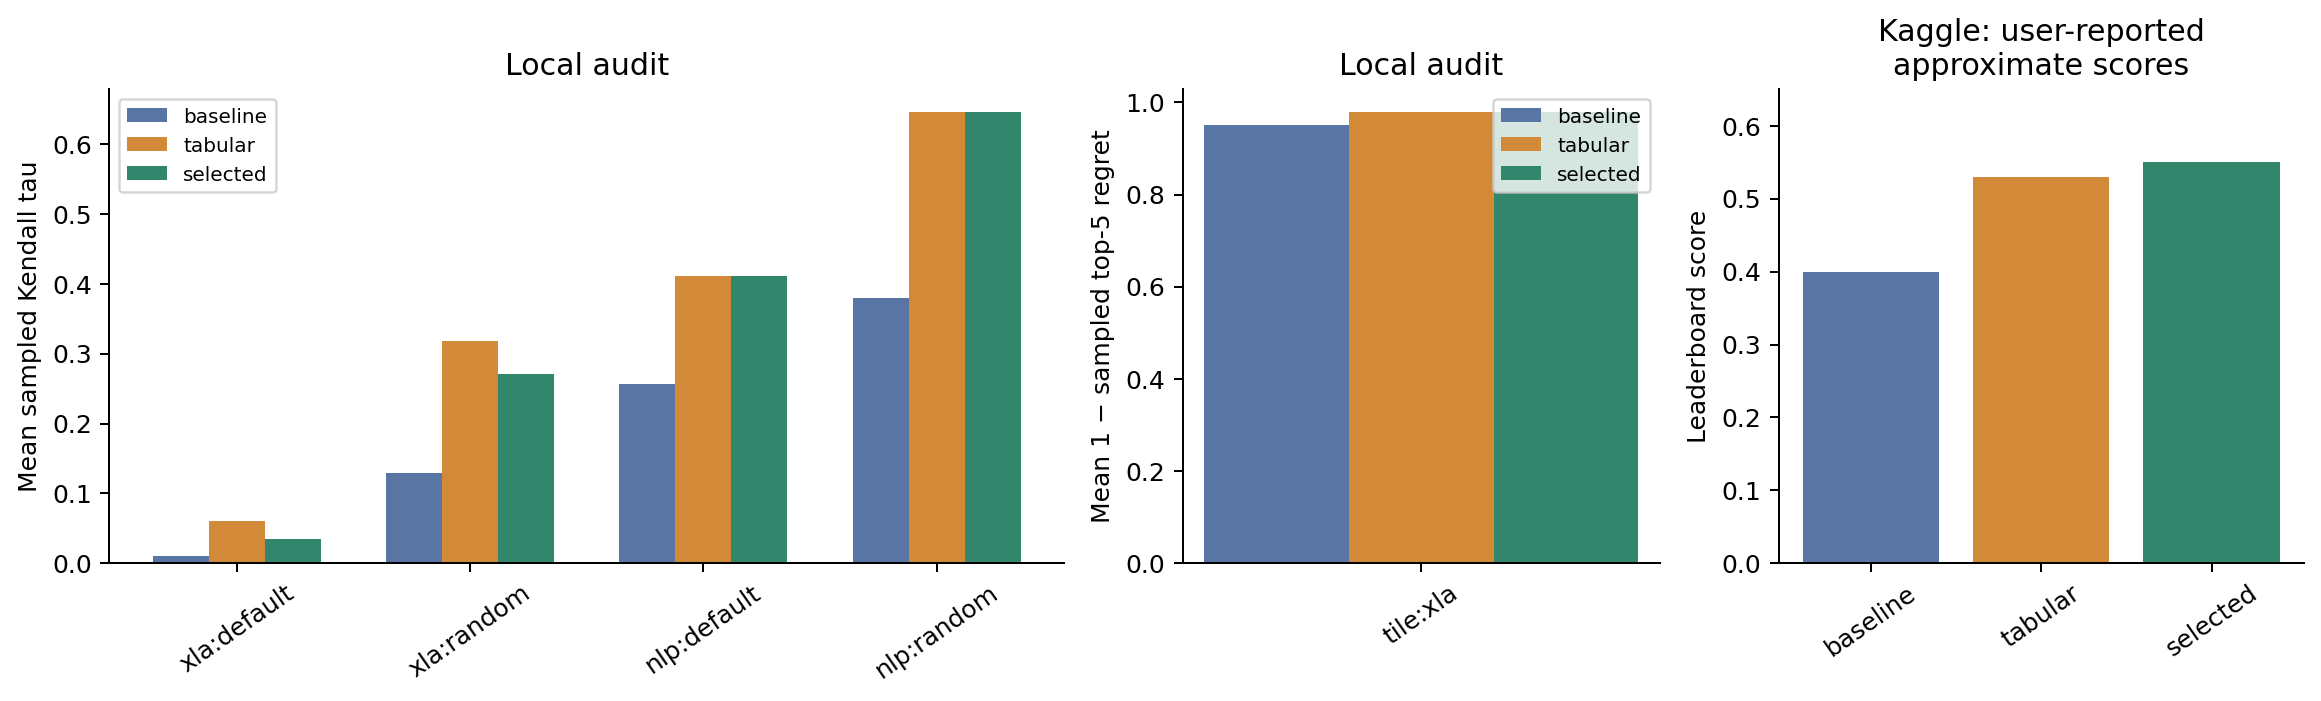

In [15]:
REPORT_DIR=v4_report.generate(REFERENCE_DIR,OUTPUT_DIR,NPZ_ROOT,
    kaggle={'baseline':0.40,'tabular':0.53,'selected':0.55})
print('Report figures, captions and tables:',REPORT_DIR)
from IPython.display import display, Image
display(Image(filename=str(REPORT_DIR/'06_final_comparison.png')))


## 6. Fixed experimental plan

| Track | New experiments | Control |
|---|---|---|
| NLP default/random | All eligible training graphs at 256 then 384 configs | V3 deeper HGB at 128 graphs |
| Tile | 640 / 1,280 / 2,560 / 5,120 / all eligible graphs at 256 configs, then 384 at largest size admitting both counts | V3 deeper HGB at 320 graphs |
| XLA default/random | Same winning GNN, graph geometry and training examples; 40 epochs / patience 10 | V3 20 epochs / patience 5 |
| XLA blend | 0 / .25 / .5 / .75 / 1 GNN weights using saved dev predictions | Exact v3 selected blend |

Each size must pass a matrix estimate and a measured 10-iteration HGB pilot. A skipped
size is logged with the resource reason; **“all data” is not promised on standard RAM**.
Training graphs/configuration samples are nested relative to v3. Dev graphs stay excluded.
The 384-config comparison uses the same graphs as its 256-config control.

Screen with seed 42 on both folds; confirm only the strongest eligible new recipe per
collection with seeds 137 and 2026. The GNN change is a combined training-budget change,
not an architecture ablation, and is trained fresh with the same seed. Existing v3 fits
are never rerun. Interrupted v4 GNN jobs resume their saved epoch/optimizer/RNG state.

A new system must improve the development mean by at least .002 (layout) or .0005
(tile) and must not reduce either fold relative to **v3 selected**. Otherwise keep v3.
These are predeclared pragmatic thresholds, not significance tests. Development reuse
can overfit; official valid is an already-inspected audit. Audit labels never choose
the replacement. No automatic refit on dev/audit data is done after selection.

One worker, 5 GiB worker cap, 2 GiB system reserve, 1 GiB matrix bound, 4 GiB scratch,
8 GiB output, 4 GiB disk reserve. Pilots must leave extra memory headroom. The worker
guard is a monitored threshold, not a guarantee against sudden allocation spikes.
Scratch is removed at stage changes/exit; source NPZs and checkpoint models are retained.


In [16]:
plan=[]
for c in CONFIG['collections']:
    for e in v4_core.plans(REFERENCE_DIR,c,CONFIG):
        plan.append({'collection':c,'experiment':e['name'],'model':e['model'],
                     'graphs':e.get('graph_limit',e.get('train_graphs')) or 'all eligible',
                     'configs':e['configs'],'factor':e['stage']})
display(pd.DataFrame(plan))
print('Plus one 384-config trial per tabular collection at its largest graph set admitting both configuration counts.')
print('Two screening folds per recipe; up to one new recipe per collection gets all three seeds.')


,collection,experiment,model,graphs,configs,factor
0,layout:nlp:default,V4_T_gall_c256,hgb,all eligible,256,training graphs
1,layout:nlp:random,V4_T_gall_c256,hgb,all eligible,256,training graphs
2,tile:xla,V4_T_g640_c256,hgb,640,256,training graphs
3,tile:xla,V4_T_g1280_c256,hgb,1280,256,training graphs
4,tile:xla,V4_T_g2560_c256,hgb,2560,256,training graphs
5,tile:xla,V4_T_g5120_c256,hgb,5120,256,training graphs
6,tile:xla,V4_T_gall_c256,hgb,all eligible,256,training graphs
7,layout:xla:default,V4_G_longer,gnn,all eligible,256,training budget
8,layout:xla:random,V4_G_longer,gnn,all eligible,128,training budget


Plus one 384-config trial per tabular collection at its largest graph set admitting both configuration counts.
Two screening folds per recipe; up to one new recipe per collection gets all three seeds.


## 7. Run the continuation and request checkpoint downloads

The cell prints `SKIP`, `PREPARE`, `PILOT`, `RUN`, `LOCKED`, and `TEST`. Pilot timing
is only an approximate fit cost; it excludes feature extraction and test inference.
The study may need multiple Colab sessions. It does not keep a runtime alive artificially.

Every 30 minutes, at collection boundaries and on handled interruption, the notebook
creates a complete replacement ZIP and requests a browser download. **A “ZIP READY”
line proves the local archive was created, not that your computer received it.** Colab
downloads can queue until a cell stops. You can download the completed `.zip` from Files;
never use `.zip.tmp`. Match the byte size and verify it opens locally before disconnecting.
The reference v3 archive is embedded, so v4 backups are several hundred MB.

If you stop the cell once, let cleanup/checkpoint finish. A killed VM cannot run cleanup.
New VM: upload the latest completed v4 ZIP, set `RESTORE_ZIP`, then Run all. Same VM:
clear `RESTORE_ZIP`, leave the output folder intact and rerun this cell.


In [17]:
def download_checkpoint(path):
    print('Backup path:',path,'| bytes:',Path(path).stat().st_size)
    if AUTO_DOWNLOAD_CHECKPOINTS:
        try:
            from google.colab import files
            files.download(str(path))
        except ImportError:print('Outside Colab: copy the ZIP from this path.')
        except Exception as exc:print('Download request failed:',exc,'— download manually from Files.')
    print('Verify a completed ZIP in your computer Downloads; a request is not delivery.')

RESULTS_ZIP=v4_controller.run(NPZ_ROOT,OUTPUT_DIR,SCRATCH_DIR,RUNTIME_DIR,CONFIG,
                             on_checkpoint=download_checkpoint)


RESUME CHECK: 0 new fits complete; at most 44 planned before resource/screening exclusions. V3 fits are reused.
PREPARE layout:nlp:default, fold 0: 186 training graphs
  still running: 0.8 min, worker 0.23 GiB
  still running: 1.5 min, worker 0.18 GiB
  still running: 2.3 min, worker 0.22 GiB
  still running: 3.0 min, worker 0.22 GiB
  still running: 3.8 min, worker 0.21 GiB
  still running: 4.5 min, worker 0.23 GiB
  still running: 5.3 min, worker 0.23 GiB
PILOT V4_T_gall_c256: 1.13 GiB; rough fit 2.4 min/job (excludes preparation/evaluation)
RUN layout:nlp:default | V4_T_gall_c256 | fold 0 seed 42 | trial [1/2]
  still running: 0.8 min, worker 1.04 GiB
  still running: 1.5 min, worker 1.00 GiB
PROGRESS: 1 new fits complete (upper bound 44; audit/inference separate)
PREPARE layout:nlp:default, fold 1: 186 training graphs
  still running: 0.8 min, worker 0.20 GiB
  still running: 1.5 min, worker 0.22 GiB
  still running: 2.3 min, worker 0.22 GiB
  still running: 3.0 min, worker 0.22 Gi

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Verify a completed ZIP in your computer Downloads; a request is not delivery.
  still running: 2.5 min, worker 1.41 GiB
PROGRESS: 4 new fits complete (upper bound 44; audit/inference separate)
SKIP layout:nlp:default V4_T_gall_c384 fold 0 seed 42 trial [1/6]
PREPARE layout:nlp:default, fold 0: 186 training graphs
  still running: 0.8 min, worker 0.24 GiB
  still running: 1.5 min, worker 0.23 GiB
  still running: 2.3 min, worker 0.24 GiB
  still running: 3.0 min, worker 0.21 GiB
  still running: 3.8 min, worker 0.22 GiB
  still running: 4.5 min, worker 0.23 GiB
  still running: 5.3 min, worker 0.23 GiB
RUN layout:nlp:default | V4_T_gall_c384 | fold 0 seed 137 | trial [2/6]
  still running: 0.8 min, worker 1.46 GiB
  still running: 1.5 min, worker 1.45 GiB
  still running: 2.3 min, worker 1.41 GiB
PROGRESS: 5 new fits complete (upper bound 44; audit/inference separate)
RUN layout:nlp:default | V4_T_gall_c384 | fold 0 seed 2026 | trial [3/6]
  still running: 0.8 min, worker 1.48 GiB
  sti

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

Verify a completed ZIP in your computer Downloads; a request is not delivery.
TEST 878/894: layout:nlp:random:71b79ca6db513e7979c3702c595150c2
TEST 879/894: layout:nlp:random:171b0513d8874a427ccfa46d136fbadc
TEST 880/894: layout:nlp:random:016ac66a44a906a695afd2228509046a
TEST 881/894: layout:nlp:random:58cc2e418c3a8a19b871e15964b534ad
TEST 882/894: layout:nlp:random:b2fdde3b72980907578648774101543e
TEST 883/894: layout:nlp:random:29886a50d55cfe77a9497bc906c76ce9
TEST 884/894: layout:nlp:random:7105451001e119f65b66570d170b94a8
TEST 885/894: layout:nlp:random:d15316c12eefdef1ba549eb433797f77
TEST 886/894: layout:nlp:random:7f6284ebe027b1e9a3850fc703858a59
TEST 887/894: layout:nlp:random:38524e2ff135ded55b5286407e7af6b7
TEST 888/894: layout:nlp:random:6c1101f6231f4d1722c3b9f6d1e25026
TEST 889/894: layout:nlp:random:492c7a94d559aa4a88769142d2a68362
TEST 890/894: layout:nlp:random:60880ed76de53f4d7a1b960b24f20f7d
TEST 891/894: layout:nlp:random:23559853d9702baaaacbb0c83fd32266
TEST 892/894

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Verify a completed ZIP in your computer Downloads; a request is not delivery.


## 8. Review status, export figures and download the final bundle

`complete` means all planned/admitted work and submission export finished. `paused`
means restore/resume is required. Errors preserve a checkpoint and identify the log.
Resource exclusions are listed explicitly. The report pack is useful even when paused.

Final CSVs: `submission_v3_reference.csv` (unchanged benchmark),
`submission_tabular_update_only.csv` (preserves XLA v3 rows), and
`submission_selected.csv` (all development-accepted changes). They may be identical
if nothing passes the replacement rule. Do not submit until submission status says complete.
`submission_provenance.csv` records which collection/model produced each row.


In [18]:
state=v4_core.read(OUTPUT_DIR/'run_state.json')
print('Overall:',state['status'])
display(pd.DataFrame(state['collections'].items(),columns=['collection','status']))
for c in CONFIG['collections']:
    d=OUTPUT_DIR/c.replace(':','_')
    if (d/'selection_lock.json').exists():
        lock=v4_core.read(d/'selection_lock.json')
        print(c,lock['components'],'| development gain:',lock['gain_vs_v3'])
    if (d/'system_audit_gains.csv').exists():display(pd.read_csv(d/'system_audit_gains.csv'))
    for p in d.glob('admission/*/decision.json'):
        if not v4_core.read(p)['admitted']:print('Resource exclusion:',p.parent.name,v4_core.read(p)['reason'])
if (OUTPUT_DIR/'submission_status.json').exists():print(v4_core.read(OUTPUT_DIR/'submission_status.json'))
REPORT_DIR=v4_report.generate(REFERENCE_DIR,OUTPUT_DIR,NPZ_ROOT)
from study_controller import make_bundle
RESULTS_ZIP=make_bundle(OUTPUT_DIR,CONFIG['disk_reserve_gib'])
download_checkpoint(RESULTS_ZIP)
print('Send back this results ZIP. It contains code, models, predictions, decisions, six report figures and source tables.')


Overall: complete


,collection,status
0,layout:nlp:default,complete
1,layout:nlp:random,complete
2,tile:xla,complete
3,layout:xla:default,complete
4,layout:xla:random,complete


layout:nlp:default {'T_deeper_hgb': 1.0} | development gain: 0.0


,experiment,reference,baseline_score,candidate_score,mean_paired_gain,score_points,relative_gain_pct,graphs,graph_win_fraction,bootstrap_low,bootstrap_high,uncertainty_note
0,V4_T_gall_c384,v3_selected,0.411263,0.423521,0.012258,1.225829,2.980648,20,0.4,-0.001465,0.030434,exploratory graph bootstrap; no multiplicity c...
1,v3_selected,v3_selected,0.411263,0.411263,0.000000,0.000000,0.000000,20,0.0,0.000000,0.000000,exploratory graph bootstrap; no multiplicity c...
2,v4_selected,v3_selected,0.411263,0.411263,0.000000,0.000000,0.000000,20,0.0,0.000000,0.000000,exploratory graph bootstrap; no multiplicity c...


layout:nlp:random {'V4_T_gall_c384': 1.0} | development gain: 0.016252803955162376


...

,experiment,reference,baseline_score,candidate_score,mean_paired_gain,score_points,relative_gain_pct,graphs,graph_win_fraction,bootstrap_low,bootstrap_high,uncertainty_note
0,v3_selected,v3_selected,0.271156,0.271156,0.0,0.0,0.0,7,0.0,0.0,0.0,exploratory graph bootstrap; no multiplicity c...
1,v4_selected,v3_selected,0.271156,0.271156,0.0,0.0,0.0,7,0.0,0.0,0.0,exploratory graph bootstrap; no multiplicity c...


{'status': 'complete', 'rows': 894, 'changed_collections': ['layout:nlp:random'], 'note': 'Candidate, not submitted to Kaggle'}
Backup path: /content/sc4000_gnn_v4_results.zip | bytes: 445242144


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Verify a completed ZIP in your computer Downloads; a request is not delivery.
Send back this results ZIP. It contains code, models, predictions, decisions, six report figures and source tables.


## Report structure and attribution

Use approximately six main figures: pipeline; dataset/coverage; component ablations;
coverage scores; training-data grids; final comparison. Two compact tables describe
setup/resources and findings/decisions. Appendix plots add v4 results. `report/CAPTIONS.md`
and `report/REPORT_GUIDE.md` explain evidence scope and limitations. This is not the final
ten-page report. V2 provenance/earlier experiments remain in the project evidence folder.

The established GraphSAGE architecture, embeddings and pairwise loss are not new inventions.
This is an independent extension of the project's v3 implementation. Competitor code,
weights and predictions are not included. Cite the project's prior-work record and the
original GraphSAGE paper when writing the report. No improvement to 0.59 is guaranteed.
